In [3]:
%cd C:\Mestrado\Graph_Pruning\prodigy

C:\Mestrado\Graph_Pruning\prodigy


c:\Mestrado\Graph_Pruning\.venv_prodigy\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [4]:

from pathlib import Path
import sys
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Caminhos do projeto
PROJECT_ROOT = Path(r"C:\Mestrado\Graph_Pruning")
REPO_ROOT = PROJECT_ROOT / "prodigy"
DATA_ROOT = REPO_ROOT / "data" / "datasets"

CHECKPOINT_DIR = (
    REPO_ROOT / "state" / "Wiki_PT_PRODIGY_02_10_2026_16_26_51"
)

# Permitir imports do PRODIGY
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Dispositivo
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("Repositório:", REPO_ROOT)
print("Dataset:", DATA_ROOT / "FB15K-237")
print("Checkpoint:", CHECKPOINT_DIR)
print("Dispositivo:", device)
print("CUDA disponível:", torch.cuda.is_available())


Repositório: C:\Mestrado\Graph_Pruning\prodigy
Dataset: C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237
Checkpoint: C:\Mestrado\Graph_Pruning\prodigy\state\Wiki_PT_PRODIGY_02_10_2026_16_26_51
Dispositivo: cuda:0
CUDA disponível: True


In [7]:
CONFIG = {
    "dataset": "FB15K-237",
    "layers": "S2,UX,M2",
    "task_name": "cls_nm",
    "n_way": 3,
    "n_shot": 3,
    "n_query": 3,
    "batch_size": 1,
    "dataset_len_cap": 510,
    "val_len_cap": 100,
    "test_len_cap": 500,
    "train_cap": 10,
    "num_workers": 0,
    "emb_dim": 256,
    "input_dim": 770,
}

print(pd.Series(CONFIG, name="Valor"))

dataset            FB15K-237
layers              S2,UX,M2
task_name             cls_nm
n_way                      3
n_shot                     3
n_query                    3
batch_size                 1
dataset_len_cap          510
val_len_cap              100
test_len_cap             500
train_cap                 10
num_workers                0
emb_dim                  256
input_dim                770
Name: Valor, dtype: object


In [8]:
import torch

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", DEVICE)

Dispositivo: cuda:0


In [9]:
from data.data_loader_wrapper import get_dataset_wrap

datasets = get_dataset_wrap(
    root=str(DATA_ROOT),
    dataset=CONFIG["dataset"],
    n_hop=1,
    bert="sentence-transformers/all-mpnet-base-v2",
    bert_device=str(DEVICE),
    node_graph=False,
)

print("Dataset carregado:", type(datasets).__name__)
print("Dataset:", CONFIG["dataset"])

Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\relation2id.json
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\entity2id.json


100%|██████████| 200/200 [00:00<00:00, 2341.14it/s]


Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\graph.pt
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\graph.pt
MODEL NAME:  sentence-transformers/all-mpnet-base-v2
Loading text features from  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\preproc_text_feats\text_feats_sentence-transformers_all-mpnet-base-v2_.pkl
Loading adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\FB15K-237_adj.pt
Loaded adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\FB15K-237_adj.pt
Dataset carregado: KGSubgraphDataset
Dataset: FB15K-237


In [18]:
import zipfile
import pickletools

cache_file = os.path.join(
    DATA_ROOT,
    "Wiki",
    "preproc_text_feats",
    "text_feats_sentence-transformers_all-mpnet-base-v2_.pkl"
)

with zipfile.ZipFile(cache_file, "r") as archive:

    data_pickle = next(
        name for name in archive.namelist()
        if name.endswith("/data.pkl")
    )

    print("Arquivo interno:", data_pickle)
    print("\nPrimeiras operações do pickle:\n")

    with archive.open(data_pickle, "r") as f:

        for i, (opcode, argument, position) in enumerate(
            pickletools.genops(f)
        ):
            if i >= 100:
                break

            if isinstance(argument, str) and len(argument) > 100:
                argument = argument[:100] + "..."

            print(
                f"{i:03d} | "
                f"{opcode.name:20s} | "
                f"{str(argument)[:120]}"
            )

Arquivo interno: text_feats_sentence-transformers_all-mpnet-base-v2_/data.pkl

Primeiras operações do pickle:

000 | PROTO                | 2
001 | EMPTY_LIST           | None
002 | BINPUT               | 0
003 | MARK                 | None
004 | BINUNICODE           | UB Conquense
005 | BINPUT               | 1
006 | BINUNICODE           | The battle on the Slaak between the Dutch and Spanish fleets during the night of 12-13 September 163...
007 | BINPUT               | 2
008 | BINUNICODE           | Denmark Historical Society
009 | BINPUT               | 3
010 | BINUNICODE           | Thomas Muirhead Flett
011 | BINPUT               | 4
012 | BINUNICODE           | Guillermo Díaz Gómez
013 | BINPUT               | 5
014 | BINUNICODE           | Kuurola
015 | BINPUT               | 6
016 | BINUNICODE           | Albatross
017 | BINPUT               | 7
018 | BINUNICODE           | 1999 Austrian Badminton Championships U19 – women's singles
019 | BINPUT               | 8
020 | BINUNICO

In [19]:
import zipfile
import pickletools
from collections import deque, Counter

tail = deque(maxlen=80)
op_counts = Counter()

with zipfile.ZipFile(cache_file, "r") as archive:

    data_pickle = next(
        name for name in archive.namelist()
        if name.endswith("/data.pkl")
    )

    info = archive.getinfo(
        "text_feats_sentence-transformers_all-mpnet-base-v2_/data/0"
    )

    print("=== ARMAZENAMENTO DOS EMBEDDINGS ===")
    print(f"Tamanho: {info.file_size / 1024**3:.3f} GB")
    print(f"Compressão ZIP: {info.compress_type}")
    print(f"Offset no arquivo: {info.header_offset}")

    print("\n=== FINAL DO PICKLE ===")

    with archive.open(data_pickle, "r") as f:

        for opcode, argument, position in pickletools.genops(f):

            op_counts[opcode.name] += 1

            if isinstance(argument, str) and len(argument) > 100:
                argument = argument[:100] + "..."

            tail.append((
                position,
                opcode.name,
                argument
            ))

print("\nQuantidade de operações:", sum(op_counts.values()))
print("Quantidade de textos/operações BINUNICODE:", op_counts["BINUNICODE"])

print("\nÚltimas operações:\n")

for position, name, argument in tail:
    print(f"{position:12d} | {name:20s} | {str(argument)[:120]}")

=== ARMAZENAMENTO DOS EMBEDDINGS ===
Tamanho: 13.844 GB
Compressão ZIP: 0
Offset no arquivo: 163713774

=== FINAL DO PICKLE ===

Quantidade de operações: 9687277
Quantidade de textos/operações BINUNICODE: 4838679

Últimas operações:

   163712886 | LONG_BINPUT          | 4838656
   163712891 | BINUNICODE           | Pasi Kumbang
   163712908 | LONG_BINPUT          | 4838657
   163712913 | BINUNICODE           | Aicha vorm Wald
   163712933 | LONG_BINPUT          | 4838658
   163712938 | BINUNICODE           | Prizren
   163712950 | LONG_BINPUT          | 4838659
   163712955 | BINUNICODE           | Welcome Ussery Creek
   163712980 | LONG_BINPUT          | 4838660
   163712985 | BINUNICODE           | Gazdzicki Sound
   163713005 | LONG_BINPUT          | 4838661
   163713010 | BINUNICODE           | Hans John
   163713024 | LONG_BINPUT          | 4838662
   163713029 | BINUNICODE           | Phillip Trenkler
   163713050 | LONG_BINPUT          | 4838663
   163713055 | BINUNICODE      

In [20]:
import os
import struct
import zipfile
import numpy as np
import psutil

storage_name = (
    "text_feats_sentence-transformers_all-mpnet-base-v2_/data/0"
)

# Localiza o armazenamento dentro do arquivo ZIP
with zipfile.ZipFile(cache_file, "r") as archive:
    info = archive.getinfo(storage_name)

    assert info.compress_type == zipfile.ZIP_STORED, (
        "O armazenamento está comprimido."
    )

    header_offset = info.header_offset

# Lê o cabeçalho ZIP local para descobrir onde começam os dados
with open(cache_file, "rb") as f:
    f.seek(header_offset)
    header = f.read(30)

fields = struct.unpack("<IHHHHHIIIHH", header)

signature = fields[0]
filename_length = fields[-2]
extra_length = fields[-1]

assert signature == 0x04034B50, "Cabeçalho ZIP inválido."

data_offset = (
    header_offset + 30 + filename_length + extra_length
)

# Dimensões identificadas no pickle
num_embeddings = 4_838_882
embedding_dim = 768

expected_bytes = num_embeddings * embedding_dim * 4

assert info.file_size == expected_bytes, (
    f"Tamanho inesperado: {info.file_size} != {expected_bytes}"
)

# Mapeamento do armazenamento, sem carregar o tensor inteiro
wiki_embeddings = np.memmap(
    cache_file,
    dtype=np.float32,
    mode="r",
    offset=data_offset,
    shape=(num_embeddings, embedding_dim)
)

print("Memória mapeada com sucesso!")
print("Shape:", wiki_embeddings.shape)
print("Dtype:", wiki_embeddings.dtype)

print("\nPrimeiros valores do primeiro embedding:")
print(wiki_embeddings[0, :5])

print("\nRAM disponível:")
print(f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

Memória mapeada com sucesso!
Shape: (4838882, 768)
Dtype: float32

Primeiros valores do primeiro embedding:
[-0.01332631  0.00380339  0.0325775  -0.03386529 -0.01858045]

RAM disponível:
3.71 GB


In [22]:
import gc
import torch
import psutil

# Liberar o mapeamento NumPy do teste anterior
del wiki_embeddings
gc.collect()

memory_before = psutil.virtual_memory().available

# Carregar textos e tensor com memória mapeada
texts, embeddings = torch.load(
    cache_file,
    mmap=True,
    weights_only=False
)

memory_after = psutil.virtual_memory().available

print("=== ESTRUTURA DO CACHE ===")
print("Tipo de texts:", type(texts))
print("Quantidade de textos:", len(texts))
print("Shape dos embeddings:", tuple(embeddings.shape))
print("Dtype:", embeddings.dtype)

print("\n=== CONSISTÊNCIA ===")
print("Mesma quantidade:", len(texts) == embeddings.shape[0])
print("Primeiros textos:", texts[:5])
print("Últimos textos:", texts[-5:])

print("\n=== MEMÓRIA ===")
print(f"Disponível antes: {memory_before / 1024**3:.2f} GB")
print(f"Disponível depois: {memory_after / 1024**3:.2f} GB")
print(f"Consumo aproximado: {(memory_before-memory_after) / 1024**2:.2f} MB")

=== ESTRUTURA DO CACHE ===
Tipo de texts: <class 'list'>
Quantidade de textos: 4838882
Shape dos embeddings: (4838882, 768)
Dtype: torch.float32

=== CONSISTÊNCIA ===
Mesma quantidade: True
Primeiros textos: ['UB Conquense', 'The battle on the Slaak between the Dutch and Spanish fleets during the night of 12-13 September 1631', 'Denmark Historical Society', 'Thomas Muirhead Flett', 'Guillermo Díaz Gómez']
Últimos textos: ['Ion Mușlea', 'Hilal Areeha', '鮮坑夫の酔狂 暴行して殴打さる', 'Marshfield', 'La boutique']

=== MEMÓRIA ===
Disponível antes: 3.43 GB
Disponível depois: 3.02 GB
Consumo aproximado: 415.57 MB


In [26]:
import os
import sqlite3
import zipfile
import struct
import numpy as np
import torch
import gc
import psutil


class LazyWikiTextEmbeddings:
    """
    Recupera embeddings do cache Wiki sob demanda.

    O índice texto -> posição fica no SQLite.
    O tensor de embeddings é acessado via NumPy memmap.
    """

    def __init__(
        self,
        cache_file,
        index_path,
        num_embeddings=4_838_882,
        embedding_dim=768
    ):
        self.cache_file = cache_file
        self.index_path = index_path
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim

        # Conexão somente para leitura
        self.conn = sqlite3.connect(
            f"file:{index_path.replace(os.sep, '/')}?mode=ro",
            uri=True
        )
        self.conn.execute("PRAGMA query_only = ON")

        # Localizar o armazenamento interno do tensor no ZIP
        storage_name = (
            "text_feats_sentence-transformers_all-mpnet-base-v2_/data/0"
        )

        with zipfile.ZipFile(cache_file, "r") as archive:
            info = archive.getinfo(storage_name)

            if info.compress_type != zipfile.ZIP_STORED:
                raise ValueError("O armazenamento está comprimido.")

            header_offset = info.header_offset

            expected_size = (
                num_embeddings * embedding_dim * np.dtype(np.float32).itemsize
            )

            if info.file_size != expected_size:
                raise ValueError(
                    f"Tamanho inesperado do tensor: {info.file_size}"
                )

        # Descobrir o início dos dados do tensor no arquivo
        with open(cache_file, "rb") as f:
            f.seek(header_offset)
            header = f.read(30)

        fields = struct.unpack("<IHHHHHIIIHH", header)

        if fields[0] != 0x04034B50:
            raise ValueError("Cabeçalho ZIP inválido.")

        filename_length = fields[-2]
        extra_length = fields[-1]

        data_offset = (
            header_offset + 30 + filename_length + extra_length
        )

        # Mapear o tensor sem carregá-lo integralmente na RAM
        self.embeddings = np.memmap(
            cache_file,
            dtype=np.float32,
            mode="r",
            offset=data_offset,
            shape=(num_embeddings, embedding_dim)
        )

        # Verificar se o índice SQLite está completo
        count = self.conn.execute(
            "SELECT COUNT(*) FROM text_index"
        ).fetchone()[0]

        if count == 0:
            raise ValueError("Índice SQLite vazio.")

        print("LazyWikiTextEmbeddings inicializado.")
        print(f"Embeddings: {num_embeddings:,}")
        print(f"Dimensão: {embedding_dim}")
        print(f"Textos indexados: {count:,}")

    def lookup_indices(self, text_batch, chunk_size=500):
        """
        Consulta as posições dos textos no SQLite.
        Mantém a ordem e as repetições da entrada.
        """

        unique_texts = list(dict.fromkeys(text_batch))
        lookup = {}

        for start in range(0, len(unique_texts), chunk_size):
            batch = unique_texts[start:start + chunk_size]

            placeholders = ",".join(["?"] * len(batch))

            query = f"""
                SELECT text, row_id
                FROM text_index
                WHERE text IN ({placeholders})
            """

            for text, row_id in self.conn.execute(query, batch):
                lookup[text] = row_id

        missing = [
            text for text in unique_texts
            if text not in lookup
        ]

        if missing:
            raise KeyError(
                f"Texto não encontrado no índice: {missing[0]}"
            )

        return [lookup[text] for text in text_batch]

    def get_many(self, text_batch):
        """
        Recupera os embeddings de uma lista de textos.
        Retorna um tensor Float32 na CPU.
        """

        if len(text_batch) == 0:
            return torch.empty(
                (0, self.embedding_dim),
                dtype=torch.float32
            )

        indices = self.lookup_indices(text_batch)

        # A indexação avançada materializa somente as linhas solicitadas
        selected = np.array(
            self.embeddings[indices],
            dtype=np.float32,
            copy=True
        )

        return torch.from_numpy(selected)

    def close(self):
        self.conn.close()

In [27]:
wiki_embedding_store = LazyWikiTextEmbeddings(
    cache_file=cache_file,
    index_path=index_path
)

# Reutilizar os textos de teste anteriores
test_texts = [
    "UB Conquense",
    "The battle on the Slaak between the Dutch and Spanish fleets during the night of 12-13 September 1631",
    "Ulrike Schmetz",
    "La boutique"
]

recovered = wiki_embedding_store.get_many(test_texts)

print("\nShape:", recovered.shape)
print("Dtype:", recovered.dtype)

# Comparar com o tensor original ainda disponível
test_indices = wiki_embedding_store.lookup_indices(test_texts)
expected = embeddings[torch.tensor(test_indices)]

assert torch.equal(recovered, expected)

print("\nRecuperação lazy validada!")
print("Todos os embeddings são idênticos aos originais.")

LazyWikiTextEmbeddings inicializado.
Embeddings: 4,838,882
Dimensão: 768
Textos indexados: 4,398,233

Shape: torch.Size([4, 768])
Dtype: torch.float32

Recuperação lazy validada!
Todos os embeddings são idênticos aos originais.


In [28]:
del texts
del embeddings
del expected
del recovered

gc.collect()

print(
    f"RAM disponível: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

RAM disponível: 3.58 GB


In [29]:
import inspect
import data.kg as kg

from data.dataset import KGSubgraphDataset

print("=== CLASSES ===")

print(
    "KGSubgraphDataset em data.kg:",
    kg.KGSubgraphDataset
)

print(
    "É a mesma classe:",
    kg.KGSubgraphDataset is KGSubgraphDataset
)

print(
    "\nClasse de features:",
    kg.SubgraphFewshotDatasetWithTextFeats
)

print("\n=== ARQUIVOS DE ORIGEM ===")

print(
    "KGSubgraphDataset:",
    inspect.getsourcefile(KGSubgraphDataset)
)

print(
    "SubgraphFewshotDatasetWithTextFeats:",
    inspect.getsourcefile(
        kg.SubgraphFewshotDatasetWithTextFeats
    )
)

print("\n=== REFERÊNCIA USADA PELO get_kg_dataset ===")

print(
    kg.get_kg_dataset.__globals__.get("KGSubgraphDataset")
)

=== CLASSES ===
KGSubgraphDataset em data.kg: <class 'data.dataset.KGSubgraphDataset'>
É a mesma classe: True

Classe de features: <class 'data.load_kg_dataset.SubgraphFewshotDatasetWithTextFeats'>

=== ARQUIVOS DE ORIGEM ===
KGSubgraphDataset: c:\Mestrado\Graph_Pruning\prodigy\data\dataset.py
SubgraphFewshotDatasetWithTextFeats: c:\Mestrado\Graph_Pruning\prodigy\data\load_kg_dataset.py

=== REFERÊNCIA USADA PELO get_kg_dataset ===
<class 'data.dataset.KGSubgraphDataset'>


In [32]:
import torch
from torch_geometric.data import Data
import data.kg as kg

OriginalKGSubgraphDataset = kg.KGSubgraphDataset


class LazyWikiKGSubgraphDataset(OriginalKGSubgraphDataset):

    def __init__(
        self,
        kg_dataset,
        neighbor_sampler,
        sampler_type,
        node_graph
    ):

        # Preservar o comportamento original para outros datasets
        if kg_dataset.dataset != "Wiki":
            super().__init__(
                kg_dataset,
                neighbor_sampler,
                sampler_type,
                node_graph
            )
            return

        self.sampler_type = sampler_type
        self.neighbor_sampler = neighbor_sampler

        self.name = kg_dataset.dataset
        self.kg_dataset = kg_dataset

        self.ssp_graph = kg_dataset.ssp_graph
        self.pyg_graph = kg_dataset.graph

        self.hop = kg_dataset.hop
        self.kind = kg_dataset.kind
        self.node_graph = node_graph

        # Armazenamento lazy já validado
        self.embedding_store = wiki_embedding_store

        # Não materializar as features globais
        self.pyg_graph.x = None
        self.pyg_graph.edge_attr_feat = None

        # Identificar os atributos estruturais
        self.node_attrs = [
            key
            for key, value in self.pyg_graph
            if self.pyg_graph.is_node_attr(key)
        ]

        self.edge_attrs = [
            key
            for key, value in self.pyg_graph
            if self.pyg_graph.is_edge_attr(key)
            and key != "edge_index"
        ]

        # x será criado sob demanda em cada subgrafo
        if "x" not in self.node_attrs:
            self.node_attrs.append("x")

        print("LazyWikiKGSubgraphDataset inicializado.")
        print("Node attrs:", self.node_attrs)
        print("Edge attrs:", self.edge_attrs)

    def _node_texts(self, node_ids):

        texts = []

        for node_id in node_ids:

            node_id = int(node_id)

            entity = self.kg_dataset.id2entity.get(
                node_id,
                str(node_id)
            )

            text = self.kg_dataset.text_dict.get(
                entity,
                entity
            )

            texts.append(text)

        return texts

    def _relation_texts(self, relation_ids):

        texts = []

        for relation_id in relation_ids:

            relation_id = int(relation_id)

            relation = self.kg_dataset.id2relation.get(
                relation_id,
                str(relation_id)
            )

            text = self.kg_dataset.text_dict.get(
                relation,
                relation
            )

            texts.append(text)

        return texts

    def _build_subgraph(
        self,
        node_list,
        edge_index,
        edge_id,
        center_node_idx
    ):

        # IDs originais dos nós
        node_ids_tensor = self.pyg_graph.x_id[node_list]
        node_ids = node_ids_tensor.reshape(-1).tolist()

        # Recuperar somente as features dos nós solicitados
        node_texts = self._node_texts(node_ids)

        node_features = self.embedding_store.get_many(
            node_texts
        )

        # IDs das relações presentes no subgrafo
        edge_id = torch.as_tensor(
            edge_id,
            dtype=torch.long
        )

        relation_ids = (
            self.pyg_graph.edge_attr[edge_id]
            .reshape(-1)
            .tolist()
        )

        # Recuperar somente as features das relações solicitadas
        relation_texts = self._relation_texts(
            relation_ids
        )

        edge_features = self.embedding_store.get_many(
            relation_texts
        )

        data = {
            "center_node_idx": center_node_idx,
            "edge_index": edge_index,
            "num_nodes": len(node_ids),
            "x_id": node_ids_tensor,
            "x": node_features,
            "edge_attr": edge_features
        }

        # Preservar eventuais atributos estruturais adicionais
        for key in self.node_attrs:

            if key in ["x", "x_id"]:
                continue

            data[key] = self.pyg_graph[key][node_list]

        for key in self.edge_attrs:

            if key == "edge_attr":
                continue

            data[key] = self.pyg_graph[key][edge_id]

        return Data(**data)

    def get_subgraph(self, edge_idx):

        rev = False

        if edge_idx < 0:
            edge_idx = -edge_idx - 1
            rev = True

        e = self.pyg_graph.edge_index[:, edge_idx].tolist()

        if rev:
            e = [e[1], e[0]]

        node_list, edge_index, edge_id = (
            self.neighbor_sampler.sample_node(e)
        )

        # Remover a aresta central
        edge_mask = edge_id != edge_idx

        edge_index = edge_index[:, edge_mask]
        edge_id = edge_id[edge_mask]

        return self._build_subgraph(
            node_list=node_list,
            edge_index=edge_index,
            edge_id=edge_id,
            center_node_idx=e
        )

    def get_node_subgraph(self, node_idx):

        node_list, edge_index, edge_id = (
            self.neighbor_sampler.sample_node(node_idx)
        )

        graph = self._build_subgraph(
            node_list=node_list,
            edge_index=edge_index,
            edge_id=edge_id,
            center_node_idx=node_idx
        )

        # Preservar o comportamento original
        graph.edge_index = torch.cat(
            [graph.edge_index, graph.edge_index.flip(0)],
            dim=1
        )

        graph.edge_attr = torch.cat(
            [graph.edge_attr, graph.edge_attr],
            dim=0
        )

        return graph

    def add_pooling_supernode(self, data):

        for key in self.node_attrs:

            value = data[key]

            if value is not None:
                data[key] = torch.cat(
                    [
                        value,
                        torch.zeros(
                            1,
                            *value.shape[1:],
                            dtype=value.dtype,
                            device=value.device
                        )
                    ],
                    dim=0
                )

        supernode_idx = data.num_nodes

        data.supernode = torch.tensor([supernode_idx])

        data.edge_index_supernode = torch.tensor(
            [[0, 1], [supernode_idx, supernode_idx]],
            dtype=torch.long
        )

        data.edge_index_from_supernode = torch.tensor(
            [[supernode_idx, supernode_idx], [0, 1]],
            dtype=torch.long
        )

        data.num_nodes += 1

    def add_node_pooling_supernode(self, data):

        for key in self.node_attrs:

            value = data[key]

            if value is not None:
                data[key] = torch.cat(
                    [
                        value,
                        torch.zeros(
                            1,
                            *value.shape[1:],
                            dtype=value.dtype,
                            device=value.device
                        )
                    ],
                    dim=0
                )

        supernode_idx = data.num_nodes

        data.supernode = torch.tensor([supernode_idx])

        data.edge_index_supernode = torch.tensor(
            [[0], [supernode_idx]],
            dtype=torch.long
        )

        data.edge_index_from_supernode = torch.tensor(
            [[supernode_idx], [0]],
            dtype=torch.long
        )

        data.num_nodes += 1

In [33]:
import os
import pickle
import psutil
import data.kg as kg

from data.data_loader_wrapper import get_dataset_wrap

# --------------------------------------------------
# 1. Preservar o método original
# --------------------------------------------------

text_features_class = kg.SubgraphFewshotDatasetWithTextFeats

if not hasattr(text_features_class, "_original_preprocess_text_feats"):
    text_features_class._original_preprocess_text_feats = (
        text_features_class._preprocess_text_feats
    )


# --------------------------------------------------
# 2. Substituir o carregamento de embeddings para Wiki
# --------------------------------------------------

def lazy_preprocess_text_feats(self, model_name):

    if self.dataset == "Wiki":

        text_dict_path = os.path.join(
            self.root,
            self.dataset,
            "text_features_web_scraped.pb"
        )

        print("Carregando dicionário textual do Wiki...")

        with open(text_dict_path, "rb") as f:
            self.text_dict = pickle.load(f)

        print(f"Textos disponíveis: {len(self.text_dict):,}")
        print("Embeddings serão recuperados sob demanda.")

        # A classe especializada não utiliza self.text_feats
        return None

    # Preservar o comportamento original dos demais datasets
    return text_features_class._original_preprocess_text_feats(
        self,
        model_name
    )


text_features_class._preprocess_text_feats = lazy_preprocess_text_feats


# --------------------------------------------------
# 3. Redirecionar a classe utilizada pelo get_kg_dataset
# --------------------------------------------------

kg.KGSubgraphDataset = LazyWikiKGSubgraphDataset


# --------------------------------------------------
# 4. Inicializar o Wiki
# --------------------------------------------------

print("=" * 70)
print("INICIALIZANDO DATASET WIKI")
print("=" * 70)

wiki_datasets = get_dataset_wrap(
    root=DATA_ROOT,
    dataset="Wiki",
    n_hop=1,
    bert="sentence-transformers/all-mpnet-base-v2",
    bert_device=DEVICE,
    node_graph=False
)


# --------------------------------------------------
# 5. Verificar estruturas
# --------------------------------------------------

print("\n" + "=" * 70)
print("VERIFICAÇÃO")
print("=" * 70)

print("Classe:", type(wiki_datasets).__name__)
print("Nome:", wiki_datasets.name)
print("Quantidade de nós:", wiki_datasets.pyg_graph.num_nodes)
print("Quantidade de arestas:", wiki_datasets.pyg_graph.edge_index.shape[1])
print("Shape de x:", wiki_datasets.pyg_graph.x)
print("Shape de x_id:", wiki_datasets.pyg_graph.x_id.shape)
print("Shape de edge_attr:", wiki_datasets.pyg_graph.edge_attr.shape)

print("\nRAM disponível:")
print(f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

INICIALIZANDO DATASET WIKI
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\relation2id.json
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\entity2id.json
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\graph.pt
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\graph.pt
Carregando dicionário textual do Wiki...
Textos disponíveis: 4,768,337
Embeddings serão recuperados sob demanda.
Loading adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\Wiki_adj.pt
Loaded adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\Wiki_adj.pt
LazyWikiKGSubgraphDataset inicializado.
Node attrs: ['x_id', 'x']
Edge attrs: ['edge_attr']

VERIFICAÇÃO
Classe: LazyWikiKGSubgraphDataset
Nome: Wiki
Quantidade de nós: 4838243
Quantidade de arestas: 5856692
Shape de x: None
Shape de x_id: torch.Size([4838243])
Shape de edge_attr: torch.Size([58566

In [34]:
import torch
import psutil

print("RAM antes:", 
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

# Recuperar somente um subgrafo
graph = wiki_datasets[0]

print("\n=== ESTRUTURA DO SUBGRAFO ===")

print("Tipo:", type(graph))
print("Nós:", graph.num_nodes)
print("Arestas:", graph.edge_index.shape[1])

print("\n=== FEATURES ===")

print("x:", graph.x.shape)
print("x_id:", graph.x_id.shape)
print("edge_attr:", graph.edge_attr.shape)

print("\n=== SUPERNÓ ===")

print("supernode:", graph.supernode)
print("edge_index_supernode:", graph.edge_index_supernode.shape)
print("edge_index_from_supernode:", graph.edge_index_from_supernode.shape)

# Verificações
assert graph.x.ndim == 2
assert graph.x.shape[1] == 768

assert graph.edge_attr.ndim == 2
assert graph.edge_attr.shape[1] == 768

assert graph.x.shape[0] == graph.num_nodes
assert graph.x_id.shape[0] == graph.num_nodes

assert torch.isfinite(graph.x).all()
assert torch.isfinite(graph.edge_attr).all()

assert graph.supernode.numel() == 1

print("\nTodas as verificações passaram!")

print("\nRAM depois:", 
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

RAM antes: 0.65 GB

=== ESTRUTURA DO SUBGRAFO ===
Tipo: <class 'torch_geometric.data.data.Data'>
Nós: 621
Arestas: 647

=== FEATURES ===
x: torch.Size([621, 768])
x_id: torch.Size([621])
edge_attr: torch.Size([647, 768])

=== SUPERNÓ ===
supernode: tensor([620])
edge_index_supernode: torch.Size([2, 2])
edge_index_from_supernode: torch.Size([2, 2])

Todas as verificações passaram!

RAM depois: 0.64 GB


In [35]:
import gc
import inspect
import psutil
import data.kg as kg

# Liberar o subgrafo de teste
del graph
gc.collect()

print("=== MEMÓRIA ===")

process = psutil.Process()

print(
    f"RAM disponível: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

print(
    f"RAM usada pelo Python: "
    f"{process.memory_info().rss / 1024**3:.2f} GB"
)

print("\n=== IMPLEMENTAÇÃO DE get_aug ===")

print(inspect.getsource(kg.get_aug))

=== MEMÓRIA ===
RAM disponível: 0.60 GB
RAM usada pelo Python: 2.44 GB

=== IMPLEMENTAÇÃO DE get_aug ===
def get_aug(aug_spec, node_feature_distribution=None):
    if not aug_spec:
        return Identity()
    augs = []
    for spec in aug_spec.split(","):
        if spec.startswith("ND"):
            augs.append(DropNode(float(spec[2:])))
        elif spec.startswith("NZ"):
            augs.append(ZeroNodeAttr(float(spec[2:])))
        elif spec.startswith("NR"):
            if node_feature_distribution is None:
                raise ValueError(f"node_feature_distribution not defined for RandomNodeAttr")
            augs.append(RandomNodeAttr(node_feature_distribution, float(spec[2:])))
        else:
            raise ValueError(f"Unknown augmentation {spec}")
    return Compose(augs)



In [36]:
from data.kg import get_kg_dataloader
import psutil

print(
    f"RAM disponível antes: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

wiki_train_loader = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name="cls_nm",
    split="train",
    node_split="",
    batch_size=1,
    n_way=3,
    n_shot=3,
    n_query=3,
    batch_count=1,
    root=DATA_ROOT,
    num_workers=0,
    aug="",
    aug_test=False,
    train_cap=10,
    linear_probe=False
)

print("\nDataLoader criado!")
print("Quantidade de batches:", len(wiki_train_loader))
print("Dataset:", wiki_datasets.name)

print(
    f"\nRAM disponível depois: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

RAM disponível antes: 0.58 GB
639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128

DataLoader criado!
Quantidade de batches: 1
Dataset: Wiki

RAM disponível depois: 0.56 GB


In [37]:
import gc
import torch
import psutil

print("RAM antes:", 
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

try:
    # Buscar exatamente um batch
    wiki_batch = next(iter(wiki_train_loader))

    print("\nBatch recuperado com sucesso!")
    print("Quantidade de elementos:", len(wiki_batch))

    assert len(wiki_batch) == 9

    graphs = wiki_batch[0]
    label_embeddings = wiki_batch[1]
    labels_onehot = wiki_batch[2]
    metagraph_edge_index = wiki_batch[3]
    metagraph_edge_attr = wiki_batch[4]
    metagraph_edge_mask = wiki_batch[5]
    input_seqs = wiki_batch[6]
    query_seqs = wiki_batch[7]
    query_seqs_gt = wiki_batch[8]

    print("\n=== GRAFOS ===")
    print("Shape de x:", graphs.x.shape)
    print("Shape de edge_attr:", graphs.edge_attr.shape)
    print("Quantidade de grafos:", graphs.num_graphs)

    print("\n=== METADADOS ===")
    print("Label embeddings:", label_embeddings.shape)
    print("Labels one-hot:", labels_onehot.shape)
    print("Metagraph edge index:", metagraph_edge_index.shape)
    print("Metagraph edge attr:", metagraph_edge_attr.shape)
    print("Metagraph edge mask:", metagraph_edge_mask.shape)

    print("\n=== SEQUÊNCIAS ===")
    print("Input sequences:", input_seqs.shape)
    print("Query sequences:", query_seqs.shape)
    print("Query sequences GT:", query_seqs_gt.shape)

    # Verificações principais
    assert graphs.x.shape[1] == 770
    assert graphs.edge_attr.shape[1] == 768
    assert graphs.num_graphs > 0

    print("\nTodas as verificações passaram!")

except Exception as e:
    print("\nErro durante a geração do batch:")
    print(type(e).__name__, str(e))
    raise

finally:
    if "wiki_batch" in locals():
        del wiki_batch

    if "graphs" in locals():
        del graphs

    gc.collect()

print(
    "\nRAM depois da liberação:",
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

RAM antes: 1.56 GB

Batch recuperado com sucesso!
Quantidade de elementos: 9

=== GRAFOS ===
Shape de x: torch.Size([3997, 770])
Shape de edge_attr: torch.Size([4114, 768])
Quantidade de grafos: 18

=== METADADOS ===
Label embeddings: torch.Size([3, 768])
Labels one-hot: torch.Size([18, 3])
Metagraph edge index: torch.Size([2, 54])
Metagraph edge attr: torch.Size([54, 2])
Metagraph edge mask: torch.Size([54])

=== SEQUÊNCIAS ===
Input sequences: torch.Size([1, 18])
Query sequences: torch.Size([1, 18])
Query sequences GT: torch.Size([1, 18])

Todas as verificações passaram!

RAM depois da liberação: 1.42 GB


In [6]:
from data.kg import get_kg_dataloader

dataset_name = CONFIG["dataset"]

dataset_root = str(DATA_ROOT / dataset_name)

loader_kwargs = {
    "batch_size": CONFIG["batch_size"],
    "n_way": CONFIG["n_way"],
    "n_shot": CONFIG["n_shot"],
    "n_query": CONFIG["n_query"],
    "root": dataset_root,
    "num_workers": CONFIG["num_workers"],
    "aug": None,
    "aug_test": None,
    "train_cap": CONFIG["train_cap"],
    "linear_probe": False,
    "split_labels": True,
    "csr_split": False,
}

val_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="val",
    node_split="",
    batch_count=CONFIG["val_len_cap"],
    **loader_kwargs,
)

test_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="test",
    node_split="",
    batch_count=CONFIG["test_len_cap"],
    **loader_kwargs,
)

print("Lotes de validação:", len(val_loader))
print("Lotes de teste:", len(test_loader))


200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
Lotes de validação: 100
Lotes de teste: 500


In [7]:
# Materializar os episódios uma única vez.
# Todos os modelos serão avaliados sobre esta mesma lista.

cached_batches = list(test_loader)

print("Episódios armazenados:", len(cached_batches))
print("Elementos por episódio:", len(cached_batches[0]))

assert len(cached_batches) == CONFIG["test_len_cap"]
assert len(cached_batches[0]) == 9

Episódios armazenados: 500
Elementos por episódio: 9


In [41]:
import sys
from experiments.params import get_params

argv_original = sys.argv.copy()

try:
    sys.argv = [
        "notebook",
        "-root", str(DATA_ROOT),
        "-dataset", "FB15K-237",
        "-layers", "S2,UX,M2",
        "-task", "cls_nm",
        "-way", "3",
        "-shot", "3",
        "-qry", "3",
        "-bs", "1",
        "-ds_cap", "510",
        "-val_cap", "100",
        "-test_cap", "500",
        "-eval_step", "100",
        "-epochs", "3",
        "-train_cap", "10",
        "-gpu", "0",
        "-workers", "0",
    ]

    params = get_params()

finally:
    sys.argv = argv_original
params["input_dim"] = 770
params["bert_emb_model"] = "sentence-transformers/all-mpnet-base-v2"

print("Dataset:", params["dataset"])
print("Camadas:", params["layers"])
print("Tarefa:", params["task_name"])
print("Dispositivo:", params["device"])
print("Dimensão dos embeddings:", params["emb_dim"])
print("Dimensão de entrada:", params["input_dim"])
print("Dimensão dos embeddings:", params["emb_dim"])
print("Dimensão de entrada:", params["input_dim"])
print("Parâmetros preparados:", len(params))

Dataset: FB15K-237
Camadas: S2,UX,M2
Tarefa: cls_nm
Dispositivo: cuda:0
Dimensão dos embeddings: 256
Dimensão de entrada: 770
Dimensão dos embeddings: 256
Dimensão de entrada: 770
Parâmetros preparados: 80


In [42]:
import torch
from pathlib import Path

from models.general_gnn import SingleLayerGeneralGNN
from experiments.layers import get_module_list

# Reproduzir a configuração original do FB15K-237
bert_dim = 768
params["input_dim"] = bert_dim + 2
params["emb_dim"] = 256

initial_label_mlp = torch.nn.Linear(bert_dim, params["emb_dim"])
text_dropout = torch.nn.Dropout(params["text_features_dropout"])

layer_list = get_module_list(
    module_string=params["layers"],
    emb_dim=params["emb_dim"],
    edge_attr_dim=bert_dim,
    input_dim=params["input_dim"],
    dropout=params["dropout"],
    reset_after_layer=params["reset_after_layer"],
    attention_mask_scheme=params["attention_mask_scheme"],
    has_final_back=params["has_final_back"],
    msg_pos_only=params.get("meta_gnn_pos_only", False),
    batch_norm_metagraph=not params["no_bn_metagraph"],
    batch_norm_encoder=not params["no_bn_encoder"],
    gnn_use_relu=True,
)

model = SingleLayerGeneralGNN(
    layer_list=torch.nn.ModuleList(layer_list),
    initial_label_mlp=initial_label_mlp,
    params=params,
    text_dropout=text_dropout,
).to(DEVICE)

model.eval()

print("Modelo construído:", type(model).__name__)
print("Camadas:", [type(layer).__name__ for layer in model.layer_list])
print("Dispositivo:", next(model.parameters()).device)
print("Parâmetros totais:", sum(p.numel() for p in model.parameters()))


Modelo construído: SingleLayerGeneralGNN
Camadas: ['MultiLayerGNN', 'BgGraphToSupernodePropagatorCat', 'MetaGNN']
Dispositivo: cuda:0
Parâmetros totais: 2894723


In [43]:
# Carregar o checkpoint treinado

checkpoint_path = CHECKPOINT_DIR / "state_dict"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["model"]

# Carregar os pesos, exigindo compatibilidade completa
model.load_state_dict(state_dict, strict=True)

# Preparar o modelo para inferência
model = model.to(DEVICE)
model.eval()

print("Checkpoint carregado com sucesso!")
print("Modo de avaliação:", not model.training)
print("Dispositivo:", next(model.parameters()).device)
print("Parâmetros totais:", sum(p.numel() for p in model.parameters()))

Checkpoint carregado com sucesso!
Modo de avaliação: True
Dispositivo: cuda:0
Parâmetros totais: 2894723


In [45]:
def prepare_model_inputs(batch, device):
    """
    Prepara os nove elementos produzidos pelo KGCollator
    para entrada no PRODIGY.
    """

    if len(batch) != 9:
        raise ValueError(
            f"Esperados 9 elementos, recebidos {len(batch)}."
        )

    # Clonar o grafo para evitar modificar o batch original
    graph = batch[0].clone().to(device)

    # Transferir os demais tensores
    other_inputs = [
        item.to(device) if isinstance(item, torch.Tensor) else item
        for item in batch[1:]
    ]

    return (graph, *other_inputs)


print("prepare_model_inputs definida!")

prepare_model_inputs definida!


In [47]:
import torch
import gc
import psutil

assert "model" in globals(), "O modelo original não está definido."
assert "prepare_model_inputs" in globals(), (
    "A função prepare_model_inputs não está definida."
)

# Gerar um episódio
batch = next(iter(wiki_train_loader))

# Utilizar o dispositivo real do modelo
model_device = next(model.parameters()).device

print("Dispositivo do modelo:", model_device)
print("RAM disponível antes:",
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

# Preparar entradas sem alterar o batch original
model_inputs = prepare_model_inputs(batch, model_device)

# Preservar o estado anterior
was_training = model.training
model.eval()

try:
    with torch.inference_mode():
        output = model(*model_inputs)

    print("\n=== SAÍDAS DO PROFESSOR ===")
    print("Quantidade de saídas:", len(output))

    for i, value in enumerate(output):
        if isinstance(value, torch.Tensor):
            print(f"Saída {i}: {value.shape}")
        else:
            print(f"Saída {i}: {type(value)}")

    assert len(output) == 3
    assert isinstance(output[1], torch.Tensor)

    print("\nForward executado com sucesso!")

finally:
    model.train(was_training)

    del batch
    del model_inputs
    del output

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nRAM disponível depois:",
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

Dispositivo do modelo: cuda:0
RAM disponível antes: 1.70 GB

=== SAÍDAS DO PROFESSOR ===
Quantidade de saídas: 3
Saída 0: torch.Size([9, 3])
Saída 1: torch.Size([9, 3])
Saída 2: <class 'abc.DataBatch'>

Forward executado com sucesso!

RAM disponível depois: 1.08 GB


In [48]:
from sklearn.metrics import accuracy_score, f1_score


def evaluate_model(model, episodes, device, config_name="Modelo"):
    model.eval()

    all_y_true = []
    all_y_pred = []
    episode_results = []

    with torch.inference_mode():
        for episode_idx, episode in enumerate(episodes):

            # O forward altera graph.x.
            # Por isso, usamos uma cópia do grafo original.
            graph = episode[0].clone().to(device)

            # Os nove elementos são passados na ordem original.
            model_inputs = [graph]

            for item in episode[1:]:
                if torch.is_tensor(item):
                    model_inputs.append(item.to(device))
                else:
                    model_inputs.append(item)

            output = model(*model_inputs)

            if not isinstance(output, (tuple, list)) or len(output) < 2:
                raise RuntimeError(
                    f"Saída inesperada do modelo no episódio {episode_idx}."
                )

            y_true = output[0].detach().cpu()
            y_pred = output[1].detach().cpu()

            # As saídas são matrizes de classes:
            # convertemos one-hot/logits para IDs de classe.
            if y_true.ndim > 1:
                y_true = y_true.argmax(dim=-1)

            if y_pred.ndim > 1:
                y_pred = y_pred.argmax(dim=-1)

            y_true = y_true.reshape(-1).numpy()
            y_pred = y_pred.reshape(-1).numpy()

            if len(y_true) != len(y_pred):
                raise ValueError(
                    f"Tamanhos incompatíveis no episódio {episode_idx}: "
                    f"{len(y_true)} rótulos e {len(y_pred)} predições."
                )

            episode_results.append({
                "Episódio": episode_idx,
                "Accuracy": accuracy_score(y_true, y_pred),
                "F1 macro": f1_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0,
                ),
            })

            all_y_true.extend(y_true)
            all_y_pred.extend(y_pred)

    episode_df = pd.DataFrame(episode_results)

    summary = {
        "Configuração": config_name,
        "Accuracy média": episode_df["Accuracy"].mean(),
        "Accuracy desvio padrão": episode_df["Accuracy"].std(ddof=0),
        "F1 macro médio": episode_df["F1 macro"].mean(),
        "F1 macro desvio padrão": episode_df["F1 macro"].std(ddof=0),
        "Accuracy global": accuracy_score(all_y_true, all_y_pred),
        "F1 macro global": f1_score(
            all_y_true,
            all_y_pred,
            average="macro",
            zero_division=0,
        ),
        "Batches avaliados": len(episode_df),
        "Exemplos avaliados": len(all_y_true),
    }

    return summary, episode_df

In [49]:
import torch
import torch.nn as nn

print("=== MODELO ORIGINAL ===")
print("Classe:", type(model).__name__)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Parâmetros totais: {total_params:,}")
print(f"Parâmetros treináveis: {trainable_params:,}")

print("\n=== MÓDULOS E INICIALIZAÇÃO ===")

for name, module in model.named_modules():

    direct_params = list(module.named_parameters(recurse=False))

    if direct_params or (
        hasattr(module, "reset_parameters")
        and callable(module.reset_parameters)
    ):
        print(f"\n{name or '<raiz>'}: {type(module).__name__}")

        print(
            "  reset_parameters:",
            callable(getattr(module, "reset_parameters", None))
        )

        for param_name, param in direct_params:
            print(
                f"  {param_name}: "
                f"shape={tuple(param.shape)}, "
                f"treinável={param.requires_grad}"
            )

print("\n=== OBJETOS NECESSÁRIOS ===")

print("df_bi disponível:", "df_bi" in globals())
print(
    "Pruner disponível:",
    "PRODIGYBlockInfluencePruner" in globals()
)

=== MODELO ORIGINAL ===
Classe: SingleLayerGeneralGNN
Parâmetros totais: 2,894,723
Parâmetros treináveis: 2,894,723

=== MÓDULOS E INICIALIZAÇÃO ===

<raiz>: SingleLayerGeneralGNN
  reset_parameters: False
  logit_scale: shape=(), treinável=True

layer_list.0.module_list.0: SAGEConvSelfLoopsV2
  reset_parameters: True

layer_list.0.module_list.0.aggr_module: MeanAggregation
  reset_parameters: True

layer_list.0.module_list.0.lin_x: Linear
  reset_parameters: True
  weight: shape=(256, 770), treinável=True
  bias: shape=(256,), treinável=True

layer_list.0.module_list.0.lin_self_loops: Linear
  reset_parameters: True
  weight: shape=(256, 770), treinável=True
  bias: shape=(256,), treinável=True

layer_list.0.module_list.0.lin_edge_attr: Linear
  reset_parameters: True
  weight: shape=(256, 768), treinável=True
  bias: shape=(256,), treinável=True

layer_list.0.module_list.0.mlp.0: Linear
  reset_parameters: True
  weight: shape=(512, 256), treinável=True
  bias: shape=(512,), treináve

In [51]:
from data.kg import get_kg_dataloader
import gc
import torch

# Confirmar que estamos usando o FB15K-237
assert datasets.name == "FB15K-237"

# Recriar o loader de validação
val_loader = get_kg_dataloader(
    dataset=datasets,
    task_name=CONFIG["task_name"],
    split="val",
    node_split=CONFIG.get("node_split", ""),
    batch_size=CONFIG["batch_size"],
    n_way=CONFIG["n_way"],
    n_shot=CONFIG["n_shot"],
    n_query=CONFIG["n_query"],
    batch_count=CONFIG["val_len_cap"],
    root=DATA_ROOT,
    num_workers=0,
    aug="",
    aug_test=False,
    train_cap=CONFIG["train_cap"],
    linear_probe=False
)

print("Val loader recriado!")
print("Dataset:", datasets.name)
print("Quantidade de batches:", len(val_loader))

# Calcular Block Influence
was_training = model.training
model.eval()

try:
    df_bi = pruner.compute_bi(
        val_loader,
        device=DEVICE,
        angular=False,
        max_batches=CONFIG["val_len_cap"]
    )

    print("\nBlock Influence calculado!")
    display(df_bi)

    layers_to_remove = pruner.get_layers_to_remove()

    print("\nCamadas selecionadas para Tier 2:")
    print("S2:", layers_to_remove["S2"])
    print("M2:", layers_to_remove["M2"])

    df_bi.to_csv(
        "prodigy_block_influence_fb15k237.csv",
        index=False
    )

finally:
    model.train(was_training)
    gc.collect()

200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
Val loader recriado!
Dataset: FB15K-237
Quantidade de batches: 100

Block Influence calculado!


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.437401,0.014595,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.720651,0.027327,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.013510,0.008409,100,174506,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171230,0.002925,100,174506,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco



Camadas selecionadas para Tier 2:
S2: [1]
M2: [0]


In [52]:
import copy
import gc
import pandas as pd
import torch

from layer_pruner import PRODIGYBlockInfluencePruner

# Confirmar que os loaders originais continuam sendo FB15K-237
print("Dataset original:", datasets.name)
print("Dataset Wiki:", wiki_datasets.name)

assert datasets.name == "FB15K-237"
assert wiki_datasets.name == "Wiki"

# Criar o pruner a partir do modelo original
pruner = PRODIGYBlockInfluencePruner(model)

# Avaliar em modo de inferência
model.eval()

df_bi = pruner.compute_bi(
    val_loader,
    device=DEVICE,
    angular=False,
    max_batches=CONFIG["val_len_cap"],
)

print("\nBlock Influence calculado!")
display(df_bi)

# Identificar as camadas que serão removidas no Tier 2
layers_to_remove = pruner.get_layers_to_remove()

print("\nCamadas selecionadas para Tier 2:")
print("S2:", layers_to_remove["S2"])
print("M2:", layers_to_remove["M2"])

# Salvar os scores para documentação e reprodutibilidade
df_bi.to_csv(
    "prodigy_block_influence_fb15k237.csv",
    index=False
)

print("\nScores salvos!")

Dataset original: FB15K-237
Dataset Wiki: Wiki

Block Influence calculado!


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.440126,0.015951,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.719504,0.023356,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.013193,0.008993,100,165310,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171665,0.002611,100,165310,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco



Camadas selecionadas para Tier 2:
S2: [1]
M2: [0]

Scores salvos!


In [53]:
import copy
import torch

# Confirmar a seleção Tier 2
layers_to_remove = pruner.get_layers_to_remove()

assert layers_to_remove["S2"] == [1]
assert layers_to_remove["M2"] == [0]

# --------------------------------------------------
# Professor original: congelado
# --------------------------------------------------

teacher = copy.deepcopy(model).to(DEVICE)
teacher.eval()

for param in teacher.parameters():
    param.requires_grad_(False)

# --------------------------------------------------
# Aluno A: Tier 2 preservando os pesos
# --------------------------------------------------

student_pruner = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)

student_pruner.set_bi_scores(df_bi)

student_A = student_pruner.prune_tier2().to(DEVICE)
student_A.train()

# --------------------------------------------------
# Verificações
# --------------------------------------------------

teacher_params = sum(
    p.numel() for p in teacher.parameters()
)

student_A_params = sum(
    p.numel() for p in student_A.parameters()
)

print("=== PROFESSOR ===")
print("Parâmetros:", f"{teacher_params:,}")
print("Treinável:", any(p.requires_grad for p in teacher.parameters()))

print("\n=== ALUNO A — TIER 2 ===")
print("Parâmetros:", f"{student_A_params:,}")
print("Camadas S2:", len(student_A.layer_list[0].module_list))
print("Camadas M2:", len(student_A.layer_list[2].gnn_layers))

print("\nRedução de parâmetros:",
      f"{100 * (1 - student_A_params / teacher_params):.2f}%")

assert all(not p.requires_grad for p in teacher.parameters())
assert len(student_A.layer_list[0].module_list) == 1
assert len(student_A.layer_list[2].gnn_layers) == 1

print("\nProfessor e Aluno A configurados!")

=== PROFESSOR ===
Parâmetros: 2,894,723
Treinável: False

=== ALUNO A — TIER 2 ===
Parâmetros: 2,035,266
Camadas S2: 1
Camadas M2: 1

Redução de parâmetros: 29.69%

Professor e Aluno A configurados!


In [54]:
import inspect

print("logit_scale original:", model.logit_scale.item())
print("logit_scale Aluno A:", student_A.logit_scale.item())

print("\nInicialização do modelo:")
print(inspect.getsource(type(model).__init__))

logit_scale original: 3.195157527923584
logit_scale Aluno A: 3.195157527923584

Inicialização do modelo:
    def __init__(self, layer_list, initial_label_mlp=torch.nn.Identity(), initial_input_mlp=torch.nn.Identity(),
                 final_label_mlp=torch.nn.Identity(), final_input_mlp=torch.nn.Identity(),
                 params=None, text_dropout=None):
        super().__init__()
        self.layer_list = layer_list
        self.cos = torch.nn.CosineSimilarity(dim=1)
        self.initial_label_mlp = initial_label_mlp
        self.initial_input_mlp = initial_input_mlp  # project labels first (they might, for example,
        # have different shape at the begining than the embedding space)

        self.final_label_mlp = final_label_mlp
        self.final_input_mlp = final_input_mlp
        self.learned_label_embedding = torch.nn.Embedding(1000, params["emb_dim"])

        if params is not None:
            self.params = params
        self.logit_scale = torch.nn.Parameter(torch.ones(

In [55]:
import copy
import math
import torch
import torch.nn as nn

# --------------------------------------------------
# 1. Criar cópia da arquitetura Tier2
# --------------------------------------------------

student_B = copy.deepcopy(student_A).to(DEVICE)

# --------------------------------------------------
# 2. Identificar módulos responsáveis pelos parâmetros
# --------------------------------------------------

modules_to_reset = []
parameter_owners = {}

for module_name, module in student_B.named_modules():

    direct_params = list(
        module.named_parameters(recurse=False)
    )

    if not direct_params:
        continue

    for param_name, param in direct_params:

        full_name = (
            f"{module_name}.{param_name}"
            if module_name
            else param_name
        )

        parameter_owners[full_name] = module

    if callable(getattr(module, "reset_parameters", None)):
        modules_to_reset.append((module_name, module))

# Identificar parâmetros sem método de reinicialização
unhandled = [
    name
    for name in parameter_owners
    if not callable(
        getattr(parameter_owners[name], "reset_parameters", None)
    )
    and name != "logit_scale"
]

assert not unhandled, (
    f"Parâmetros sem inicialização definida: {unhandled}"
)

# --------------------------------------------------
# 3. Reinicializar de maneira reprodutível
# --------------------------------------------------

SEED_STUDENT_B = 2026

cpu_rng_state = torch.random.get_rng_state()

cuda_rng_states = (
    torch.cuda.get_rng_state_all()
    if torch.cuda.is_available()
    else None
)

try:

    torch.manual_seed(SEED_STUDENT_B)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_STUDENT_B)

    with torch.no_grad():

        for module_name, module in modules_to_reset:
            module.reset_parameters()

        # Restaurar a inicialização padrão do modelo
        student_B.logit_scale.fill_(
            math.log(1 / 0.07)
        )

finally:

    # Não alterar a sequência aleatória do treinamento
    torch.random.set_rng_state(cpu_rng_state)

    if cuda_rng_states is not None:
        torch.cuda.set_rng_state_all(cuda_rng_states)

# --------------------------------------------------
# 4. Garantir que o aluno B é treinável
# --------------------------------------------------

student_B.train()

for param in student_B.parameters():
    param.requires_grad_(True)

# --------------------------------------------------
# 5. Comparar os dois alunos
# --------------------------------------------------

params_A = sum(p.numel() for p in student_A.parameters())
params_B = sum(p.numel() for p in student_B.parameters())

assert params_A == params_B

shapes_A = {
    name: tuple(param.shape)
    for name, param in student_A.named_parameters()
}

shapes_B = {
    name: tuple(param.shape)
    for name, param in student_B.named_parameters()
}

assert shapes_A == shapes_B

different_parameters = []

for (name_A, param_A), (name_B, param_B) in zip(
    student_A.named_parameters(),
    student_B.named_parameters()
):

    assert name_A == name_B

    if not torch.equal(param_A, param_B):
        different_parameters.append(name_A)

print("=== ALUNO A ===")
print(f"Parâmetros: {params_A:,}")
print("Inicialização: pesos sobreviventes do professor")

print("\n=== ALUNO B ===")
print(f"Parâmetros: {params_B:,}")
print("Inicialização: aleatória")
print("Seed:", SEED_STUDENT_B)

print("\n=== COMPARAÇÃO ===")
print("Arquiteturas idênticas:", shapes_A == shapes_B)
print(
    "Parâmetros diferentes:",
    f"{len(different_parameters)}/{len(shapes_A)}"
)
print(
    "logit_scale A:",
    student_A.logit_scale.item()
)
print(
    "logit_scale B:",
    student_B.logit_scale.item()
)

assert params_A == params_B == 2_035_266
assert len(different_parameters) > 0

print("\nAluno B criado e validado!")

=== ALUNO A ===
Parâmetros: 2,035,266
Inicialização: pesos sobreviventes do professor

=== ALUNO B ===
Parâmetros: 2,035,266
Inicialização: aleatória
Seed: 2026

=== COMPARAÇÃO ===
Arquiteturas idênticas: True
Parâmetros diferentes: 36/36
logit_scale A: 3.195157527923584
logit_scale B: 2.6592600345611572

Aluno B criado e validado!


In [57]:
import torch
import gc
import psutil

# Gerar um único episódio, compartilhado pelos três modelos
batch = next(iter(wiki_train_loader))

models_to_test = {
    "Professor": teacher,
    "Aluno A": student_A,
    "Aluno B": student_B
}

previous_modes = {
    name: current_model.training
    for name, current_model in models_to_test.items()
}

try:
    for name, current_model in models_to_test.items():

        print(f"\n=== {name} ===")

        current_model.eval()

        # IMPORTANTE:
        # Criar um novo grafo independente para cada modelo
        model_inputs = prepare_model_inputs(batch, DEVICE)

        print("Shape de entrada:", model_inputs[0].x.shape)

        with torch.inference_mode():
            output = current_model(*model_inputs)

        logits = output[1]

        print("Logits:", logits.shape)
        print(
            "Valores finitos:",
            torch.isfinite(logits).all().item()
        )

        assert logits.shape == (9, 3)
        assert torch.isfinite(logits).all()

        print("Forward executado com sucesso!")

        del model_inputs, output, logits
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

finally:
    for name, current_model in models_to_test.items():
        current_model.train(previous_modes[name])

    del batch
    gc.collect()

print(
    "\nRAM disponível:",
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)


=== Professor ===
Shape de entrada: torch.Size([1785, 770])
Logits: torch.Size([9, 3])
Valores finitos: True
Forward executado com sucesso!

=== Aluno A ===
Shape de entrada: torch.Size([1785, 770])
Logits: torch.Size([9, 3])
Valores finitos: True
Forward executado com sucesso!

=== Aluno B ===
Shape de entrada: torch.Size([1785, 770])
Logits: torch.Size([9, 3])
Valores finitos: True
Forward executado com sucesso!

RAM disponível: 2.10 GB


In [58]:
from data.kg import get_kg_dataloader
import os
import gc
import psutil

WIKI_ROOT = os.path.join(DATA_ROOT, "Wiki")

# Episódios de treinamento
wiki_train_loader_full = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_size=CONFIG["batch_size"],
    n_way=CONFIG["n_way"],
    n_shot=CONFIG["n_shot"],
    n_query=CONFIG["n_query"],
    batch_count=CONFIG["dataset_len_cap"],
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

# Episódios de validação
wiki_val_loader = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="val",
    node_split="",
    batch_size=CONFIG["batch_size"],
    n_way=CONFIG["n_way"],
    n_shot=CONFIG["n_shot"],
    n_query=CONFIG["n_query"],
    batch_count=CONFIG["val_len_cap"],
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

print("=== LOADERS WIKI ===")
print("Treinamento:", len(wiki_train_loader_full), "episódios")
print("Validação:", len(wiki_val_loader), "episódios")

print("\n=== MEMÓRIA ===")
print(
    f"RAM disponível: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128
639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128
=== LOADERS WIKI ===
Treinamento: 510 episódios
Validação: 100 episódios

=== MEMÓRIA ===
RAM disponível: 2.08 GB


In [59]:
from itertools import islice
import gc
import psutil
import pandas as pd

# Materializar somente 3 episódios para comparação justa
wiki_val_probe = list(islice(wiki_val_loader, 3))

models_to_evaluate = {
    "Professor": teacher,
    "Aluno A - Tier2 preservado": student_A,
    "Aluno B - Tier2 aleatório": student_B
}

probe_results = []

previous_modes = {
    name: current_model.training
    for name, current_model in models_to_evaluate.items()
}

try:
    for name, current_model in models_to_evaluate.items():

        print(f"\nAvaliando: {name}")

        result, episode_df = evaluate_model(
            model=current_model,
            episodes=wiki_val_probe,
            device=DEVICE,
            config_name=name
        )

        probe_results.append(result)

        print(
            f"Accuracy: {result['Accuracy global']:.4f} | "
            f"F1 macro: {result['F1 macro global']:.4f}"
        )

        del episode_df
        gc.collect()

finally:
    for name, current_model in models_to_evaluate.items():
        current_model.train(previous_modes[name])

probe_df = pd.DataFrame(probe_results)

display(
    probe_df[
        [
            "Configuração",
            "Accuracy global",
            "F1 macro global",
            "Batches avaliados",
            "Exemplos avaliados"
        ]
    ].round(5)
)

print(
    "\nRAM disponível:",
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)


Avaliando: Professor
Accuracy: 1.0000 | F1 macro: 1.0000

Avaliando: Aluno A - Tier2 preservado
Accuracy: 0.2593 | F1 macro: 0.2593

Avaliando: Aluno B - Tier2 aleatório
Accuracy: 0.3333 | F1 macro: 0.1667


,Configuração,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,Professor,1.00000,1.00000,3,27
1,Aluno A - Tier2 preservado,0.25926,0.25926,3,27
2,Aluno B - Tier2 aleatório,0.33333,0.16667,3,27



RAM disponível: 2.12 GB


In [60]:
import gc
import pandas as pd
import psutil
import torch

models_to_evaluate = {
    "Professor": teacher,
    "Aluno A - Tier2 preservado": student_A,
    "Aluno B - Tier2 aleatório": student_B
}

full_val_results = []

previous_modes = {
    name: current_model.training
    for name, current_model in models_to_evaluate.items()
}

try:
    for name, current_model in models_to_evaluate.items():

        print(f"\n{'=' * 60}")
        print(f"AVALIAÇÃO: {name}")
        print("=" * 60)

        result, episode_df = evaluate_model(
            model=current_model,
            episodes=wiki_val_loader,
            device=DEVICE,
            config_name=name
        )

        full_val_results.append(result)

        print(f"Episódios: {result['Batches avaliados']}")
        print(f"Exemplos: {result['Exemplos avaliados']}")
        print(f"Accuracy: {result['Accuracy global']:.5f}")
        print(f"F1 macro: {result['F1 macro global']:.5f}")

        del episode_df
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

finally:
    for name, current_model in models_to_evaluate.items():
        current_model.train(previous_modes[name])

results_val_df = pd.DataFrame(full_val_results)

print("\n=== RESULTADOS COMPLETOS ===")

display(
    results_val_df[
        [
            "Configuração",
            "Accuracy média",
            "Accuracy desvio padrão",
            "F1 macro médio",
            "F1 macro desvio padrão",
            "Accuracy global",
            "F1 macro global",
            "Batches avaliados",
            "Exemplos avaliados"
        ]
    ].round(5)
)

print(
    "\nRAM disponível:",
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)


AVALIAÇÃO: Professor
Episódios: 100
Exemplos: 900
Accuracy: 0.94556
F1 macro: 0.94556

AVALIAÇÃO: Aluno A - Tier2 preservado
Episódios: 100
Exemplos: 900
Accuracy: 0.39444
F1 macro: 0.39041

AVALIAÇÃO: Aluno B - Tier2 aleatório
Episódios: 100
Exemplos: 900
Accuracy: 0.33333
F1 macro: 0.16667

=== RESULTADOS COMPLETOS ===


,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,Professor,0.94556,0.10122,0.93948,0.11615,0.94556,0.94556,100,900
1,Aluno A - Tier2 preservado,0.39444,0.27234,0.35250,0.25878,0.39444,0.39041,100,900
2,Aluno B - Tier2 aleatório,0.33333,0.00000,0.16667,0.00000,0.33333,0.16667,100,900



RAM disponível: 0.43 GB


In [61]:
import gc
import torch
import psutil

# Liberar objetos temporários
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print("=== MEMÓRIA RAM ===")
print(f"Disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

print("\n=== MEMÓRIA GPU ===")

if torch.cuda.is_available():
    print(f"Alocada: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
    print(f"Reservada: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
    print(f"Livre: {torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB")
else:
    print("CUDA indisponível")

=== MEMÓRIA RAM ===
Disponível: 0.42 GB

=== MEMÓRIA GPU ===
Alocada: 0.12 GB
Reservada: 0.14 GB
Livre: 14.64 GB


In [62]:
import os
import psutil

process = psutil.Process(os.getpid())

print(f"Processo atual (Notebook): PID={process.pid}")
print(f"RAM usada pelo Notebook: {process.memory_info().rss / (1024**3):.2f} GB")
print(f"RAM disponível: {psutil.virtual_memory().available / (1024**3):.2f} GB")

print("\n=== PROCESSOS COM MAIOR CONSUMO DE RAM ===")

processes = []

for p in psutil.process_iter(["pid", "name", "memory_info"]):
    try:
        info = p.info
        if info["memory_info"] is not None:
            processes.append({
                "PID": info["pid"],
                "Processo": info["name"],
                "RAM (GB)": info["memory_info"].rss / (1024**3)
            })
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

processes.sort(key=lambda x: x["RAM (GB)"], reverse=True)

for p in processes[:12]:
    print(
        f"PID: {p['PID']:>7} | "
        f"RAM: {p['RAM (GB)']:>6.2f} GB | "
        f"{p['Processo']}"
    )

Processo atual (Notebook): PID=22524
RAM usada pelo Notebook: 6.30 GB
RAM disponível: 0.36 GB

=== PROCESSOS COM MAIOR CONSUMO DE RAM ===
PID:   22524 | RAM:   6.30 GB | python.exe
PID:    3904 | RAM:   2.32 GB | Code.exe
PID:   27968 | RAM:   0.54 GB | msedge.exe
PID:   21780 | RAM:   0.35 GB | Code.exe
PID:   35248 | RAM:   0.31 GB | Code.exe
PID:   40008 | RAM:   0.29 GB | explorer.exe
PID:    3440 | RAM:   0.22 GB | MemCompression
PID:   39592 | RAM:   0.21 GB | msedge.exe
PID:    4336 | RAM:   0.19 GB | MsMpEng.exe
PID:   29592 | RAM:   0.16 GB | msedge.exe
PID:   17388 | RAM:   0.15 GB | Code.exe
PID:   37748 | RAM:   0.14 GB | EACefSubProcess.exe


In [63]:
import gc
import sys
import numpy as np
import pandas as pd
import torch

gc.collect()

def estimar_memoria(obj, sample_limit=10000):
    """Estimativa aproximada do tamanho do objeto e de seu conteúdo direto."""
    if isinstance(obj, torch.Tensor):
        return obj.numel() * obj.element_size()

    if isinstance(obj, np.ndarray):
        return obj.nbytes

    if isinstance(obj, pd.DataFrame):
        return int(obj.memory_usage(index=True, deep=True).sum())

    if isinstance(obj, pd.Series):
        return int(obj.memory_usage(index=True, deep=True))

    if isinstance(obj, dict):
        base = sys.getsizeof(obj)
        amostra = list(obj.items())[:sample_limit]

        if not amostra:
            return base

        conteudo = sum(
            sys.getsizeof(k) + sys.getsizeof(v)
            for k, v in amostra
        )

        return base + conteudo * (len(obj) / len(amostra))

    if isinstance(obj, (list, tuple, set)):
        base = sys.getsizeof(obj)
        amostra = list(obj)[:sample_limit]

        if not amostra:
            return base

        conteudo = sum(sys.getsizeof(x) for x in amostra)
        return base + conteudo * (len(obj) / len(amostra))

    return sys.getsizeof(obj)


print("=== MAIORES OBJETOS GLOBAIS ===")

resultados = []

for nome, obj in list(globals().items()):
    if nome.startswith("_"):
        continue

    try:
        tamanho = estimar_memoria(obj)

        if tamanho >= 10 * 1024**2:
            resultados.append((nome, type(obj).__name__, tamanho))
    except Exception:
        pass

resultados.sort(key=lambda x: x[2], reverse=True)

for nome, tipo, tamanho in resultados[:30]:
    print(f"{nome:<35} {tipo:<25} {tamanho / 1024**3:>8.3f} GB")


print("\n=== ATRIBUTOS GRANDES DE OBJETOS IMPORTANTES ===")

nomes_importantes = [
    "wiki_embedding_store",
    "wiki_datasets",
    "wiki_train_loader_full",
    "wiki_val_loader",
    "teacher",
    "student_A",
    "student_B",
    "model",
]

for nome in nomes_importantes:
    obj = globals().get(nome)

    if obj is None:
        continue

    print(f"\n{nome} ({type(obj).__name__})")

    if hasattr(obj, "__dict__"):
        for atributo, valor in vars(obj).items():
            try:
                tamanho = estimar_memoria(valor)
                if tamanho >= 1 * 1024**2:
                    print(
                        f"  {atributo:<30} "
                        f"{type(valor).__name__:<20} "
                        f"{tamanho / 1024**2:>8.1f} MB"
                    )
            except Exception:
                pass


print("\n=== MEMÓRIA APÓS GC ===")
mem = psutil.virtual_memory()
print(f"RAM disponível: {mem.available / 1024**3:.2f} GB")
print(f"RAM usada pelo Notebook: {psutil.Process().memory_info().rss / 1024**3:.2f} GB")

=== MAIORES OBJETOS GLOBAIS ===

=== ATRIBUTOS GRANDES DE OBJETOS IMPORTANTES ===

wiki_embedding_store (LazyWikiTextEmbeddings)
  embeddings                     memmap                14176.4 MB

wiki_datasets (LazyWikiKGSubgraphDataset)

wiki_train_loader_full (DataLoader)

wiki_val_loader (DataLoader)

teacher (SingleLayerGeneralGNN)

student_A (SingleLayerGeneralGNN)

student_B (SingleLayerGeneralGNN)

model (SingleLayerGeneralGNN)

=== MEMÓRIA APÓS GC ===
RAM disponível: 1.46 GB
RAM usada pelo Notebook: 5.99 GB


In [65]:
import psutil

process = psutil.Process()
maps = process.memory_maps(grouped=True)

maps = sorted(maps, key=lambda m: m.rss, reverse=True)

print("=== MAPEAMENTOS COM MAIOR RSS ===")

for m in maps[:15]:
    rss = getattr(m, "rss", None)
    size = getattr(m, "size", None)

    rss_text = f"{rss / 1024**2:8.1f} MB" if rss is not None else "N/D"
    size_text = f"{size / 1024**2:8.1f} MB" if size is not None else "N/D"

    print(
        f"RSS: {rss_text} | "
        f"Size: {size_text} | "
        f"{m.path[:100]}"
    )

print("\n=== MEMÓRIA DO PROCESSO ===")
info = process.memory_info()
print(f"RSS: {info.rss / 1024**3:.2f} GB")
print(f"VMS: {info.vms / 1024**3:.2f} GB")

print("\n=== MEMÓRIA DO SISTEMA ===")
mem = psutil.virtual_memory()
print(f"Disponível: {mem.available / 1024**3:.2f} GB")
print(f"Percentual em uso: {mem.percent:.1f}%")

=== MAPEAMENTOS COM MAIOR RSS ===
RSS:   1888.4 MB | Size: N/D | C:\Mestrado\Graph_Pruning\prodigy\data\datasets\Wiki\preproc_text_feats\text_feats_sentence-transfor
RSS:    879.7 MB | Size: N/D | C:\Mestrado\Graph_Pruning\.venv_prodigy\Lib\site-packages\torch\lib\torch_cuda.dll
RSS:    722.7 MB | Size: N/D | C:\Mestrado\Graph_Pruning\.venv_prodigy\Lib\site-packages\torch\lib\cublasLt64_12.dll
RSS:    492.0 MB | Size: N/D | C:\Mestrado\Graph_Pruning\.venv_prodigy\Lib\site-packages\torch\lib\cudnn_engines_precompiled64_9.dl
RSS:    362.0 MB | Size: N/D | C:\Mestrado\Graph_Pruning\.venv_prodigy\Lib\site-packages\torch\lib\cusparse64_12.dll
RSS:    270.5 MB | Size: N/D | C:\Mestrado\Graph_Pruning\.venv_prodigy\Lib\site-packages\torch\lib\cudnn_adv64_9.dll
RSS:    265.8 MB | Size: N/D | C:\Mestrado\Graph_Pruning\.venv_prodigy\Lib\site-packages\torch\lib\cufft64_11.dll
RSS:    256.9 MB | Size: N/D | C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\preproc_text_feats\text_feats_sent

In [66]:
import ctypes
import ctypes.wintypes
import gc
import psutil

gc.collect()

# Solicita ao Windows que remova páginas do working set
kernel32 = ctypes.WinDLL("kernel32", use_last_error=True)
psapi = ctypes.WinDLL("psapi", use_last_error=True)

kernel32.GetCurrentProcess.restype = ctypes.wintypes.HANDLE

psapi.EmptyWorkingSet.argtypes = [ctypes.wintypes.HANDLE]
psapi.EmptyWorkingSet.restype = ctypes.wintypes.BOOL

handle = kernel32.GetCurrentProcess()
success = psapi.EmptyWorkingSet(handle)

if not success:
    error = ctypes.get_last_error()
    print(f"Falha ao liberar working set. Código Windows: {error}")
else:
    print("Working set do Notebook liberado pelo Windows.")

# Verifica os resultados
process = psutil.Process()
mem = psutil.virtual_memory()

print("\n=== RESULTADO ===")
print(f"RAM do Notebook (RSS): {process.memory_info().rss / 1024**3:.2f} GB")
print(f"RAM disponível no sistema: {mem.available / 1024**3:.2f} GB")
print(f"Uso de RAM do sistema: {mem.percent:.1f}%")

Working set do Notebook liberado pelo Windows.

=== RESULTADO ===
RAM do Notebook (RSS): 0.01 GB
RAM disponível no sistema: 5.10 GB
Uso de RAM do sistema: 67.7%


In [67]:
import copy
import gc
import psutil
import torch
import torch.nn.functional as F

# Hiperparâmetros iniciais da destilação
T = 2.0
alpha = 0.5
lr = 1e-4
weight_decay = 1e-5

print("=== MEMÓRIA ANTES DO TESTE ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

# Cópia temporária: não altera student_A
student_probe = copy.deepcopy(student_A).to(DEVICE)
student_probe.train()

optimizer_probe = torch.optim.AdamW(
    student_probe.parameters(),
    lr=lr,
    weight_decay=weight_decay
)

torch.cuda.reset_peak_memory_stats(DEVICE)

# Recupera somente um episódio do Wiki
batch = next(iter(wiki_train_loader_full))

# Forward do professor: grafo independente
teacher_inputs = prepare_model_inputs(batch, DEVICE)

teacher.eval()
with torch.no_grad():
    teacher_output = teacher(*teacher_inputs)

teacher_targets = teacher_output[0]
teacher_logits = teacher_output[1].detach()

# Forward do aluno: outro grafo independente
student_inputs = prepare_model_inputs(batch, DEVICE)

student_output = student_probe(*student_inputs)

student_targets = student_output[0]
student_logits = student_output[1]

# Verificações de compatibilidade
assert teacher_logits.shape == student_logits.shape
assert teacher_targets.shape == student_targets.shape
assert torch.allclose(teacher_targets, student_targets)

assert torch.isfinite(teacher_logits).all()
assert torch.isfinite(student_logits).all()

# Classificação supervisionada
targets = student_targets.argmax(dim=1).long()
loss_ce = F.cross_entropy(student_logits, targets)

# Destilação: KL(Professor || Aluno)
loss_kd = F.kl_div(
    F.log_softmax(student_logits / T, dim=1),
    F.softmax(teacher_logits / T, dim=1),
    reduction="batchmean"
) * (T ** 2)

# Loss combinada
loss = alpha * loss_ce + (1 - alpha) * loss_kd

# Backward e atualização de parâmetros
optimizer_probe.zero_grad(set_to_none=True)
loss.backward()

grad_norm = torch.nn.utils.clip_grad_norm_(
    student_probe.parameters(),
    max_norm=1.0
)

optimizer_probe.step()

print("\n=== RESULTADO DO TESTE ===")
print(f"Logits: {tuple(student_logits.shape)}")
print(f"Loss CE: {loss_ce.item():.6f}")
print(f"Loss KD: {loss_kd.item():.6f}")
print(f"Loss total: {loss.item():.6f}")
print(f"Norma dos gradientes: {grad_norm.item():.6f}")
print(f"Loss finita: {torch.isfinite(loss).item()}")

print("\n=== MEMÓRIA APÓS O TESTE ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(
    f"Pico de VRAM alocada: "
    f"{torch.cuda.max_memory_allocated(DEVICE) / 1024**3:.2f} GB"
)
print(
    f"VRAM livre: "
    f"{torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB"
)

# Libera a cópia e os objetos temporários
del student_probe, optimizer_probe
del teacher_inputs, student_inputs
del teacher_output, student_output
del teacher_targets, student_targets
del teacher_logits, student_logits
del targets, loss, loss_ce, loss_kd, grad_norm
del batch

gc.collect()
torch.cuda.empty_cache()

print("\n=== MEMÓRIA APÓS LIMPEZA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

=== MEMÓRIA ANTES DO TESTE ===
RAM disponível: 6.44 GB
VRAM livre: 14.64 GB

=== RESULTADO DO TESTE ===
Logits: (9, 3)
Loss CE: 1.431062
Loss KD: 0.862659
Loss total: 1.146860
Norma dos gradientes: 8.910000
Loss finita: True

=== MEMÓRIA APÓS O TESTE ===
RAM disponível: 5.23 GB
Pico de VRAM alocada: 0.21 GB
VRAM livre: 14.52 GB

=== MEMÓRIA APÓS LIMPEZA ===
RAM disponível: 5.16 GB


In [68]:
import gc
import time
from pathlib import Path

import numpy as np
import psutil
import torch
import torch.nn.functional as F
from sklearn.metrics import f1_score

# Hiperparâmetros
T = 2.0
alpha = 0.5
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

# Professor congelado
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

# Aluno A
student_A.train()

optimizer_A = torch.optim.AdamW(
    student_A.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# ============================================================
# TREINAMENTO: UMA ÉPOCA
# ============================================================

start_time = time.time()

total_loss = 0.0
total_ce = 0.0
total_kd = 0.0
total_correct = 0
total_examples = 0
grad_norms = []

num_batches = len(wiki_train_loader_full)

print(f"Iniciando treinamento: {num_batches} episódios")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

for batch_idx, batch in enumerate(wiki_train_loader_full, start=1):

    optimizer_A.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # Forward do professor
    # --------------------------------------------------------
    teacher_inputs = prepare_model_inputs(batch, DEVICE)

    with torch.no_grad():
        teacher_output = teacher(*teacher_inputs)
        teacher_logits = teacher_output[1].detach()

    del teacher_output, teacher_inputs

    # --------------------------------------------------------
    # Forward do aluno
    # --------------------------------------------------------
    student_inputs = prepare_model_inputs(batch, DEVICE)
    student_output = student_A(*student_inputs)

    student_targets = student_output[0]
    student_logits = student_output[1]

    targets = student_targets.argmax(dim=1).long()

    # --------------------------------------------------------
    # Loss supervisionada
    # --------------------------------------------------------
    loss_ce = F.cross_entropy(
        student_logits,
        targets
    )

    # --------------------------------------------------------
    # Knowledge Distillation
    # --------------------------------------------------------
    loss_kd = F.kl_div(
        F.log_softmax(student_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="batchmean"
    ) * (T ** 2)

    # Loss combinada
    loss = alpha * loss_ce + (1 - alpha) * loss_kd

    if not torch.isfinite(loss):
        raise RuntimeError(
            f"Loss não finita no episódio {batch_idx}: {loss.item()}"
        )

    # --------------------------------------------------------
    # Backward e atualização
    # --------------------------------------------------------
    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        student_A.parameters(),
        max_norm=GRAD_CLIP
    )

    optimizer_A.step()

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------
    total_loss += loss.item()
    total_ce += loss_ce.item()
    total_kd += loss_kd.item()

    predictions = student_logits.argmax(dim=1)

    total_correct += (predictions == targets).sum().item()
    total_examples += targets.numel()

    grad_norms.append(float(grad_norm.item()))

    if batch_idx % 100 == 0 or batch_idx == num_batches:
        print(
            f"Episódio [{batch_idx}/{num_batches}] | "
            f"Loss: {total_loss / batch_idx:.4f} | "
            f"CE: {total_ce / batch_idx:.4f} | "
            f"KD: {total_kd / batch_idx:.4f} | "
            f"Acc: {total_correct / total_examples:.4f} | "
            f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB"
        )

    # Liberação de referências do episódio atual
    del batch, student_inputs, student_output
    del student_targets, student_logits, teacher_logits
    del targets, predictions
    del loss, loss_ce, loss_kd, grad_norm

train_time = time.time() - start_time

print("\n=== RESULTADO DO TREINAMENTO ===")
print(f"Loss média: {total_loss / num_batches:.6f}")
print(f"CE média: {total_ce / num_batches:.6f}")
print(f"KD média: {total_kd / num_batches:.6f}")
print(f"Accuracy de treino: {total_correct / total_examples:.6f}")
print(f"Norma média dos gradientes: {np.mean(grad_norms):.6f}")
print(f"Tempo: {train_time / 60:.2f} minutos")

# ============================================================
# VALIDAÇÃO WIKI
# ============================================================

student_A.eval()

val_accuracies = []
val_f1_scores = []

val_correct = 0
val_examples = 0

with torch.no_grad():

    for batch_idx, batch in enumerate(wiki_val_loader, start=1):

        model_inputs = prepare_model_inputs(batch, DEVICE)
        output = student_A(*model_inputs)

        y_true = output[0].argmax(dim=1)
        y_pred = output[1].argmax(dim=1)

        y_true_cpu = y_true.cpu().numpy()
        y_pred_cpu = y_pred.cpu().numpy()

        acc = (y_true_cpu == y_pred_cpu).mean()

        f1 = f1_score(
            y_true_cpu,
            y_pred_cpu,
            labels=list(range(CONFIG["n_way"])),
            average="macro",
            zero_division=0
        )

        val_accuracies.append(acc)
        val_f1_scores.append(f1)

        val_correct += (y_true == y_pred).sum().item()
        val_examples += y_true.numel()

        del batch, model_inputs, output, y_true, y_pred
        del y_true_cpu, y_pred_cpu

val_accuracy = val_correct / val_examples
val_f1 = float(np.mean(val_f1_scores))

print("\n=== VALIDAÇÃO WIKI ===")
print(f"Episódios avaliados: {len(val_accuracies)}")
print(f"Exemplos avaliados: {val_examples}")
print(f"Accuracy global: {val_accuracy:.6f}")
print(f"Accuracy média: {np.mean(val_accuracies):.6f}")
print(f"Accuracy desvio padrão: {np.std(val_accuracies):.6f}")
print(f"F1 macro médio: {val_f1:.6f}")
print(f"F1 macro desvio padrão: {np.std(val_f1_scores):.6f}")

# ============================================================
# SALVAMENTO DO CHECKPOINT
# ============================================================

checkpoint_path = Path("student_A_wiki_kd_best.pt")

torch.save(
    {
        "epoch": 1,
        "model_state_dict": student_A.state_dict(),
        "optimizer_state_dict": optimizer_A.state_dict(),
        "val_accuracy": val_accuracy,
        "val_f1_macro": val_f1,
        "temperature": T,
        "alpha": alpha,
        "learning_rate": LR,
    },
    checkpoint_path
)

print(f"\nCheckpoint salvo em: {checkpoint_path.resolve()}")

gc.collect()
torch.cuda.empty_cache()

print(f"RAM disponível ao final: {psutil.virtual_memory().available / 1024**3:.2f} GB")

Iniciando treinamento: 510 episódios
RAM disponível: 5.20 GB
Episódio [100/510] | Loss: 0.4361 | CE: 0.5592 | KD: 0.3129 | Acc: 0.8222 | RAM livre: 2.74 GB
Episódio [200/510] | Loss: 0.3379 | CE: 0.4206 | KD: 0.2552 | Acc: 0.8900 | RAM livre: 1.72 GB
Episódio [300/510] | Loss: 0.2914 | CE: 0.3641 | KD: 0.2187 | Acc: 0.9167 | RAM livre: 0.70 GB
Episódio [400/510] | Loss: 0.2728 | CE: 0.3397 | KD: 0.2059 | Acc: 0.9286 | RAM livre: 0.44 GB
Episódio [500/510] | Loss: 0.2616 | CE: 0.3276 | KD: 0.1956 | Acc: 0.9360 | RAM livre: 0.37 GB
Episódio [510/510] | Loss: 0.2602 | CE: 0.3264 | KD: 0.1939 | Acc: 0.9368 | RAM livre: 0.40 GB

=== RESULTADO DO TREINAMENTO ===
Loss média: 0.260180
CE média: 0.326439
KD média: 0.193922
Accuracy de treino: 0.936819
Norma média dos gradientes: 1.828669
Tempo: 8.15 minutos

=== VALIDAÇÃO WIKI ===
Episódios avaliados: 100
Exemplos avaliados: 900
Accuracy global: 0.962222
Accuracy média: 0.962222
Accuracy desvio padrão: 0.078912
F1 macro médio: 0.956913
F1 macro

In [69]:
import gc
import ctypes
import ctypes.wintypes
import time
from pathlib import Path

import numpy as np
import psutil
import torch
import torch.nn.functional as F
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# Liberação do working set no Windows
# ------------------------------------------------------------
kernel32 = ctypes.WinDLL("kernel32", use_last_error=True)
psapi = ctypes.WinDLL("psapi", use_last_error=True)

kernel32.GetCurrentProcess.restype = ctypes.wintypes.HANDLE
psapi.EmptyWorkingSet.argtypes = [ctypes.wintypes.HANDLE]
psapi.EmptyWorkingSet.restype = ctypes.wintypes.BOOL

def liberar_working_set():
    gc.collect()
    handle = kernel32.GetCurrentProcess()
    psapi.EmptyWorkingSet(handle)

liberar_working_set()

# ------------------------------------------------------------
# Controle do treinamento
# ------------------------------------------------------------
T = 2.0
alpha = 0.5
GRAD_CLIP = 1.0

# Estado obtido após a época 1
best_val_accuracy = float(val_accuracy)
best_epoch = 1
patience_counter = 0
patience = 3

checkpoint_path = Path("student_A_wiki_kd_best.pt")

print(f"Melhor Accuracy anterior: {best_val_accuracy:.6f}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

student_A.train()
teacher.eval()

# ------------------------------------------------------------
# TREINAMENTO: ÉPOCA 2
# ------------------------------------------------------------
start_time = time.time()

total_loss = 0.0
total_ce = 0.0
total_kd = 0.0
total_correct = 0
total_examples = 0
grad_norms = []

num_batches = len(wiki_train_loader_full)

for batch_idx, batch in enumerate(wiki_train_loader_full, start=1):

    optimizer_A.zero_grad(set_to_none=True)

    # Professor
    teacher_inputs = prepare_model_inputs(batch, DEVICE)

    with torch.no_grad():
        teacher_output = teacher(*teacher_inputs)
        teacher_logits = teacher_output[1].detach()

    del teacher_inputs, teacher_output

    # Aluno
    student_inputs = prepare_model_inputs(batch, DEVICE)
    student_output = student_A(*student_inputs)

    student_targets = student_output[0]
    student_logits = student_output[1]

    targets = student_targets.argmax(dim=1).long()

    # Loss supervisionada
    loss_ce = F.cross_entropy(student_logits, targets)

    # Knowledge Distillation
    loss_kd = F.kl_div(
        F.log_softmax(student_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="batchmean"
    ) * (T ** 2)

    loss = alpha * loss_ce + (1 - alpha) * loss_kd

    if not torch.isfinite(loss):
        raise RuntimeError(f"Loss não finita no episódio {batch_idx}")

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        student_A.parameters(),
        max_norm=GRAD_CLIP
    )

    optimizer_A.step()

    # Métricas
    total_loss += loss.item()
    total_ce += loss_ce.item()
    total_kd += loss_kd.item()

    predictions = student_logits.argmax(dim=1)
    total_correct += (predictions == targets).sum().item()
    total_examples += targets.numel()

    grad_norms.append(float(grad_norm.item()))

    del batch, student_inputs, student_output
    del student_targets, student_logits, teacher_logits
    del targets, predictions
    del loss, loss_ce, loss_kd, grad_norm

    # Limpeza periódica
    if batch_idx % 100 == 0:
        liberar_working_set()

        print(
            f"Episódio [{batch_idx}/{num_batches}] | "
            f"Loss: {total_loss / batch_idx:.4f} | "
            f"Acc: {total_correct / total_examples:.4f} | "
            f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB"
        )

train_time = time.time() - start_time

print("\n=== TREINAMENTO ÉPOCA 2 ===")
print(f"Loss média: {total_loss / num_batches:.6f}")
print(f"CE média: {total_ce / num_batches:.6f}")
print(f"KD média: {total_kd / num_batches:.6f}")
print(f"Accuracy treino: {total_correct / total_examples:.6f}")
print(f"Norma média dos gradientes: {np.mean(grad_norms):.6f}")
print(f"Tempo: {train_time / 60:.2f} minutos")

# ------------------------------------------------------------
# VALIDAÇÃO WIKI
# ------------------------------------------------------------
liberar_working_set()
student_A.eval()

val_accuracies = []
val_f1_scores = []
val_correct = 0
val_examples = 0

with torch.no_grad():

    for batch_idx, batch in enumerate(wiki_val_loader, start=1):

        model_inputs = prepare_model_inputs(batch, DEVICE)
        output = student_A(*model_inputs)

        y_true = output[0].argmax(dim=1)
        y_pred = output[1].argmax(dim=1)

        yt = y_true.cpu().numpy()
        yp = y_pred.cpu().numpy()

        val_accuracies.append((yt == yp).mean())

        val_f1_scores.append(
            f1_score(
                yt,
                yp,
                labels=list(range(CONFIG["n_way"])),
                average="macro",
                zero_division=0
            )
        )

        val_correct += (y_true == y_pred).sum().item()
        val_examples += y_true.numel()

        del batch, model_inputs, output
        del y_true, y_pred, yt, yp

val_accuracy = val_correct / val_examples
val_f1 = float(np.mean(val_f1_scores))

print("\n=== VALIDAÇÃO WIKI — ÉPOCA 2 ===")
print(f"Accuracy global: {val_accuracy:.6f}")
print(f"Accuracy média: {np.mean(val_accuracies):.6f}")
print(f"Accuracy desvio: {np.std(val_accuracies):.6f}")
print(f"F1 macro médio: {val_f1:.6f}")
print(f"F1 macro desvio: {np.std(val_f1_scores):.6f}")

# ------------------------------------------------------------
# SELEÇÃO DO CHECKPOINT
# ------------------------------------------------------------
if val_accuracy > best_val_accuracy:

    best_val_accuracy = val_accuracy
    best_epoch = 2
    patience_counter = 0

    torch.save(
        {
            "epoch": 2,
            "model_state_dict": student_A.state_dict(),
            "optimizer_state_dict": optimizer_A.state_dict(),
            "val_accuracy": val_accuracy,
            "val_f1_macro": val_f1,
            "temperature": T,
            "alpha": alpha,
            "learning_rate": LR,
        },
        checkpoint_path
    )

    print("\nNovo melhor checkpoint salvo!")

else:
    patience_counter += 1
    print("\nCheckpoint anterior preservado.")
    print(f"Épocas sem melhoria: {patience_counter}/{patience}")

print(f"Melhor época: {best_epoch}")
print(f"Melhor Accuracy: {best_val_accuracy:.6f}")

liberar_working_set()

print(
    f"\nRAM disponível ao final: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

Melhor Accuracy anterior: 0.962222
RAM disponível: 4.90 GB
Episódio [100/510] | Loss: 0.1990 | Acc: 0.9711 | RAM livre: 5.01 GB
Episódio [200/510] | Loss: 0.1901 | Acc: 0.9717 | RAM livre: 5.52 GB
Episódio [300/510] | Loss: 0.1898 | Acc: 0.9722 | RAM livre: 5.49 GB
Episódio [400/510] | Loss: 0.1863 | Acc: 0.9739 | RAM livre: 5.60 GB
Episódio [500/510] | Loss: 0.1871 | Acc: 0.9753 | RAM livre: 5.57 GB

=== TREINAMENTO ÉPOCA 2 ===
Loss média: 0.186516
CE média: 0.227427
KD média: 0.145604
Accuracy treino: 0.975599
Norma média dos gradientes: 0.815141
Tempo: 6.66 minutos

=== VALIDAÇÃO WIKI — ÉPOCA 2 ===
Accuracy global: 0.932222
Accuracy média: 0.932222
Accuracy desvio: 0.115358
F1 macro médio: 0.920993
F1 macro desvio: 0.141152

Checkpoint anterior preservado.
Épocas sem melhoria: 1/3
Melhor época: 1
Melhor Accuracy: 0.962222

RAM disponível ao final: 5.60 GB


In [70]:
import random
import numpy as np
import torch
from sklearn.metrics import f1_score

# Preserva o estado atual do Aluno A (após época 2)
student_A_epoch2 = {
    k: v.detach().cpu().clone()
    for k, v in student_A.state_dict().items()
}

# Carrega o melhor checkpoint (época 1)
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

student_A.load_state_dict(checkpoint["model_state_dict"])
student_A.eval()


def avaliar_com_seed(model, loader, seed=2026):

    # Preserva os estados dos geradores aleatórios
    python_state = random.getstate()
    numpy_state = np.random.get_state()
    torch_state = torch.get_rng_state()
    cuda_states = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None

    try:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        accuracies = []
        f1_scores = []

        correct = 0
        examples = 0

        model.eval()

        with torch.no_grad():
            for batch in loader:

                inputs = prepare_model_inputs(batch, DEVICE)
                output = model(*inputs)

                y_true = output[0].argmax(dim=1)
                y_pred = output[1].argmax(dim=1)

                yt = y_true.cpu().numpy()
                yp = y_pred.cpu().numpy()

                accuracies.append((yt == yp).mean())

                f1_scores.append(
                    f1_score(
                        yt,
                        yp,
                        labels=list(range(CONFIG["n_way"])),
                        average="macro",
                        zero_division=0
                    )
                )

                correct += (y_true == y_pred).sum().item()
                examples += y_true.numel()

                del batch, inputs, output
                del y_true, y_pred, yt, yp

        return {
            "Accuracy global": correct / examples,
            "Accuracy média": float(np.mean(accuracies)),
            "Accuracy desvio": float(np.std(accuracies)),
            "F1 macro médio": float(np.mean(f1_scores)),
            "F1 macro desvio": float(np.std(f1_scores)),
            "Exemplos": examples
        }

    finally:
        random.setstate(python_state)
        np.random.set_state(numpy_state)
        torch.set_rng_state(torch_state)

        if cuda_states is not None:
            torch.cuda.set_rng_state_all(cuda_states)


# Avalia época 1
print("Avaliando checkpoint da época 1...")
metrics_epoch1 = avaliar_com_seed(
    student_A,
    wiki_val_loader,
    seed=2026
)

# Restaura época 2
student_A.load_state_dict(student_A_epoch2)
student_A.eval()

# Avalia época 2 usando a mesma seed
print("Avaliando checkpoint da época 2...")
metrics_epoch2 = avaliar_com_seed(
    student_A,
    wiki_val_loader,
    seed=2026
)

# Exibe comparação
import pandas as pd

comparison = pd.DataFrame(
    [metrics_epoch1, metrics_epoch2],
    index=["Época 1", "Época 2"]
)

display(comparison)

# Preserva os pesos atuais da época 2
del student_A_epoch2

Avaliando checkpoint da época 1...
Avaliando checkpoint da época 2...


,Accuracy global,Accuracy média,Accuracy desvio,F1 macro médio,F1 macro desvio,Exemplos
Época 1,0.936667,0.936667,0.094614,0.929103,0.111309,900
Época 2,0.950000,0.950000,0.085165,0.944103,0.101825,900


In [71]:
# Aluno A está com os pesos da época 2

best_val_accuracy = 0.950000
best_val_f1 = 0.944103
best_epoch = 2
patience_counter = 0
patience = 3

checkpoint_path = Path("student_A_wiki_kd_best.pt")

torch.save(
    {
        "epoch": best_epoch,
        "model_state_dict": student_A.state_dict(),
        "optimizer_state_dict": optimizer_A.state_dict(),
        "val_accuracy": best_val_accuracy,
        "val_f1_macro": best_val_f1,
        "temperature": T,
        "alpha": alpha,
        "learning_rate": LR,
    },
    checkpoint_path
)

print(f"Melhor época: {best_epoch}")
print(f"Accuracy: {best_val_accuracy:.6f}")
print(f"F1 macro: {best_val_f1:.6f}")
print(f"Checkpoint atualizado: {checkpoint_path.resolve()}")

Melhor época: 2
Accuracy: 0.950000
F1 macro: 0.944103
Checkpoint atualizado: C:\Mestrado\Graph_Pruning\prodigy\student_A_wiki_kd_best.pt


In [72]:
import gc
import time
import numpy as np
import psutil
import torch
import torch.nn.functional as F

T = 2.0
alpha = 0.5
GRAD_CLIP = 1.0

student_A.train()
teacher.eval()

start_time = time.time()

total_loss = 0.0
total_ce = 0.0
total_kd = 0.0
total_correct = 0
total_examples = 0
grad_norms = []

num_batches = len(wiki_train_loader_full)

print("=== TREINAMENTO — ÉPOCA 3 ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

for batch_idx, batch in enumerate(wiki_train_loader_full, start=1):

    optimizer_A.zero_grad(set_to_none=True)

    # Professor congelado
    teacher_inputs = prepare_model_inputs(batch, DEVICE)

    with torch.no_grad():
        teacher_output = teacher(*teacher_inputs)
        teacher_logits = teacher_output[1].detach()

    del teacher_inputs, teacher_output

    # Aluno A
    student_inputs = prepare_model_inputs(batch, DEVICE)
    student_output = student_A(*student_inputs)

    student_targets = student_output[0]
    student_logits = student_output[1]

    targets = student_targets.argmax(dim=1).long()

    loss_ce = F.cross_entropy(student_logits, targets)

    loss_kd = F.kl_div(
        F.log_softmax(student_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="batchmean"
    ) * (T ** 2)

    loss = alpha * loss_ce + (1 - alpha) * loss_kd

    if not torch.isfinite(loss):
        raise RuntimeError(f"Loss não finita no episódio {batch_idx}")

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        student_A.parameters(),
        max_norm=GRAD_CLIP
    )

    optimizer_A.step()

    total_loss += loss.item()
    total_ce += loss_ce.item()
    total_kd += loss_kd.item()

    predictions = student_logits.argmax(dim=1)

    total_correct += (predictions == targets).sum().item()
    total_examples += targets.numel()

    grad_norms.append(float(grad_norm.item()))

    del batch, student_inputs, student_output
    del student_targets, student_logits, teacher_logits
    del targets, predictions, loss, loss_ce, loss_kd, grad_norm

    if batch_idx % 100 == 0 or batch_idx == num_batches:
        liberar_working_set()

        print(
            f"Episódio [{batch_idx}/{num_batches}] | "
            f"Loss: {total_loss / batch_idx:.4f} | "
            f"Acc: {total_correct / total_examples:.4f} | "
            f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB"
        )

train_time = time.time() - start_time

print("\n=== RESULTADO DO TREINAMENTO ===")
print(f"Loss média: {total_loss / num_batches:.6f}")
print(f"CE média: {total_ce / num_batches:.6f}")
print(f"KD média: {total_kd / num_batches:.6f}")
print(f"Accuracy treino: {total_correct / total_examples:.6f}")
print(f"Norma média dos gradientes: {np.mean(grad_norms):.6f}")
print(f"Tempo: {train_time / 60:.2f} minutos")

# ------------------------------------------------------------
# VALIDAÇÃO COM SEED FIXA
# ------------------------------------------------------------

liberar_working_set()

metrics_epoch3 = avaliar_com_seed(
    student_A,
    wiki_val_loader,
    seed=2026
)

val_accuracy = metrics_epoch3["Accuracy global"]
val_f1 = metrics_epoch3["F1 macro médio"]

print("\n=== VALIDAÇÃO WIKI — ÉPOCA 3 ===")

for metric, value in metrics_epoch3.items():
    print(f"{metric}: {value:.6f}" if isinstance(value, float) else f"{metric}: {value}")

# ------------------------------------------------------------
# SELEÇÃO DO CHECKPOINT
# ------------------------------------------------------------

if val_accuracy > best_val_accuracy:

    best_val_accuracy = val_accuracy
    best_val_f1 = val_f1
    best_epoch = 3
    patience_counter = 0

    torch.save(
        {
            "epoch": 3,
            "model_state_dict": student_A.state_dict(),
            "optimizer_state_dict": optimizer_A.state_dict(),
            "val_accuracy": val_accuracy,
            "val_f1_macro": val_f1,
            "temperature": T,
            "alpha": alpha,
            "learning_rate": LR,
        },
        checkpoint_path
    )

    print("\nNovo melhor checkpoint salvo!")

else:
    patience_counter += 1
    print("\nCheckpoint anterior preservado.")

print(f"\nMelhor época: {best_epoch}")
print(f"Melhor Accuracy: {best_val_accuracy:.6f}")
print(f"Épocas sem melhoria: {patience_counter}/{patience}")

liberar_working_set()

print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

=== TREINAMENTO — ÉPOCA 3 ===
RAM disponível: 2.45 GB
Episódio [100/510] | Loss: 0.1758 | Acc: 0.9711 | RAM livre: 5.53 GB
Episódio [200/510] | Loss: 0.1805 | Acc: 0.9717 | RAM livre: 5.67 GB
Episódio [300/510] | Loss: 0.1860 | Acc: 0.9685 | RAM livre: 5.49 GB
Episódio [400/510] | Loss: 0.1857 | Acc: 0.9736 | RAM livre: 5.93 GB
Episódio [500/510] | Loss: 0.1835 | Acc: 0.9751 | RAM livre: 5.91 GB
Episódio [510/510] | Loss: 0.1831 | Acc: 0.9756 | RAM livre: 6.55 GB

=== RESULTADO DO TREINAMENTO ===
Loss média: 0.183122
CE média: 0.236926
KD média: 0.129317
Accuracy treino: 0.975599
Norma média dos gradientes: 0.646578
Tempo: 6.67 minutos

=== VALIDAÇÃO WIKI — ÉPOCA 3 ===
Accuracy global: 0.946667
Accuracy média: 0.946667
Accuracy desvio: 0.093598
F1 macro médio: 0.940135
F1 macro desvio: 0.110994
Exemplos: 900

Checkpoint anterior preservado.

Melhor época: 2
Melhor Accuracy: 0.950000
Épocas sem melhoria: 1/3
RAM disponível: 5.87 GB


In [73]:
import gc
import time
import numpy as np
import psutil
import torch
import torch.nn.functional as F

T = 2.0
alpha = 0.5
GRAD_CLIP = 1.0
epoch_num = 4

student_A.train()
teacher.eval()

start_time = time.time()

total_loss = 0.0
total_ce = 0.0
total_kd = 0.0
total_correct = 0
total_examples = 0
grad_norms = []

num_batches = len(wiki_train_loader_full)

print(f"=== TREINAMENTO — ÉPOCA {epoch_num} ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

for batch_idx, batch in enumerate(wiki_train_loader_full, start=1):

    optimizer_A.zero_grad(set_to_none=True)

    # Professor
    teacher_inputs = prepare_model_inputs(batch, DEVICE)

    with torch.no_grad():
        teacher_output = teacher(*teacher_inputs)
        teacher_logits = teacher_output[1].detach()

    del teacher_inputs, teacher_output

    # Aluno
    student_inputs = prepare_model_inputs(batch, DEVICE)
    student_output = student_A(*student_inputs)

    student_targets = student_output[0]
    student_logits = student_output[1]

    targets = student_targets.argmax(dim=1).long()

    loss_ce = F.cross_entropy(student_logits, targets)

    loss_kd = F.kl_div(
        F.log_softmax(student_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="batchmean"
    ) * T**2

    loss = alpha * loss_ce + (1 - alpha) * loss_kd

    if not torch.isfinite(loss):
        raise RuntimeError(f"Loss não finita no episódio {batch_idx}")

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        student_A.parameters(),
        max_norm=GRAD_CLIP
    )

    optimizer_A.step()

    total_loss += loss.item()
    total_ce += loss_ce.item()
    total_kd += loss_kd.item()

    predictions = student_logits.argmax(dim=1)
    total_correct += (predictions == targets).sum().item()
    total_examples += targets.numel()

    grad_norms.append(float(grad_norm.item()))

    del batch, student_inputs, student_output
    del student_targets, student_logits, teacher_logits
    del targets, predictions
    del loss, loss_ce, loss_kd, grad_norm

    if batch_idx % 100 == 0 or batch_idx == num_batches:
        liberar_working_set()

        print(
            f"Episódio [{batch_idx}/{num_batches}] | "
            f"Loss: {total_loss / batch_idx:.4f} | "
            f"Acc: {total_correct / total_examples:.4f} | "
            f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB"
        )

train_time = time.time() - start_time

print("\n=== RESULTADO DO TREINAMENTO ===")
print(f"Loss média: {total_loss / num_batches:.6f}")
print(f"CE média: {total_ce / num_batches:.6f}")
print(f"KD média: {total_kd / num_batches:.6f}")
print(f"Accuracy treino: {total_correct / total_examples:.6f}")
print(f"Norma média dos gradientes: {np.mean(grad_norms):.6f}")
print(f"Tempo: {train_time / 60:.2f} minutos")

# Validação controlada
liberar_working_set()

metrics = avaliar_com_seed(
    student_A,
    wiki_val_loader,
    seed=2026
)

val_accuracy = metrics["Accuracy global"]
val_f1 = metrics["F1 macro médio"]

print("\n=== VALIDAÇÃO WIKI ===")
for metric, value in metrics.items():
    print(f"{metric}: {value:.6f}" if isinstance(value, float) else f"{metric}: {value}")

# Seleção do checkpoint
if val_accuracy > best_val_accuracy:

    best_val_accuracy = val_accuracy
    best_val_f1 = val_f1
    best_epoch = epoch_num
    patience_counter = 0

    torch.save(
        {
            "epoch": epoch_num,
            "model_state_dict": student_A.state_dict(),
            "optimizer_state_dict": optimizer_A.state_dict(),
            "val_accuracy": val_accuracy,
            "val_f1_macro": val_f1,
            "temperature": T,
            "alpha": alpha,
            "learning_rate": LR,
        },
        checkpoint_path
    )

    print("\nNovo melhor checkpoint salvo!")

else:
    patience_counter += 1
    print("\nCheckpoint anterior preservado.")

print(f"\nMelhor época: {best_epoch}")
print(f"Melhor Accuracy: {best_val_accuracy:.6f}")
print(f"Épocas sem melhoria: {patience_counter}/{patience}")

liberar_working_set()

print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

=== TREINAMENTO — ÉPOCA 4 ===
RAM disponível: 5.47 GB
Episódio [100/510] | Loss: 0.1837 | Acc: 0.9700 | RAM livre: 4.66 GB
Episódio [200/510] | Loss: 0.1821 | Acc: 0.9767 | RAM livre: 4.49 GB
Episódio [300/510] | Loss: 0.1830 | Acc: 0.9781 | RAM livre: 4.37 GB
Episódio [400/510] | Loss: 0.1794 | Acc: 0.9800 | RAM livre: 4.42 GB
Episódio [500/510] | Loss: 0.1782 | Acc: 0.9809 | RAM livre: 4.51 GB
Episódio [510/510] | Loss: 0.1779 | Acc: 0.9808 | RAM livre: 4.94 GB

=== RESULTADO DO TREINAMENTO ===
Loss média: 0.177851
CE média: 0.228888
KD média: 0.126814
Accuracy treino: 0.980828
Norma média dos gradientes: 0.579419
Tempo: 7.12 minutos

=== VALIDAÇÃO WIKI ===
Accuracy global: 0.938889
Accuracy média: 0.938889
Accuracy desvio: 0.105848
F1 macro médio: 0.927937
F1 macro desvio: 0.130691
Exemplos: 900

Checkpoint anterior preservado.

Melhor época: 2
Melhor Accuracy: 0.950000
Épocas sem melhoria: 2/3
RAM disponível: 4.59 GB


In [74]:
import gc
import torch
import psutil

# Carrega o melhor checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

student_A.load_state_dict(checkpoint["model_state_dict"])
student_A.eval()

# Garante que o professor continue congelado
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

# Registra o encerramento
best_epoch = checkpoint["epoch"]
best_val_accuracy = checkpoint["val_accuracy"]
best_val_f1 = checkpoint["val_f1_macro"]

training_stopped = True

gc.collect()
torch.cuda.empty_cache()

print("=== EARLY STOPPING — ALUNO A ===")
print("Treinamento encerrado antecipadamente.")
print(f"Melhor época: {best_epoch}")
print(f"Accuracy de validação: {best_val_accuracy:.6f}")
print(f"F1 macro de validação: {best_val_f1:.6f}")
print("Pesos do melhor checkpoint restaurados.")
print(f"Modo do aluno: {'train' if student_A.training else 'eval'}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

=== EARLY STOPPING — ALUNO A ===
Treinamento encerrado antecipadamente.
Melhor época: 2
Accuracy de validação: 0.950000
F1 macro de validação: 0.944103
Pesos do melhor checkpoint restaurados.
Modo do aluno: eval
RAM disponível: 5.22 GB


In [75]:
import gc
import time
import numpy as np
import psutil
import torch
import torch.nn.functional as F
from pathlib import Path

# ------------------------------------------------------------
# CONFIGURAÇÃO
# ------------------------------------------------------------

T = 2.0
alpha = 0.5
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
epoch_num = 1

checkpoint_path_B = Path("student_B_wiki_kd_best.pt")

# Garantir que o professor permanece congelado
teacher.eval()

for p in teacher.parameters():
    p.requires_grad_(False)

# Aluno B deve permanecer treinável
student_B.train()

assert all(p.requires_grad for p in student_B.parameters())

# Novo otimizador, independente do Aluno A
optimizer_B = torch.optim.AdamW(
    student_B.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# AVALIAÇÃO INICIAL
# ------------------------------------------------------------

liberar_working_set()

print("=== ALUNO B — DESEMPENHO INICIAL ===")

metrics_B_initial = avaliar_com_seed(
    student_B,
    wiki_val_loader,
    seed=2026
)

for metric, value in metrics_B_initial.items():
    print(
        f"{metric}: {value:.6f}"
        if isinstance(value, float)
        else f"{metric}: {value}"
    )

best_val_accuracy_B = metrics_B_initial["Accuracy global"]
best_val_f1_B = metrics_B_initial["F1 macro médio"]
best_epoch_B = 0
patience_counter_B = 0
patience_B = 3

# Guarda o estado inicial como referência de segurança
torch.save(
    {
        "epoch": 0,
        "model_state_dict": student_B.state_dict(),
        "val_accuracy": best_val_accuracy_B,
        "val_f1_macro": best_val_f1_B,
        "temperature": T,
        "alpha": alpha,
        "learning_rate": LR,
    },
    checkpoint_path_B
)

# ------------------------------------------------------------
# TREINAMENTO — ÉPOCA 1
# ------------------------------------------------------------

liberar_working_set()

student_B.train()
start_time = time.time()

total_loss = 0.0
total_ce = 0.0
total_kd = 0.0
total_correct = 0
total_examples = 0
grad_norms = []

num_batches = len(wiki_train_loader_full)

print("\n=== TREINAMENTO — ALUNO B — ÉPOCA 1 ===")
print(f"Episódios: {num_batches}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

for batch_idx, batch in enumerate(wiki_train_loader_full, start=1):

    optimizer_B.zero_grad(set_to_none=True)

    # Professor
    teacher_inputs = prepare_model_inputs(batch, DEVICE)

    with torch.no_grad():
        teacher_output = teacher(*teacher_inputs)
        teacher_logits = teacher_output[1].detach()

    del teacher_inputs, teacher_output

    # Aluno B
    student_inputs = prepare_model_inputs(batch, DEVICE)
    student_output = student_B(*student_inputs)

    student_targets = student_output[0]
    student_logits = student_output[1]

    targets = student_targets.argmax(dim=1).long()

    # Loss supervisionada
    loss_ce = F.cross_entropy(
        student_logits,
        targets
    )

    # Knowledge Distillation
    loss_kd = F.kl_div(
        F.log_softmax(student_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="batchmean"
    ) * (T ** 2)

    # Loss combinada
    loss = alpha * loss_ce + (1 - alpha) * loss_kd

    if not torch.isfinite(loss):
        raise RuntimeError(
            f"Loss não finita no episódio {batch_idx}"
        )

    # Backward
    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        student_B.parameters(),
        max_norm=GRAD_CLIP
    )

    optimizer_B.step()

    # Métricas
    total_loss += loss.item()
    total_ce += loss_ce.item()
    total_kd += loss_kd.item()

    predictions = student_logits.argmax(dim=1)

    total_correct += (predictions == targets).sum().item()
    total_examples += targets.numel()

    grad_norms.append(float(grad_norm.item()))

    # Limpeza
    del batch, student_inputs, student_output
    del student_targets, student_logits, teacher_logits
    del targets, predictions
    del loss, loss_ce, loss_kd, grad_norm

    if batch_idx % 100 == 0 or batch_idx == num_batches:

        liberar_working_set()

        print(
            f"Episódio [{batch_idx}/{num_batches}] | "
            f"Loss: {total_loss / batch_idx:.4f} | "
            f"CE: {total_ce / batch_idx:.4f} | "
            f"KD: {total_kd / batch_idx:.4f} | "
            f"Acc: {total_correct / total_examples:.4f} | "
            f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB"
        )

train_time = time.time() - start_time

print("\n=== RESULTADO DO TREINAMENTO ===")
print(f"Loss média: {total_loss / num_batches:.6f}")
print(f"CE média: {total_ce / num_batches:.6f}")
print(f"KD média: {total_kd / num_batches:.6f}")
print(f"Accuracy treino: {total_correct / total_examples:.6f}")
print(f"Norma média dos gradientes: {np.mean(grad_norms):.6f}")
print(f"Tempo: {train_time / 60:.2f} minutos")

# ------------------------------------------------------------
# VALIDAÇÃO CONTROLADA — SEED 2026
# ------------------------------------------------------------

liberar_working_set()

metrics_B = avaliar_com_seed(
    student_B,
    wiki_val_loader,
    seed=2026
)

val_accuracy_B = metrics_B["Accuracy global"]
val_f1_B = metrics_B["F1 macro médio"]

print("\n=== VALIDAÇÃO WIKI — ALUNO B — ÉPOCA 1 ===")

for metric, value in metrics_B.items():
    print(
        f"{metric}: {value:.6f}"
        if isinstance(value, float)
        else f"{metric}: {value}"
    )

# ------------------------------------------------------------
# SELEÇÃO DO CHECKPOINT
# ------------------------------------------------------------

if val_accuracy_B > best_val_accuracy_B:

    best_val_accuracy_B = val_accuracy_B
    best_val_f1_B = val_f1_B
    best_epoch_B = 1
    patience_counter_B = 0

    torch.save(
        {
            "epoch": 1,
            "model_state_dict": student_B.state_dict(),
            "optimizer_state_dict": optimizer_B.state_dict(),
            "val_accuracy": val_accuracy_B,
            "val_f1_macro": val_f1_B,
            "temperature": T,
            "alpha": alpha,
            "learning_rate": LR,
        },
        checkpoint_path_B
    )

    print("\nNovo melhor checkpoint salvo!")

else:
    patience_counter_B += 1
    print("\nCheckpoint inicial preservado.")

print(f"\nMelhor época: {best_epoch_B}")
print(f"Melhor Accuracy: {best_val_accuracy_B:.6f}")
print(f"Épocas sem melhoria: {patience_counter_B}/{patience_B}")

liberar_working_set()

print(
    f"\nRAM disponível ao final: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

=== ALUNO B — DESEMPENHO INICIAL ===
Accuracy global: 0.333333
Accuracy média: 0.333333
Accuracy desvio: 0.000000
F1 macro médio: 0.166667
F1 macro desvio: 0.000000
Exemplos: 900

=== TREINAMENTO — ALUNO B — ÉPOCA 1 ===
Episódios: 510
RAM disponível: 4.66 GB
Episódio [100/510] | Loss: 1.1487 | CE: 1.3434 | KD: 0.9540 | Acc: 0.2833 | RAM livre: 5.01 GB
Episódio [200/510] | Loss: 1.0951 | CE: 1.2861 | KD: 0.9040 | Acc: 0.2994 | RAM livre: 5.27 GB
Episódio [300/510] | Loss: 1.0499 | CE: 1.2283 | KD: 0.8716 | Acc: 0.3337 | RAM livre: 5.50 GB
Episódio [400/510] | Loss: 0.9623 | CE: 1.1492 | KD: 0.7753 | Acc: 0.3906 | RAM livre: 5.54 GB
Episódio [500/510] | Loss: 0.8900 | CE: 1.0729 | KD: 0.7070 | Acc: 0.4376 | RAM livre: 5.63 GB
Episódio [510/510] | Loss: 0.8831 | CE: 1.0670 | KD: 0.6992 | Acc: 0.4414 | RAM livre: 6.04 GB

=== RESULTADO DO TREINAMENTO ===
Loss média: 0.883062
CE média: 1.066969
KD média: 0.699155
Accuracy treino: 0.441394
Norma média dos gradientes: 10.934499
Tempo: 6.86 mi

In [76]:
import gc
import time
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn.functional as F

# ============================================================
# CONFIGURAÇÕES
# ============================================================

T = 2.0
alpha = 0.5
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

MAX_EPOCHS = 10
PATIENCE = 2
VALIDATION_SEED = 2026

# O Aluno B já completou a época 1.
START_EPOCH = 2

# ============================================================
# RECUPERA O MELHOR RESULTADO ATUAL
# ============================================================

checkpoint_initial = torch.load(
    checkpoint_path_B,
    map_location="cpu"
)

best_val_accuracy_B = float(checkpoint_initial["val_accuracy"])
best_val_f1_B = float(checkpoint_initial["val_f1_macro"])
best_epoch_B = int(checkpoint_initial["epoch"])

patience_counter_B = 0

# Histórico inclui a época 1, já concluída.
history_B = [{
    "Época": 1,
    "Loss treino": 0.883062,
    "CE treino": 1.066969,
    "KD treino": 0.699155,
    "Accuracy treino": 0.441394,
    "Norma gradientes": 10.934499,
    "Accuracy validação": best_val_accuracy_B,
    "F1 macro validação": best_val_f1_B,
    "Tempo (min)": 6.86
}]

print("=== TREINAMENTO AUTOMATIZADO — ALUNO B ===")
print(f"Melhor época inicial: {best_epoch_B}")
print(f"Melhor Accuracy: {best_val_accuracy_B:.6f}")
print(f"Limite de épocas: {MAX_EPOCHS}")
print(f"Paciência: {PATIENCE}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

teacher.eval()

for p in teacher.parameters():
    p.requires_grad_(False)


# ============================================================
# LOOP PRINCIPAL
# ============================================================

for epoch in range(START_EPOCH, MAX_EPOCHS + 1):

    print("\n" + "=" * 65)
    print(f"ÉPOCA {epoch}/{MAX_EPOCHS} — ALUNO B")
    print("=" * 65)

    student_B.train()

    start_time = time.time()

    total_loss = 0.0
    total_ce = 0.0
    total_kd = 0.0
    total_correct = 0
    total_examples = 0
    grad_norms = []

    num_batches = len(wiki_train_loader_full)

    # --------------------------------------------------------
    # TREINAMENTO
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(wiki_train_loader_full, start=1):

        optimizer_B.zero_grad(set_to_none=True)

        # Professor
        teacher_inputs = prepare_model_inputs(batch, DEVICE)

        with torch.no_grad():
            teacher_output = teacher(*teacher_inputs)
            teacher_logits = teacher_output[1].detach()

        del teacher_inputs, teacher_output

        # Aluno B
        student_inputs = prepare_model_inputs(batch, DEVICE)
        student_output = student_B(*student_inputs)

        student_targets = student_output[0]
        student_logits = student_output[1]

        targets = student_targets.argmax(dim=1).long()

        # Loss supervisionada
        loss_ce = F.cross_entropy(student_logits, targets)

        # Knowledge Distillation
        loss_kd = F.kl_div(
            F.log_softmax(student_logits / T, dim=1),
            F.softmax(teacher_logits / T, dim=1),
            reduction="batchmean"
        ) * (T ** 2)

        # Loss total
        loss = alpha * loss_ce + (1 - alpha) * loss_kd

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss não finita na época {epoch}, episódio {batch_idx}"
            )

        # Backward
        loss.backward()

        grad_norm = torch.nn.utils.clip_grad_norm_(
            student_B.parameters(),
            max_norm=GRAD_CLIP
        )

        optimizer_B.step()

        # Métricas
        total_loss += loss.item()
        total_ce += loss_ce.item()
        total_kd += loss_kd.item()

        predictions = student_logits.argmax(dim=1)

        total_correct += (predictions == targets).sum().item()
        total_examples += targets.numel()

        grad_norms.append(float(grad_norm.item()))

        # Liberação das referências do episódio
        del batch, student_inputs, student_output
        del student_targets, student_logits, teacher_logits
        del targets, predictions
        del loss, loss_ce, loss_kd, grad_norm

        # Monitoramento e limpeza periódica
        if batch_idx % 100 == 0 or batch_idx == num_batches:

            liberar_working_set()

            print(
                f"Episódio [{batch_idx}/{num_batches}] | "
                f"Loss: {total_loss / batch_idx:.4f} | "
                f"Acc: {total_correct / total_examples:.4f} | "
                f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB"
            )

    train_time = time.time() - start_time

    train_loss = total_loss / num_batches
    train_ce = total_ce / num_batches
    train_kd = total_kd / num_batches
    train_accuracy = total_correct / total_examples
    mean_grad_norm = float(np.mean(grad_norms))

    print(f"\nTreinamento concluído em {train_time / 60:.2f} minutos")

    # --------------------------------------------------------
    # VALIDAÇÃO
    # --------------------------------------------------------

    liberar_working_set()

    metrics = avaliar_com_seed(
        student_B,
        wiki_val_loader,
        seed=VALIDATION_SEED
    )

    val_accuracy = metrics["Accuracy global"]
    val_f1 = metrics["F1 macro médio"]

    print("\n=== VALIDAÇÃO ===")

    for metric, value in metrics.items():
        if isinstance(value, float):
            print(f"{metric}: {value:.6f}")
        else:
            print(f"{metric}: {value}")

    # --------------------------------------------------------
    # REGISTRO DO HISTÓRICO
    # --------------------------------------------------------

    history_B.append({
        "Época": epoch,
        "Loss treino": train_loss,
        "CE treino": train_ce,
        "KD treino": train_kd,
        "Accuracy treino": train_accuracy,
        "Norma gradientes": mean_grad_norm,
        "Accuracy validação": val_accuracy,
        "F1 macro validação": val_f1,
        "Tempo (min)": train_time / 60
    })

    # --------------------------------------------------------
    # EARLY STOPPING E CHECKPOINT
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy_B:

        best_val_accuracy_B = val_accuracy
        best_val_f1_B = val_f1
        best_epoch_B = epoch
        patience_counter_B = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": student_B.state_dict(),
                "optimizer_state_dict": optimizer_B.state_dict(),
                "val_accuracy": val_accuracy,
                "val_f1_macro": val_f1,
                "temperature": T,
                "alpha": alpha,
                "learning_rate": LR,
            },
            checkpoint_path_B
        )

        print("\nNovo melhor checkpoint salvo!")

    else:

        patience_counter_B += 1

        print("\nNão houve melhoria na validação.")
        print(f"Paciência: {patience_counter_B}/{PATIENCE}")

    print("\n=== SITUAÇÃO DO TREINAMENTO ===")
    print(f"Época atual: {epoch}")
    print(f"Melhor época: {best_epoch_B}")
    print(f"Melhor Accuracy: {best_val_accuracy_B:.6f}")
    print(f"Melhor F1 macro: {best_val_f1_B:.6f}")
    print(f"Épocas sem melhoria: {patience_counter_B}/{PATIENCE}")

    liberar_working_set()
    torch.cuda.empty_cache()

    # Critério de parada
    if patience_counter_B >= PATIENCE:

        print("\nEARLY STOPPING ATIVADO!")
        print("O treinamento será encerrado.")
        break


# ============================================================
# RESTAURAÇÃO DO MELHOR CHECKPOINT
# ============================================================

print("\n" + "=" * 65)
print("RESTAURANDO MELHOR CHECKPOINT")
print("=" * 65)

best_checkpoint_B = torch.load(
    checkpoint_path_B,
    map_location=DEVICE
)

student_B.load_state_dict(
    best_checkpoint_B["model_state_dict"]
)

student_B.eval()

best_epoch_B = best_checkpoint_B["epoch"]
best_val_accuracy_B = best_checkpoint_B["val_accuracy"]
best_val_f1_B = best_checkpoint_B["val_f1_macro"]

# Liberação de objetos temporários
del best_checkpoint_B, checkpoint_initial

gc.collect()
torch.cuda.empty_cache()
liberar_working_set()

# ============================================================
# RESULTADO FINAL
# ============================================================

df_history_B = pd.DataFrame(history_B)

print("\n=== HISTÓRICO COMPLETO — ALUNO B ===")
display(df_history_B.round(6))

print("\n=== RESULTADO FINAL — ALUNO B ===")
print(f"Melhor época: {best_epoch_B}")
print(f"Accuracy de validação: {best_val_accuracy_B:.6f}")
print(f"F1 macro de validação: {best_val_f1_B:.6f}")
print(f"Checkpoint: {checkpoint_path_B.resolve()}")
print(f"Modo do aluno: {'train' if student_B.training else 'eval'}")
print(
    f"RAM disponível: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

=== TREINAMENTO AUTOMATIZADO — ALUNO B ===
Melhor época inicial: 1
Melhor Accuracy: 0.528889
Limite de épocas: 10
Paciência: 2
RAM disponível: 5.74 GB

ÉPOCA 2/10 — ALUNO B
Episódio [100/510] | Loss: 0.5557 | Acc: 0.7056 | RAM livre: 4.81 GB
Episódio [200/510] | Loss: 0.5128 | Acc: 0.7328 | RAM livre: 4.92 GB
Episódio [300/510] | Loss: 0.4863 | Acc: 0.7552 | RAM livre: 4.84 GB
Episódio [400/510] | Loss: 0.4614 | Acc: 0.7742 | RAM livre: 3.39 GB
Episódio [500/510] | Loss: 0.4419 | Acc: 0.7944 | RAM livre: 3.39 GB
Episódio [510/510] | Loss: 0.4397 | Acc: 0.7965 | RAM livre: 3.81 GB

Treinamento concluído em 7.97 minutos

=== VALIDAÇÃO ===
Accuracy global: 0.705556
Accuracy média: 0.705556
Accuracy desvio: 0.184173
F1 macro médio: 0.639229
F1 macro desvio: 0.224076
Exemplos: 900

Novo melhor checkpoint salvo!

=== SITUAÇÃO DO TREINAMENTO ===
Época atual: 2
Melhor época: 2
Melhor Accuracy: 0.705556
Melhor F1 macro: 0.639229
Épocas sem melhoria: 0/2

ÉPOCA 3/10 — ALUNO B
Episódio [100/510] 

,Época,Loss treino,CE treino,KD treino,Accuracy treino,Norma gradientes,Accuracy validação,F1 macro validação,Tempo (min)
0,1,0.883062,1.066969,0.699155,0.441394,10.934499,0.528889,0.442101,6.860000
1,2,0.439744,0.541166,0.338321,0.796514,2.829101,0.705556,0.639229,7.966635
2,3,0.324805,0.393011,0.256600,0.879303,2.215212,0.653333,0.581732,8.224629
3,4,0.284189,0.343305,0.225073,0.915468,1.742731,0.774444,0.726056,7.128880
4,5,0.250520,0.293265,0.207775,0.944444,1.546258,0.810000,0.775831,6.449462
5,6,0.225980,0.265149,0.186811,0.959259,1.349768,0.816667,0.783851,7.764000
6,7,0.229816,0.276510,0.183122,0.947712,1.295113,0.823333,0.791692,9.187909
7,8,0.220781,0.269338,0.172223,0.952070,1.145942,0.823333,0.786939,9.686752
8,9,0.219300,0.256703,0.181898,0.962092,1.104464,0.780000,0.731977,11.295152



=== RESULTADO FINAL — ALUNO B ===
Melhor época: 7
Accuracy de validação: 0.823333
F1 macro de validação: 0.791692
Checkpoint: C:\Mestrado\Graph_Pruning\prodigy\student_B_wiki_kd_best.pt
Modo do aluno: eval
RAM disponível: 4.42 GB


In [77]:
import torch
import pandas as pd
import gc

# ------------------------------------------------------------
# Restaurar checkpoints selecionados
# ------------------------------------------------------------

checkpoint_A = torch.load(
    "student_A_wiki_kd_best.pt",
    map_location=DEVICE
)

checkpoint_B = torch.load(
    "student_B_wiki_kd_best.pt",
    map_location=DEVICE
)

student_A.load_state_dict(checkpoint_A["model_state_dict"])
student_B.load_state_dict(checkpoint_B["model_state_dict"])

teacher.eval()
student_A.eval()
student_B.eval()

# ------------------------------------------------------------
# Avaliação controlada
# ------------------------------------------------------------

seed = 2026

results = {}

for name, current_model in [
    ("Professor", teacher),
    ("Aluno A", student_A),
    ("Aluno B", student_B)
]:

    print(f"Avaliando {name}...")

    metrics = avaliar_com_seed(
        current_model,
        wiki_val_loader,
        seed=seed
    )

    results[name] = metrics

# ------------------------------------------------------------
# Tabela comparativa
# ------------------------------------------------------------

df_comparison = pd.DataFrame(results).T

columns = [
    "Accuracy global",
    "Accuracy média",
    "Accuracy desvio",
    "F1 macro médio",
    "F1 macro desvio"
]

display(df_comparison[columns].round(6))

# Informações dos checkpoints
print("\n=== CHECKPOINTS UTILIZADOS ===")
print(f"Aluno A: época {checkpoint_A['epoch']}")
print(f"Aluno B: época {checkpoint_B['epoch']}")

del checkpoint_A, checkpoint_B
gc.collect()

Avaliando Professor...
Avaliando Aluno A...
Avaliando Aluno B...


,Accuracy global,Accuracy média,Accuracy desvio,F1 macro médio,F1 macro desvio
Professor,0.924444,0.924444,0.148141,0.918238,0.158960
Aluno A,0.952222,0.952222,0.087848,0.947230,0.099716
Aluno B,0.783333,0.783333,0.188152,0.735665,0.233602



=== CHECKPOINTS UTILIZADOS ===
Aluno A: época 2
Aluno B: época 7


45

In [78]:
print("=== TESTE DE REPRODUTIBILIDADE ===")

student_A.eval()

metrics_repeat_1 = avaliar_com_seed(
    student_A,
    wiki_val_loader,
    seed=2026
)

metrics_repeat_2 = avaliar_com_seed(
    student_A,
    wiki_val_loader,
    seed=2026
)

print("\n=== PRIMEIRA AVALIAÇÃO ===")
for k, v in metrics_repeat_1.items():
    print(f"{k}: {v}")

print("\n=== SEGUNDA AVALIAÇÃO ===")
for k, v in metrics_repeat_2.items():
    print(f"{k}: {v}")

print("\n=== DIFERENÇAS ===")
for metric in [
    "Accuracy global",
    "Accuracy média",
    "F1 macro médio"
]:
    difference = abs(
        metrics_repeat_1[metric] - metrics_repeat_2[metric]
    )
    print(f"{metric}: {difference:.8f}")

=== TESTE DE REPRODUTIBILIDADE ===

=== PRIMEIRA AVALIAÇÃO ===
Accuracy global: 0.9455555555555556
Accuracy média: 0.9455555555555556
Accuracy desvio: 0.10481612353586839
F1 macro médio: 0.9377698412698413
F1 macro desvio: 0.12426544539664722
Exemplos: 900

=== SEGUNDA AVALIAÇÃO ===
Accuracy global: 0.9588888888888889
Accuracy média: 0.9588888888888889
Accuracy desvio: 0.08979400293428824
F1 macro médio: 0.9526190476190477
F1 macro desvio: 0.10882445800747095
Exemplos: 900

=== DIFERENÇAS ===
Accuracy global: 0.01333333
Accuracy média: 0.01333333
F1 macro médio: 0.01484921


In [79]:
import torch
import torch.nn as nn

print("=== ARQUITETURA DO ALUNO C ===")
print(type(student_A).__name__)

print("\n=== PARÂMETROS DO MODELO ===")

total_params = 0
trainable_params = 0

for name, param in student_A.named_parameters():

    num_params = param.numel()
    total_params += num_params

    if param.requires_grad:
        trainable_params += num_params

    print(
        f"{name:<65} "
        f"Shape: {str(tuple(param.shape)):<20} "
        f"Grad: {param.requires_grad}"
    )

print("\n=== MÓDULOS DE NORMALIZAÇÃO ===")

for name, module in student_A.named_modules():

    if isinstance(
        module,
        (
            nn.BatchNorm1d,
            nn.BatchNorm2d,
            nn.LayerNorm,
            nn.GroupNorm
        )
    ):
        print(f"{name}: {type(module).__name__}")

print("\n=== PARÂMETROS ESPECIAIS ===")

for name, param in student_A.named_parameters():
    if param.numel() == 1:
        print(
            f"{name}: valor atual = {param.detach().item():.6f}"
        )

print("\n=== CONTAGEM ===")
print(f"Parâmetros totais: {total_params:,}")
print(f"Parâmetros treináveis: {trainable_params:,}")

=== ARQUITETURA DO ALUNO C ===
SingleLayerGeneralGNN

=== PARÂMETROS DO MODELO ===
logit_scale                                                       Shape: ()                   Grad: True
layer_list.0.module_list.0.lin_x.weight                           Shape: (256, 770)           Grad: True
layer_list.0.module_list.0.lin_x.bias                             Shape: (256,)               Grad: True
layer_list.0.module_list.0.lin_self_loops.weight                  Shape: (256, 770)           Grad: True
layer_list.0.module_list.0.lin_self_loops.bias                    Shape: (256,)               Grad: True
layer_list.0.module_list.0.lin_edge_attr.weight                   Shape: (256, 768)           Grad: True
layer_list.0.module_list.0.lin_edge_attr.bias                     Shape: (256,)               Grad: True
layer_list.0.module_list.0.mlp.0.weight                           Shape: (512, 256)           Grad: True
layer_list.0.module_list.0.mlp.0.bias                             Shape: (512

In [80]:
import copy
import math
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F

# ============================================================
# CRIAR ALUNO C
# ============================================================

student_C = copy.deepcopy(student_A).to(DEVICE)

# Inicialização zerada
with torch.no_grad():

    for name, param in student_C.named_parameters():

        if name == "logit_scale":
            # Mantém escala convencional
            param.fill_(math.log(1 / 0.07))
        else:
            param.zero_()

# Reinicia estatísticas das BatchNorm
for module in student_C.modules():

    if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
        module.reset_running_stats()

student_C.train()

print("=== ALUNO C CRIADO ===")
print(f"Arquitetura: {type(student_C).__name__}")
print(
    f"Parâmetros treináveis: "
    f"{sum(p.numel() for p in student_C.parameters() if p.requires_grad):,}"
)
print(f"logit_scale: {student_C.logit_scale.item():.6f}")

# ============================================================
# VERIFICAR ZERAGEM
# ============================================================

nonzero_params = []

for name, param in student_C.named_parameters():

    if name == "logit_scale":
        continue

    if torch.count_nonzero(param).item() > 0:
        nonzero_params.append(name)

print(f"Parâmetros não zerados: {len(nonzero_params)}")
print(nonzero_params)

# ============================================================
# TESTE DE UM EPISÓDIO
# ============================================================

batch = next(iter(wiki_train_loader_full))

model_inputs = prepare_model_inputs(batch, DEVICE)

student_C.zero_grad(set_to_none=True)

output = student_C(*model_inputs)

targets = output[0].argmax(dim=1).long()
logits = output[1]

loss = F.cross_entropy(logits, targets)

print("\n=== FORWARD ===")
print(f"Shape dos logits: {tuple(logits.shape)}")
print(f"Loss CE: {loss.item():.6f}")
print(f"Logits finitos: {torch.isfinite(logits).all().item()}")

# ============================================================
# BACKWARD
# ============================================================

loss.backward()

gradientes_validos = 0
gradientes_nao_nulos = 0
parametros_sem_gradiente = 0

print("\n=== GRADIENTES POR PARÂMETRO ===")

for name, param in student_C.named_parameters():

    if param.grad is None:
        parametros_sem_gradiente += 1
        print(f"{name:<60} SEM GRADIENTE")
        continue

    grad_norm = param.grad.norm().item()

    if torch.isfinite(param.grad).all():
        gradientes_validos += 1

    if grad_norm > 0:
        gradientes_nao_nulos += 1

    print(
        f"{name:<60} "
        f"Norma: {grad_norm:.8e}"
    )

print("\n=== RESUMO ===")
print(f"Parâmetros com gradientes válidos: {gradientes_validos}")
print(f"Parâmetros com gradientes não nulos: {gradientes_nao_nulos}")
print(f"Parâmetros sem gradiente: {parametros_sem_gradiente}")

# Limpeza do episódio
del batch, model_inputs, output, targets, logits, loss
gc.collect()
torch.cuda.empty_cache()

=== ALUNO C CRIADO ===
Arquitetura: SingleLayerGeneralGNN
Parâmetros treináveis: 2,035,266
logit_scale: 2.659260
Parâmetros não zerados: 0
[]

=== FORWARD ===
Shape dos logits: (9, 3)
Loss CE: 1.098612
Logits finitos: True

=== GRADIENTES POR PARÂMETRO ===
logit_scale                                                  Norma: 0.00000000e+00
layer_list.0.module_list.0.lin_x.weight                      Norma: 0.00000000e+00
layer_list.0.module_list.0.lin_x.bias                        Norma: 0.00000000e+00
layer_list.0.module_list.0.lin_self_loops.weight             Norma: 0.00000000e+00
layer_list.0.module_list.0.lin_self_loops.bias               Norma: 0.00000000e+00
layer_list.0.module_list.0.lin_edge_attr.weight              Norma: 0.00000000e+00
layer_list.0.module_list.0.lin_edge_attr.bias                Norma: 0.00000000e+00
layer_list.0.module_list.0.mlp.0.weight                      Norma: 0.00000000e+00
layer_list.0.module_list.0.mlp.0.bias                        Norma: 0.00000000e

In [81]:
import copy
import math
import gc
import torch
import torch.nn.functional as F
import psutil

# ============================================================
# REINICIALIZAÇÃO ALEATÓRIA DO ALUNO C
# ============================================================

student_C = copy.deepcopy(student_A).to(DEVICE)

for module in student_C.modules():

    direct_params = list(module.parameters(recurse=False))

    if direct_params and hasattr(module, "reset_parameters"):
        module.reset_parameters()

# Escala convencional
with torch.no_grad():
    student_C.logit_scale.fill_(math.log(1 / 0.07))

student_C.train()

# ============================================================
# VERIFICAR INICIALIZAÇÃO
# ============================================================

total_params = 0
nonzero_params = 0

for name, param in student_C.named_parameters():

    total_params += param.numel()
    nonzero_params += torch.count_nonzero(param).item()

print("=== ALUNO C — INICIALIZAÇÃO ===")
print(f"Parâmetros totais: {total_params:,}")
print(f"Parâmetros não nulos: {nonzero_params:,}")
print(f"logit_scale: {student_C.logit_scale.item():.6f}")

# ============================================================
# TESTE SUPERVISIONADO — SEM PROFESSOR
# ============================================================

student_C_probe = copy.deepcopy(student_C).to(DEVICE)

optimizer_C_probe = torch.optim.AdamW(
    student_C_probe.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

batch = next(iter(wiki_train_loader_full))
model_inputs = prepare_model_inputs(batch, DEVICE)

optimizer_C_probe.zero_grad(set_to_none=True)

output = student_C_probe(*model_inputs)

targets = output[0].argmax(dim=1).long()
logits = output[1]

loss = F.cross_entropy(logits, targets)

loss.backward()

grad_norm = torch.nn.utils.clip_grad_norm_(
    student_C_probe.parameters(),
    max_norm=1.0
)

optimizer_C_probe.step()

gradients_nonzero = sum(
    1 for p in student_C_probe.parameters()
    if p.grad is not None and p.grad.norm().item() > 0
)

print("\n=== TESTE DE TREINAMENTO SUPERVISIONADO ===")
print(f"Loss CE: {loss.item():.6f}")
print(f"Accuracy: {(logits.argmax(dim=1) == targets).float().mean().item():.6f}")
print(f"Norma dos gradientes: {grad_norm.item():.6f}")
print(f"Parâmetros com gradientes não nulos: {gradients_nonzero}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

# Limpeza
del student_C_probe, optimizer_C_probe
del batch, model_inputs, output, targets, logits
del loss, grad_norm
gc.collect()
torch.cuda.empty_cache()

=== ALUNO C — INICIALIZAÇÃO ===
Parâmetros totais: 2,035,266
Parâmetros não nulos: 2,034,753
logit_scale: 2.659260

=== TESTE DE TREINAMENTO SUPERVISIONADO ===
Loss CE: 1.350227
Accuracy: 0.111111
Norma dos gradientes: 25.436245
Parâmetros com gradientes não nulos: 32
RAM disponível: 0.51 GB


In [82]:
import copy
import math
import gc
import torch
import torch.nn as nn
import psutil
from pathlib import Path

# Liberar páginas residentes de memória
liberar_working_set()

# ============================================================
# INICIALIZAÇÃO CONTROLADA
# ============================================================

SEED = 2026

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Mesma arquitetura Tier2
student_C = copy.deepcopy(student_A).to(DEVICE)

# Mesmo procedimento de inicialização utilizado no Aluno B
for module in student_C.modules():

    direct_params = list(module.parameters(recurse=False))

    if direct_params and hasattr(module, "reset_parameters"):
        module.reset_parameters()

# Escala convencional
with torch.no_grad():
    student_C.logit_scale.fill_(math.log(1 / 0.07))

student_C.train()

# ============================================================
# OTIMIZADOR — SOMENTE CE
# ============================================================

optimizer_C = torch.optim.AdamW(
    student_C.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

# ============================================================
# AVALIAÇÃO INICIAL
# ============================================================

student_C.eval()

metrics_C_initial = avaliar_com_seed(
    student_C,
    wiki_val_loader,
    seed=2026
)

best_val_accuracy_C = metrics_C_initial["Accuracy global"]
best_val_f1_C = metrics_C_initial["F1 macro médio"]

best_epoch_C = 0
patience_counter_C = 0

# Checkpoint inicial
checkpoint_path_C = Path("student_C_wiki_ce_best.pt")

torch.save(
    {
        "epoch": 0,
        "model_state_dict": student_C.state_dict(),
        "optimizer_state_dict": optimizer_C.state_dict(),
        "val_accuracy": best_val_accuracy_C,
        "val_f1_macro": best_val_f1_C,
        "seed": SEED
    },
    checkpoint_path_C
)

student_C.train()

print("=== ALUNO C — PRONTO PARA TREINAMENTO ===")
print(f"Seed: {SEED}")
print(f"Parâmetros: {sum(p.numel() for p in student_C.parameters()):,}")
print(f"Loss utilizada: Cross-Entropy")
print("Knowledge Distillation: desativada")
print("Forward do professor: desativado")

print("\n=== DESEMPENHO INICIAL ===")

for metric, value in metrics_C_initial.items():
    print(f"{metric}: {value:.6f}" if isinstance(value, float) else f"{metric}: {value}")

print(f"\nRAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

=== ALUNO C — PRONTO PARA TREINAMENTO ===
Seed: 2026
Parâmetros: 2,035,266
Loss utilizada: Cross-Entropy
Knowledge Distillation: desativada
Forward do professor: desativado

=== DESEMPENHO INICIAL ===
Accuracy global: 0.333333
Accuracy média: 0.333333
Accuracy desvio: 0.000000
F1 macro médio: 0.166667
F1 macro desvio: 0.000000
Exemplos: 900

RAM disponível: 2.34 GB


In [83]:
import gc
import psutil
import torch

# Limpeza de memória
liberar_working_set()
torch.cuda.empty_cache()
gc.collect()

print("=== ANTES DO TESTE ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

# Loader seguindo a configuração de tarefas do artigo
wiki_train_loader_article_probe = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_size=1,
    n_way=30,
    n_shot=3,
    n_query=4,
    batch_count=1,
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

# Recupera somente um episódio
batch_C_probe = next(iter(wiki_train_loader_article_probe))

graph = batch_C_probe[0]

print("\n=== EPISÓDIO 30-WAY ===")
print(f"Número de grafos: {graph.num_graphs}")
print(f"Features dos nós: {tuple(graph.x.shape)}")
print(f"Features das arestas: {tuple(graph.edge_attr.shape)}")

print("\n=== APÓS CARREGAMENTO ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

=== ANTES DO TESTE ===
RAM disponível: 4.11 GB
VRAM livre: 14.59 GB
639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128

=== EPISÓDIO 30-WAY ===
Número de grafos: 210
Features dos nós: (52072, 770)
Features das arestas: (56582, 768)

=== APÓS CARREGAMENTO ===
RAM disponível: 3.79 GB
VRAM livre: 14.59 GB


In [84]:
import copy
import gc
import time
import psutil
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Preparação
# ------------------------------------------------------------

liberar_working_set()
torch.cuda.empty_cache()

student_C_probe = copy.deepcopy(student_C).to(DEVICE)
student_C_probe.train()

optimizer_C_probe = torch.optim.AdamW(
    student_C_probe.parameters(),
    lr=1e-3,
    weight_decay=1e-3
)

torch.cuda.reset_peak_memory_stats(DEVICE)

print("RAM antes:", 
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")
print("VRAM livre:", 
      f"{torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

# ------------------------------------------------------------
# Forward
# ------------------------------------------------------------

model_inputs = prepare_model_inputs(batch_C_probe, DEVICE)

optimizer_C_probe.zero_grad(set_to_none=True)

start = time.time()

output = student_C_probe(*model_inputs)

label_matrix = output[0]
logits = output[1]

print("\n=== DIMENSÕES DO FORWARD ===")
print("Labels:", tuple(label_matrix.shape))
print("Logits:", tuple(logits.shape))

assert logits.shape[0] == label_matrix.shape[0]
assert logits.shape[1] == 30, (
    f"Esperadas 30 classes, mas o modelo produziu {logits.shape[1]}"
)

targets = label_matrix.argmax(dim=1).long()

# ------------------------------------------------------------
# Loss e backward
# ------------------------------------------------------------

loss = F.cross_entropy(logits, targets)

assert torch.isfinite(loss), "Loss não finita!"

loss.backward()

grad_norm = torch.nn.utils.clip_grad_norm_(
    student_C_probe.parameters(),
    max_norm=1.0
)

# Verificar gradientes
gradients_nonzero = sum(
    1 for p in student_C_probe.parameters()
    if p.grad is not None
    and torch.isfinite(p.grad).all()
    and p.grad.norm().item() > 0
)

# Uma atualização de teste
optimizer_C_probe.step()

elapsed = time.time() - start

# ------------------------------------------------------------
# Resultado
# ------------------------------------------------------------

print("\n=== RESULTADO DO TESTE ===")
print(f"Loss CE: {loss.item():.6f}")
print(f"Accuracy: {(logits.argmax(1) == targets).float().mean().item():.6f}")
print(f"Norma dos gradientes antes do clipping: {grad_norm.item():.6f}")
print(f"Parâmetros com gradientes não nulos: {gradients_nonzero}")
print(f"Tempo total: {elapsed:.2f} segundos")

print("\n=== MEMÓRIA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(
    f"Pico de VRAM alocada: "
    f"{torch.cuda.max_memory_allocated(DEVICE) / 1024**3:.2f} GB"
)
print(
    f"VRAM livre: "
    f"{torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB"
)

# ------------------------------------------------------------
# Limpeza
# ------------------------------------------------------------

del student_C_probe, optimizer_C_probe
del model_inputs, output, label_matrix, logits, targets
del loss, grad_norm

gc.collect()
torch.cuda.empty_cache()
liberar_working_set()

print("\nRAM disponível após limpeza:",
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

RAM antes: 3.98 GB
VRAM livre: 14.59 GB

=== DIMENSÕES DO FORWARD ===
Labels: (120, 30)
Logits: (120, 30)

=== RESULTADO DO TESTE ===
Loss CE: 3.493183
Accuracy: 0.050000
Norma dos gradientes antes do clipping: 6.799809
Parâmetros com gradientes não nulos: 32
Tempo total: 0.17 segundos

=== MEMÓRIA ===
RAM disponível: 3.74 GB
Pico de VRAM alocada: 1.11 GB
VRAM livre: 13.58 GB

RAM disponível após limpeza: 3.84 GB


In [85]:
import copy
import gc
import time
import psutil
import torch
import torch.nn.functional as F

# ============================================================
# CONFIGURAÇÃO DO TESTE
# ============================================================

ACCUMULATION_STEPS = 10

# Loader com 10 episódios independentes
wiki_accum_probe_loader = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_size=1,
    n_way=30,
    n_shot=3,
    n_query=4,
    batch_count=ACCUMULATION_STEPS,
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

# ============================================================
# CÓPIA TEMPORÁRIA DO ALUNO C
# ============================================================

student_C_probe = copy.deepcopy(student_C).to(DEVICE)
student_C_probe.train()

optimizer_C_probe = torch.optim.AdamW(
    student_C_probe.parameters(),
    lr=1e-3,
    weight_decay=1e-3
)

optimizer_C_probe.zero_grad(set_to_none=True)

torch.cuda.reset_peak_memory_stats(DEVICE)

total_loss = 0.0
total_correct = 0
total_examples = 0

start_time = time.time()

# ============================================================
# ACUMULAÇÃO DE GRADIENTES
# ============================================================

for episode_idx, batch in enumerate(wiki_accum_probe_loader, start=1):

    model_inputs = prepare_model_inputs(batch, DEVICE)

    output = student_C_probe(*model_inputs)

    targets = output[0].argmax(dim=1).long()
    logits = output[1]

    loss = F.cross_entropy(logits, targets)

    if not torch.isfinite(loss):
        raise RuntimeError(
            f"Loss não finita no episódio {episode_idx}"
        )

    # Divide pela quantidade de microbatches
    # para obter a média dos gradientes.
    (loss / ACCUMULATION_STEPS).backward()

    total_loss += loss.item()

    predictions = logits.argmax(dim=1)

    total_correct += (predictions == targets).sum().item()
    total_examples += targets.numel()

    print(
        f"Episódio [{episode_idx}/{ACCUMULATION_STEPS}] | "
        f"Loss: {loss.item():.4f} | "
        f"Acc: {(predictions == targets).float().mean().item():.4f} | "
        f"RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

    del batch, model_inputs, output
    del targets, logits, predictions, loss

# ============================================================
# UMA ÚNICA ATUALIZAÇÃO DO ADAMW
# ============================================================

if episode_idx != ACCUMULATION_STEPS:
    raise RuntimeError(
        f"Foram processados {episode_idx} episódios, "
        f"mas eram esperados {ACCUMULATION_STEPS}."
    )

grad_norm = torch.nn.utils.clip_grad_norm_(
    student_C_probe.parameters(),
    max_norm=1.0
)

optimizer_C_probe.step()

elapsed = time.time() - start_time

print("\n=== RESULTADO DA ACUMULAÇÃO ===")
print(f"Episódios processados: {episode_idx}")
print(f"Atualizações do otimizador: 1")
print(f"Loss média: {total_loss / episode_idx:.6f}")
print(f"Accuracy média: {total_correct / total_examples:.6f}")
print(f"Norma dos gradientes: {grad_norm.item():.6f}")
print(f"Tempo: {elapsed:.2f} segundos")

print("\n=== MEMÓRIA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(
    f"Pico VRAM: "
    f"{torch.cuda.max_memory_allocated(DEVICE) / 1024**3:.2f} GB"
)

# ============================================================
# LIMPEZA
# ============================================================

del student_C_probe, optimizer_C_probe
del grad_norm, wiki_accum_probe_loader

gc.collect()
torch.cuda.empty_cache()
liberar_working_set()

print(
    f"\nRAM após limpeza: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128
Episódio [1/10] | Loss: 3.4654 | Acc: 0.0250 | RAM: 2.76 GB
Episódio [2/10] | Loss: 3.5627 | Acc: 0.0167 | RAM: 2.21 GB
Episódio [3/10] | Loss: 3.4596 | Acc: 0.0167 | RAM: 2.04 GB
Episódio [4/10] | Loss: 3.5863 | Acc: 0.0083 | RAM: 1.80 GB
Episódio [5/10] | Loss: 3.5910 | Acc: 0.0333 | RAM: 1.72 GB
Episódio [6/10] | Loss: 3.5617 | Acc: 0.0167 | RAM: 1.68 GB
Episódio [7/10] | Loss: 3.5980 | Acc: 0.0333 | RAM: 1.38 GB
Episódio [8/10] | Loss: 3.5807 | Acc: 0.0750 | RAM: 1.25 GB
Episódio [9/10] | Loss: 3.6250 | Acc: 0.0083 | RAM: 1.09 GB
Episódio [10/10] | Loss: 3.5746 | Acc: 0.0500 | RAM: 0.89 GB

=== RESULTADO DA ACUMULAÇÃO ===
Episódios processados: 10
Atualizações do otimizador: 1
Loss média: 3.560511
Accuracy média: 0.028333
Norma dos gradientes: 2.402686
Tempo: 148.93 segundos

=== MEMÓRIA ===
RAM disponível: 0.97 GB
Pico VRAM: 1.49 GB

RAM após limpeza: 2.71 GB


In [86]:
import gc
import psutil
import torch

liberar_working_set()
torch.cuda.empty_cache()

# ============================================================
# CONFIGURAÇÃO DO EXPERIMENTO REDUZIDO
# ============================================================

STEPS_C = 500
ACCUMULATION_STEPS_C = 10

TOTAL_EPISODES_C = STEPS_C * ACCUMULATION_STEPS_C

N_WAY_C = 30
N_SHOT_C = 3
N_QUERY_C = 4

LR_C = 1e-3
WEIGHT_DECAY_C = 1e-3
GRAD_CLIP_C = 1.0

CHECKPOINT_INTERVAL_C = 100

# ============================================================
# LOADER DE TREINAMENTO
# ============================================================

wiki_train_loader_C = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_size=1,
    n_way=N_WAY_C,
    n_shot=N_SHOT_C,
    n_query=N_QUERY_C,
    batch_count=TOTAL_EPISODES_C,
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

# ============================================================
# VERIFICAÇÃO
# ============================================================

print("=== EXPERIMENTO ALUNO C ===")
print(f"Atualizações planejadas: {STEPS_C}")
print(f"Episódios por atualização: {ACCUMULATION_STEPS_C}")
print(f"Total de episódios: {TOTAL_EPISODES_C}")
print(f"Way: {N_WAY_C}")
print(f"Shot: {N_SHOT_C}")
print(f"Query: {N_QUERY_C}")

print("\n=== DATALOADER ===")
print(f"Episódios disponíveis: {len(wiki_train_loader_C)}")
print(f"Episódios esperados: {TOTAL_EPISODES_C}")

assert len(wiki_train_loader_C) == TOTAL_EPISODES_C

print("\n=== MEMÓRIA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128
=== EXPERIMENTO ALUNO C ===
Atualizações planejadas: 500
Episódios por atualização: 10
Total de episódios: 5000
Way: 30
Shot: 3
Query: 4

=== DATALOADER ===
Episódios disponíveis: 5000
Episódios esperados: 5000

=== MEMÓRIA ===
RAM disponível: 4.20 GB
VRAM livre: 14.59 GB


In [87]:
import gc
import psutil
import torch

liberar_working_set()
torch.cuda.empty_cache()

# ============================================================
# CONFIGURAÇÃO DO EXPERIMENTO REDUZIDO
# ============================================================

STEPS_C = 500
ACCUMULATION_STEPS_C = 10

TOTAL_EPISODES_C = STEPS_C * ACCUMULATION_STEPS_C

N_WAY_C = 30
N_SHOT_C = 3
N_QUERY_C = 4

LR_C = 1e-3
WEIGHT_DECAY_C = 1e-3
GRAD_CLIP_C = 1.0

CHECKPOINT_INTERVAL_C = 100

# ============================================================
# LOADER DE TREINAMENTO
# ============================================================

wiki_train_loader_C = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_size=1,
    n_way=N_WAY_C,
    n_shot=N_SHOT_C,
    n_query=N_QUERY_C,
    batch_count=TOTAL_EPISODES_C,
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

# ============================================================
# VERIFICAÇÃO
# ============================================================

print("=== EXPERIMENTO ALUNO C ===")
print(f"Atualizações planejadas: {STEPS_C}")
print(f"Episódios por atualização: {ACCUMULATION_STEPS_C}")
print(f"Total de episódios: {TOTAL_EPISODES_C}")
print(f"Way: {N_WAY_C}")
print(f"Shot: {N_SHOT_C}")
print(f"Query: {N_QUERY_C}")

print("\n=== DATALOADER ===")
print(f"Episódios disponíveis: {len(wiki_train_loader_C)}")
print(f"Episódios esperados: {TOTAL_EPISODES_C}")

assert len(wiki_train_loader_C) == TOTAL_EPISODES_C

print("\n=== MEMÓRIA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128
=== EXPERIMENTO ALUNO C ===
Atualizações planejadas: 500
Episódios por atualização: 10
Total de episódios: 5000
Way: 30
Shot: 3
Query: 4

=== DATALOADER ===
Episódios disponíveis: 5000
Episódios esperados: 5000

=== MEMÓRIA ===
RAM disponível: 4.35 GB
VRAM livre: 14.59 GB


In [88]:
import gc
import psutil
import torch

liberar_working_set()
torch.cuda.empty_cache()

# ============================================================
# CONFIGURAÇÃO DO EXPERIMENTO REDUZIDO
# ============================================================

STEPS_C = 500
ACCUMULATION_STEPS_C = 10

TOTAL_EPISODES_C = STEPS_C * ACCUMULATION_STEPS_C

N_WAY_C = 30
N_SHOT_C = 3
N_QUERY_C = 4

LR_C = 1e-3
WEIGHT_DECAY_C = 1e-3
GRAD_CLIP_C = 1.0

CHECKPOINT_INTERVAL_C = 100

# ============================================================
# LOADER DE TREINAMENTO
# ============================================================

wiki_train_loader_C = get_kg_dataloader(
    dataset=wiki_datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_size=1,
    n_way=N_WAY_C,
    n_shot=N_SHOT_C,
    n_query=N_QUERY_C,
    batch_count=TOTAL_EPISODES_C,
    root=WIKI_ROOT,
    num_workers=0,
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False
)

# ============================================================
# VERIFICAÇÃO
# ============================================================

print("=== EXPERIMENTO ALUNO C ===")
print(f"Atualizações planejadas: {STEPS_C}")
print(f"Episódios por atualização: {ACCUMULATION_STEPS_C}")
print(f"Total de episódios: {TOTAL_EPISODES_C}")
print(f"Way: {N_WAY_C}")
print(f"Shot: {N_SHOT_C}")
print(f"Query: {N_QUERY_C}")

print("\n=== DATALOADER ===")
print(f"Episódios disponíveis: {len(wiki_train_loader_C)}")
print(f"Episódios esperados: {TOTAL_EPISODES_C}")

assert len(wiki_train_loader_C) == TOTAL_EPISODES_C

print("\n=== MEMÓRIA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

639
TEST_LABELS 383
VAL_LABELS 128
TRAIN_LABELS 128
=== EXPERIMENTO ALUNO C ===
Atualizações planejadas: 500
Episódios por atualização: 10
Total de episódios: 5000
Way: 30
Shot: 3
Query: 4

=== DATALOADER ===
Episódios disponíveis: 5000
Episódios esperados: 5000

=== MEMÓRIA ===
RAM disponível: 4.23 GB
VRAM livre: 14.59 GB


In [90]:
import gc
import time
import psutil
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ============================================================
# CONFIGURAÇÕES
# ============================================================

TOTAL_STEPS_C = 500
ACCUMULATION_STEPS_C = 10

LR_C = 1e-3
WEIGHT_DECAY_C = 1e-3
GRAD_CLIP_C = 1.0

CHECKPOINT_INTERVAL_C = 25

latest_checkpoint_C = Path("student_C_500steps_latest.pt")

# ============================================================
# OTIMIZADOR
# ============================================================

optimizer_C = torch.optim.AdamW(
    student_C.parameters(),
    lr=LR_C,
    weight_decay=WEIGHT_DECAY_C
)

student_C.train()

# Histórico por atualização
history_C_steps = []

total_episodes = 0
global_step_C = 0

print("=== INÍCIO DO TREINAMENTO — ALUNO C ===")
print(f"Atualizações: {TOTAL_STEPS_C}")
print(f"Episódios por atualização: {ACCUMULATION_STEPS_C}")
print(f"Total de episódios: {TOTAL_STEPS_C * ACCUMULATION_STEPS_C}")
print(f"Learning rate: {LR_C}")
print(f"Weight decay: {WEIGHT_DECAY_C}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

# Iterator streaming: nunca materializa os episódios em uma lista
train_iterator_C = iter(wiki_train_loader_C)

training_start = time.time()

# ============================================================
# LOOP DE OTIMIZAÇÃO
# ============================================================

for step in range(1, TOTAL_STEPS_C + 1):

    student_C.train()

    optimizer_C.zero_grad(set_to_none=True)

    step_loss = 0.0
    step_correct = 0
    step_examples = 0

    step_start = time.time()

    # --------------------------------------------------------
    # ACUMULAÇÃO DE 10 EPISÓDIOS
    # --------------------------------------------------------

    for micro_step in range(ACCUMULATION_STEPS_C):

        try:
            batch = next(train_iterator_C)
        except StopIteration:
            raise RuntimeError(
                f"Loader terminou antes da atualização {step}. "
                f"Episódios processados: {total_episodes}"
            )

        model_inputs = prepare_model_inputs(batch, DEVICE)

        # Apenas o Aluno C: sem professor e sem KD
        output = student_C(*model_inputs)

        targets = output[0].argmax(dim=1).long()
        logits = output[1]

        loss = F.cross_entropy(logits, targets)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss não finita na atualização {step}, "
                f"microbatch {micro_step + 1}"
            )

        # Divide para calcular a média dos gradientes
        # dos 10 episódios.
        (loss / ACCUMULATION_STEPS_C).backward()

        step_loss += loss.item()

        predictions = logits.argmax(dim=1)

        step_correct += (predictions == targets).sum().item()
        step_examples += targets.numel()

        total_episodes += 1

        # Liberação imediata das referências do episódio
        del batch, model_inputs, output
        del targets, logits, predictions, loss

    # --------------------------------------------------------
    # UMA ATUALIZAÇÃO DO ADAMW
    # --------------------------------------------------------

    grad_norm = torch.nn.utils.clip_grad_norm_(
        student_C.parameters(),
        max_norm=GRAD_CLIP_C
    )

    if not torch.isfinite(grad_norm):
        raise RuntimeError(
            f"Gradientes não finitos na atualização {step}"
        )

    optimizer_C.step()

    global_step_C += 1

    # Métricas da atualização
    mean_loss = step_loss / ACCUMULATION_STEPS_C
    accuracy = step_correct / step_examples
    elapsed_step = time.time() - step_start

    history_C_steps.append({
        "Step": step,
        "Loss CE": mean_loss,
        "Accuracy treino": accuracy,
        "Gradient norm": float(grad_norm.item()),
        "Tempo (s)": elapsed_step
    })

    del grad_norm

    # --------------------------------------------------------
    # MONITORAMENTO
    # --------------------------------------------------------

    if step % 10 == 0 or step == 1:

        elapsed_total = time.time() - training_start

        print(
            f"Step [{step}/{TOTAL_STEPS_C}] | "
            f"Loss: {mean_loss:.4f} | "
            f"Acc: {accuracy:.4f} | "
            f"Tempo: {elapsed_step:.1f}s | "
            f"RAM livre: {psutil.virtual_memory().available / 1024**3:.2f} GB | "
            f"Tempo total: {elapsed_total / 3600:.2f}h"
        )

    # --------------------------------------------------------
    # CHECKPOINTS
    # --------------------------------------------------------

    if step % CHECKPOINT_INTERVAL_C == 0 or step == TOTAL_STEPS_C:

        checkpoint_data = {
            "model_state_dict": student_C.state_dict(),
            "optimizer_state_dict": optimizer_C.state_dict(),
            "global_step": global_step_C,
            "episodes_seen": total_episodes,
            "history": history_C_steps,
            "learning_rate": LR_C,
            "weight_decay": WEIGHT_DECAY_C,
            "accumulation_steps": ACCUMULATION_STEPS_C,
            "n_way": 30,
            "n_shot": 3,
            "n_query": 4,
            "seed": SEED
        }

        # Checkpoint de recuperação: sobrescrito a cada 25 passos
        torch.save(
            checkpoint_data,
            latest_checkpoint_C
        )

        # Checkpoints adicionais nos marcos de 100 passos
        if step % 100 == 0 or step == TOTAL_STEPS_C:

            milestone_path = Path(
                f"student_C_500steps_step_{step:04d}.pt"
            )

            torch.save(
                checkpoint_data,
                milestone_path
            )

            print(f"\nCheckpoint de marco salvo: {milestone_path}")

        print(
            f"Checkpoint de recuperação salvo no step {step}."
        )

    # --------------------------------------------------------
    # LIMPEZA DE MEMÓRIA
    # --------------------------------------------------------

    liberar_working_set()

    if step % 10 == 0:
        torch.cuda.empty_cache()


# ============================================================
# FINALIZAÇÃO
# ============================================================

student_C.eval()

total_training_time = time.time() - training_start

print("\n" + "=" * 60)
print("TREINAMENTO DO ALUNO C CONCLUÍDO")
print("=" * 60)

print(f"Atualizações realizadas: {global_step_C}")
print(f"Episódios processados: {total_episodes}")
print(f"Loss da última atualização: {history_C_steps[-1]['Loss CE']:.6f}")
print(f"Accuracy da última atualização: {history_C_steps[-1]['Accuracy treino']:.6f}")
print(f"Tempo total: {total_training_time / 3600:.2f} horas")

print(f"\nCheckpoint final: {latest_checkpoint_C.resolve()}")

gc.collect()
torch.cuda.empty_cache()
liberar_working_set()

print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

=== INÍCIO DO TREINAMENTO — ALUNO C ===
Atualizações: 500
Episódios por atualização: 10
Total de episódios: 5000
Learning rate: 0.001
Weight decay: 0.001
RAM disponível: 7.39 GB
VRAM livre: 13.28 GB
Step [1/500] | Loss: 3.5961 | Acc: 0.0300 | Tempo: 205.8s | RAM livre: 3.53 GB | Tempo total: 0.06h
Step [10/500] | Loss: 3.4157 | Acc: 0.0267 | Tempo: 71.5s | RAM livre: 4.17 GB | Tempo total: 0.27h
Step [20/500] | Loss: 3.4034 | Acc: 0.0325 | Tempo: 77.0s | RAM livre: 4.05 GB | Tempo total: 0.49h
Checkpoint de recuperação salvo no step 25.
Step [30/500] | Loss: 3.3765 | Acc: 0.0433 | Tempo: 76.6s | RAM livre: 3.76 GB | Tempo total: 0.72h
Step [40/500] | Loss: 3.1671 | Acc: 0.0708 | Tempo: 72.6s | RAM livre: 4.07 GB | Tempo total: 0.95h
Step [50/500] | Loss: 3.0505 | Acc: 0.0667 | Tempo: 92.5s | RAM livre: 3.36 GB | Tempo total: 1.18h
Checkpoint de recuperação salvo no step 50.
Step [60/500] | Loss: 2.9767 | Acc: 0.0658 | Tempo: 83.5s | RAM livre: 3.33 GB | Tempo total: 1.41h
Step [70/500]

In [91]:
import torch
import gc
import psutil

# Carrega o checkpoint final para garantir que avaliamos
# exatamente o estado salvo no step 500.
checkpoint_C_final = torch.load(
    "student_C_500steps_step_0500.pt",
    map_location=DEVICE
)

student_C.load_state_dict(
    checkpoint_C_final["model_state_dict"]
)

student_C.eval()

print("=== AVALIAÇÃO DO ALUNO C — STEP 500 ===")

metrics_C_final = avaliar_com_seed(
    student_C,
    wiki_val_loader,
    seed=2026
)

for metric, value in metrics_C_final.items():
    print(
        f"{metric}: {value:.6f}"
        if isinstance(value, float)
        else f"{metric}: {value}"
    )

print("\n=== CHECKPOINT ===")
print(f"Step: {checkpoint_C_final['global_step']}")
print(f"Episódios: {checkpoint_C_final['episodes_seen']}")

del checkpoint_C_final

gc.collect()
torch.cuda.empty_cache()

print(
    f"\nRAM disponível: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

=== AVALIAÇÃO DO ALUNO C — STEP 500 ===
Accuracy global: 0.940000
Accuracy média: 0.940000
Accuracy desvio: 0.103542
F1 macro médio: 0.933738
F1 macro desvio: 0.117431
Exemplos: 900

=== CHECKPOINT ===
Step: 500
Episódios: 5000

RAM disponível: 0.86 GB


In [92]:
import gc
import torch
import psutil

gc.collect()
torch.cuda.empty_cache()
liberar_working_set()

print(
    f"RAM disponível: "
    f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
)

RAM disponível: 2.22 GB


In [97]:
import gc
import psutil

# Limpeza antes de criar o loader
liberar_working_set()
gc.collect()

# ============================================================
# TEST LOADER — FB15K-237
# ============================================================

fb_test_loader = get_kg_dataloader(
    dataset=datasets,
    task_name=CONFIG["task_name"],
    split="test",
    node_split="",
    batch_size=CONFIG["batch_size"],
    n_way=CONFIG["n_way"],
    n_shot=CONFIG["n_shot"],
    n_query=CONFIG["n_query"],
    batch_count=CONFIG["test_len_cap"],
    root=DATASET_ROOT if "DATASET_ROOT" in globals() else WIKI_ROOT,
    num_workers=CONFIG["num_workers"],
    aug=None,
    aug_test=None,
    train_cap=CONFIG["train_cap"],
    linear_probe=False,
    split_labels=True,
    csr_split=False,
    all_test=False
)

print("=== TEST LOADER FB15K-237 ===")
print(f"Episódios: {len(fb_test_loader)}")
print(f"Batch size: {CONFIG['batch_size']}")
print(f"Way: {CONFIG['n_way']}")
print(f"Shot: {CONFIG['n_shot']}")
print(f"Query: {CONFIG['n_query']}")

print("\n=== MEMÓRIA ===")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

assert len(fb_test_loader) == CONFIG["test_len_cap"]

200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
=== TEST LOADER FB15K-237 ===
Episódios: 500
Batch size: 1
Way: 3
Shot: 3
Query: 3

=== MEMÓRIA ===
RAM disponível: 3.12 GB
VRAM livre: 14.57 GB


In [99]:
import torch
import pandas as pd
import gc

# ------------------------------------------------------------
# Restaurar checkpoints selecionados
# ------------------------------------------------------------

checkpoint_A = torch.load(
    "student_A_wiki_kd_best.pt",
    map_location=DEVICE
)

checkpoint_B = torch.load(
    "student_B_wiki_kd_best.pt",
    map_location=DEVICE
)

checkpoint_C = torch.load(
    "student_C_500steps_step_0500.pt",
    map_location=DEVICE
)

student_A.load_state_dict(checkpoint_A["model_state_dict"])
student_B.load_state_dict(checkpoint_B["model_state_dict"])
student_C.load_state_dict(checkpoint_C["model_state_dict"])

# ------------------------------------------------------------
# Modo de avaliação
# ------------------------------------------------------------

teacher.eval()
student_A.eval()
student_B.eval()
student_C.eval()

# ------------------------------------------------------------
# Avaliação controlada — FB15K-237
# ------------------------------------------------------------

seed = 2026

results = {}

for name, current_model in [
    ("Professor", teacher),
    ("Aluno A", student_A),
    ("Aluno B", student_B),
    ("Aluno C", student_C)
]:

    print(f"Avaliando {name} no FB15K-237...")

    metrics = avaliar_com_seed(
        current_model,
        fb_test_loader,
        seed=seed
    )

    results[name] = metrics

# ------------------------------------------------------------
# Tabela comparativa
# ------------------------------------------------------------

df_comparison = pd.DataFrame(results).T

columns = [
    "Accuracy global",
    "Accuracy média",
    "Accuracy desvio",
    "F1 macro médio",
    "F1 macro desvio"
]

print("\n=== COMPARAÇÃO FINAL — FB15K-237 ===")
display(df_comparison[columns].round(6))

# ------------------------------------------------------------
# Informações dos checkpoints
# ------------------------------------------------------------

print("\n=== CHECKPOINTS UTILIZADOS ===")
print(f"Aluno A: época {checkpoint_A['epoch']}")
print(f"Aluno B: época {checkpoint_B['epoch']}")
print(f"Aluno C: step {checkpoint_C['global_step']}")

del checkpoint_A, checkpoint_B, checkpoint_C

gc.collect()
torch.cuda.empty_cache()

Avaliando Professor no FB15K-237...
Avaliando Aluno A no FB15K-237...
Avaliando Aluno B no FB15K-237...
Avaliando Aluno C no FB15K-237...

=== COMPARAÇÃO FINAL — FB15K-237 ===


,Accuracy global,Accuracy média,Accuracy desvio,F1 macro médio,F1 macro desvio
Professor,0.887333,0.887333,0.137068,0.875390,0.156348
Aluno A,0.771778,0.771778,0.187613,0.725624,0.234411
Aluno B,0.798444,0.798444,0.173398,0.764556,0.210746
Aluno C,0.894667,0.894667,0.143901,0.884169,0.162291



=== CHECKPOINTS UTILIZADOS ===
Aluno A: época 2
Aluno B: época 7
Aluno C: step 500


In [100]:
import copy
import math
import torch
import gc

# ============================================================
# ALUNO A — PESOS PRESERVADOS APÓS PRUNING TIER2
# ============================================================

student_pruner_kdonly = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)

student_pruner_kdonly.set_bi_scores(df_bi)

student_A_kdonly = student_pruner_kdonly.prune_tier2().to(DEVICE)
student_A_kdonly.train()

# ============================================================
# ALUNO B — MESMA ARQUITETURA, INICIALIZAÇÃO ALEATÓRIA
# ============================================================

torch.manual_seed(2026)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(2026)

student_B_kdonly = copy.deepcopy(student_A_kdonly).to(DEVICE)

for module in student_B_kdonly.modules():

    direct_params = list(module.parameters(recurse=False))

    if direct_params and hasattr(module, "reset_parameters"):
        module.reset_parameters()

# Mesma configuração especial utilizada anteriormente
with torch.no_grad():
    student_B_kdonly.logit_scale.fill_(math.log(1 / 0.07))

student_B_kdonly.train()

# ============================================================
# VERIFICAÇÕES
# ============================================================

params_A = list(student_A_kdonly.named_parameters())
params_B = list(student_B_kdonly.named_parameters())

assert len(params_A) == len(params_B)

for (name_A, param_A), (name_B, param_B) in zip(params_A, params_B):
    assert name_A == name_B
    assert param_A.shape == param_B.shape

num_params_A = sum(p.numel() for p in student_A_kdonly.parameters())
num_params_B = sum(p.numel() for p in student_B_kdonly.parameters())

assert num_params_A == num_params_B

different_params = sum(
    not torch.equal(param_A, param_B)
    for (_, param_A), (_, param_B) in zip(params_A, params_B)
)

# ============================================================
# SALVAR INICIALIZAÇÕES SEM SOBRESCREVER OS EXPERIMENTOS ANTIGOS
# ============================================================

torch.save(
    {
        "model_state_dict": student_A_kdonly.state_dict(),
        "initialization": "tier2_preserved_weights"
    },
    "student_A_kdonly_init.pt"
)

torch.save(
    {
        "model_state_dict": student_B_kdonly.state_dict(),
        "initialization": "tier2_random_initialization",
        "seed": 2026
    },
    "student_B_kdonly_init.pt"
)

print("=== NOVOS MODELOS KD-ONLY ===")
print(f"Aluno A: {num_params_A:,} parâmetros")
print(f"Aluno B: {num_params_B:,} parâmetros")
print(f"Parâmetros diferentes entre A e B: {different_params}/{len(params_A)}")

print("\n=== ARQUIVOS INICIAIS ===")
print("student_A_kdonly_init.pt")
print("student_B_kdonly_init.pt")

print("\nModelos antigos preservados.")

=== NOVOS MODELOS KD-ONLY ===
Aluno A: 2,035,266 parâmetros
Aluno B: 2,035,266 parâmetros
Parâmetros diferentes entre A e B: 36/36

=== ARQUIVOS INICIAIS ===
student_A_kdonly_init.pt
student_B_kdonly_init.pt

Modelos antigos preservados.


=== NOVA RODADA KD-ONLY ===
RAM disponível: 3.27 GB
VRAM livre: 14.55 GB

INICIANDO TREINAMENTO: Aluno A KD-only

-----------------------------------------------------------------
Aluno A KD-only — ÉPOCA 1/10
-----------------------------------------------------------------
Episódio [100/510] | KD: 0.3386 | Acc: 0.7944 | RAM: 1.06 GB
Episódio [200/510] | KD: 0.2525 | Acc: 0.8583 | RAM: 1.04 GB
Episódio [300/510] | KD: 0.2122 | Acc: 0.8922 | RAM: 1.00 GB
Episódio [400/510] | KD: 0.1858 | Acc: 0.9047 | RAM: 0.99 GB
Episódio [500/510] | KD: 0.1661 | Acc: 0.9100 | RAM: 1.17 GB
Episódio [510/510] | KD: 0.1644 | Acc: 0.9096 | RAM: 3.16 GB

=== TREINAMENTO ===
KD médio: 0.164362
Accuracy treino: 0.909586
Norma média dos gradientes: 2.596085
Tempo: 10.64 minutos

=== VALIDAÇÃO WIKI ===
Accuracy global: 0.933333
Accuracy média: 0.933333
Accuracy desvio: 0.101835
F1 macro médio: 0.925230
F1 macro desvio: 0.121409
Exemplos: 900

Novo melhor checkpoint!

=== SITUAÇÃO ===
Melhor época: 1
Melhor Acc

,Melhor época,Accuracy validação,F1 macro validação,Tempo (min)
Modelo,,,,
Aluno A KD-only,1,0.933333,0.925230,45.021244
Aluno B KD-only,7,0.802222,0.763773,104.846432



=== HISTÓRICO ALUNO A ===


,Época,KD treino,Accuracy treino,Norma gradientes,Accuracy validação,F1 macro validação,Tempo (min)
0,1,0.164362,0.909586,2.596085,0.933333,0.925230,10.640913
1,2,0.083792,0.934423,1.189938,0.923333,0.913318,9.683900
2,3,0.075104,0.942702,1.126456,0.928889,0.919476,8.467874
3,4,0.074813,0.930719,1.124436,0.930000,0.918516,8.945654



=== HISTÓRICO ALUNO B ===


,Época,KD treino,Accuracy treino,Norma gradientes,Accuracy validação,F1 macro validação,Tempo (min)
0,1,0.687629,0.407843,9.229007,0.513333,0.417330,8.855885
1,2,0.375410,0.674074,2.318995,0.664444,0.595583,8.671438
2,3,0.256529,0.838780,2.144928,0.676667,0.619971,8.531683
3,4,0.191640,0.882135,1.904814,0.686667,0.623512,8.883820
4,5,0.146922,0.925490,1.631814,0.753333,0.708087,8.768377
5,6,0.128160,0.936601,1.521885,0.783333,0.741516,8.627855
6,7,0.133539,0.922222,1.498935,0.802222,0.763773,8.583912
7,8,0.113579,0.932026,1.362884,0.767778,0.725616,8.493389
8,9,0.106086,0.922658,1.302044,0.781111,0.739688,9.302894
9,10,0.112791,0.927887,1.337491,0.785556,0.743249,8.797761


In [102]:
import gc
import time
import psutil
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path

# ============================================================
# CONFIGURAÇÕES
# ============================================================

T_KD = 2.0
LR_KD = 1e-4
WEIGHT_DECAY_KD = 1e-5
GRAD_CLIP_KD = 1.0

MAX_EPOCHS_KD = 10
PATIENCE_KD = 3
VALIDATION_SEED_KD = 2026

# Verificar loaders
assert len(wiki_train_loader_full) == 510
assert len(wiki_val_loader) == 100

# Verificar memória antes de iniciar
gc.collect()
torch.cuda.empty_cache()
liberar_working_set()

ram_available = psutil.virtual_memory().available / 1024**3

print("=== NOVA RODADA KD-ONLY ===")
print(f"RAM disponível: {ram_available:.2f} GB")
print(f"VRAM livre: {torch.cuda.mem_get_info(DEVICE)[0] / 1024**3:.2f} GB")

if ram_available < 1.5:
    raise RuntimeError(
        "RAM disponível insuficiente. Libere memória antes de iniciar."
    )

# Professor congelado
teacher.eval()

for p in teacher.parameters():
    p.requires_grad_(False)


# ============================================================
# FUNÇÃO DE TREINAMENTO KD-ONLY
# ============================================================

def treinar_kd_only(
    nome,
    student,
    init_path,
    best_path,
    latest_path,
    history_path
):

    print("\n" + "=" * 70)
    print(f"INICIANDO TREINAMENTO: {nome}")
    print("=" * 70)

    init_path = Path(init_path)
    best_path = Path(best_path)
    latest_path = Path(latest_path)
    history_path = Path(history_path)

    # --------------------------------------------------------
    # Restaurar inicialização original
    # --------------------------------------------------------

    if not init_path.exists():
        raise FileNotFoundError(init_path)

    initial_checkpoint = torch.load(
        init_path,
        map_location="cpu"
    )

    student.load_state_dict(
        initial_checkpoint["model_state_dict"]
    )

    del initial_checkpoint

    student.to(DEVICE)
    student.train()

    # --------------------------------------------------------
    # Otimizador novo
    # --------------------------------------------------------

    optimizer = torch.optim.AdamW(
        student.parameters(),
        lr=LR_KD,
        weight_decay=WEIGHT_DECAY_KD
    )

    best_val_accuracy = -float("inf")
    best_val_f1 = -float("inf")
    best_epoch = 0
    patience_counter = 0

    history = []

    training_start = time.time()

    # --------------------------------------------------------
    # Loop de épocas
    # --------------------------------------------------------

    for epoch in range(1, MAX_EPOCHS_KD + 1):

        print("\n" + "-" * 65)
        print(f"{nome} — ÉPOCA {epoch}/{MAX_EPOCHS_KD}")
        print("-" * 65)

        student.train()
        teacher.eval()

        epoch_start = time.time()

        total_loss = 0.0
        total_correct = 0
        total_examples = 0
        grad_norms = []

        num_batches = len(wiki_train_loader_full)

        # ----------------------------------------------------
        # Treinamento
        # ----------------------------------------------------

        for batch_idx, batch in enumerate(
            wiki_train_loader_full,
            start=1
        ):

            optimizer.zero_grad(set_to_none=True)

            # Forward do professor
            teacher_inputs = prepare_model_inputs(
                batch,
                DEVICE
            )

            with torch.no_grad():
                teacher_output = teacher(*teacher_inputs)
                teacher_logits = teacher_output[1].detach()

            del teacher_inputs, teacher_output

            # Forward do aluno
            student_inputs = prepare_model_inputs(
                batch,
                DEVICE
            )

            student_output = student(*student_inputs)

            student_targets = student_output[0]
            student_logits = student_output[1]

            assert teacher_logits.shape == student_logits.shape

            # ------------------------------------------------
            # KD-ONLY: sem Cross-Entropy
            # ------------------------------------------------

            loss_kd = F.kl_div(
                F.log_softmax(student_logits / T_KD, dim=1),
                F.softmax(teacher_logits / T_KD, dim=1),
                reduction="batchmean"
            ) * (T_KD ** 2)

            if not torch.isfinite(loss_kd):
                raise RuntimeError(
                    f"Loss não finita em {nome}, época {epoch}, "
                    f"episódio {batch_idx}"
                )

            # Backward e otimização
            loss_kd.backward()

            grad_norm = torch.nn.utils.clip_grad_norm_(
                student.parameters(),
                max_norm=GRAD_CLIP_KD
            )

            optimizer.step()

            # Métrica de treinamento: não participa da loss
            targets = student_targets.argmax(dim=1).long()
            predictions = student_logits.argmax(dim=1)

            total_correct += (
                predictions == targets
            ).sum().item()

            total_examples += targets.numel()
            total_loss += loss_kd.item()

            grad_norms.append(float(grad_norm.item()))

            # Limpeza do episódio
            del batch, student_inputs, student_output
            del student_targets, student_logits, teacher_logits
            del targets, predictions
            del loss_kd, grad_norm

            # Monitoramento
            if batch_idx % 100 == 0 or batch_idx == num_batches:

                print(
                    f"Episódio [{batch_idx}/{num_batches}] | "
                    f"KD: {total_loss / batch_idx:.4f} | "
                    f"Acc: {total_correct / total_examples:.4f} | "
                    f"RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB"
                )

                liberar_working_set()

        epoch_time = time.time() - epoch_start

        train_loss = total_loss / num_batches
        train_accuracy = total_correct / total_examples
        mean_grad_norm = float(np.mean(grad_norms))

        print("\n=== TREINAMENTO ===")
        print(f"KD médio: {train_loss:.6f}")
        print(f"Accuracy treino: {train_accuracy:.6f}")
        print(f"Norma média dos gradientes: {mean_grad_norm:.6f}")
        print(f"Tempo: {epoch_time / 60:.2f} minutos")

        # ----------------------------------------------------
        # VALIDAÇÃO WIKI
        # ----------------------------------------------------

        liberar_working_set()

        metrics = avaliar_com_seed(
            student,
            wiki_val_loader,
            seed=VALIDATION_SEED_KD
        )

        val_accuracy = metrics["Accuracy global"]
        val_f1 = metrics["F1 macro médio"]

        print("\n=== VALIDAÇÃO WIKI ===")

        for metric, value in metrics.items():

            if isinstance(value, float):
                print(f"{metric}: {value:.6f}")
            else:
                print(f"{metric}: {value}")

        # ----------------------------------------------------
        # Histórico
        # ----------------------------------------------------

        history.append({
            "Época": epoch,
            "KD treino": train_loss,
            "Accuracy treino": train_accuracy,
            "Norma gradientes": mean_grad_norm,
            "Accuracy validação": val_accuracy,
            "F1 macro validação": val_f1,
            "Tempo (min)": epoch_time / 60
        })

        # ----------------------------------------------------
        # Checkpoints
        # ----------------------------------------------------

        improved = val_accuracy > best_val_accuracy

        if improved:

            best_val_accuracy = val_accuracy
            best_val_f1 = val_f1
            best_epoch = epoch
            patience_counter = 0

            print("\nNovo melhor checkpoint!")

        else:

            patience_counter += 1

            print(
                f"\nSem melhoria: "
                f"{patience_counter}/{PATIENCE_KD}"
            )

        # Estado em CPU para salvar
        model_state_cpu = {
            key: value.detach().cpu().clone()
            for key, value in student.state_dict().items()
        }

        checkpoint_data = {
            "model_state_dict": model_state_cpu,
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "val_accuracy": val_accuracy,
            "val_f1_macro": val_f1,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_accuracy,
            "temperature": T_KD,
            "learning_rate": LR_KD,
            "weight_decay": WEIGHT_DECAY_KD,
            "loss_type": "KD_ONLY",
            "history": history
        }

        # Salva o último estado de cada época
        torch.save(checkpoint_data, latest_path)

        # Atualiza melhor checkpoint somente se houve melhoria
        if improved:
            torch.save(checkpoint_data, best_path)

        del model_state_cpu, checkpoint_data

        # Salva histórico atualizado
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        print("\n=== SITUAÇÃO ===")
        print(f"Melhor época: {best_epoch}")
        print(f"Melhor Accuracy: {best_val_accuracy:.6f}")
        print(f"Melhor F1 macro: {best_val_f1:.6f}")
        print(f"Paciência: {patience_counter}/{PATIENCE_KD}")

        gc.collect()
        torch.cuda.empty_cache()
        liberar_working_set()

        if patience_counter >= PATIENCE_KD:
            print("\nEARLY STOPPING ATIVADO!")
            break

    # --------------------------------------------------------
    # Restaurar melhor checkpoint
    # --------------------------------------------------------

    best_checkpoint = torch.load(
        best_path,
        map_location=DEVICE
    )

    student.load_state_dict(
        best_checkpoint["model_state_dict"]
    )

    student.eval()

    training_time = time.time() - training_start

    print("\n" + "=" * 70)
    print(f"TREINAMENTO CONCLUÍDO: {nome}")
    print("=" * 70)

    print(f"Melhor época: {best_epoch}")
    print(f"Accuracy: {best_val_accuracy:.6f}")
    print(f"F1 macro: {best_val_f1:.6f}")
    print(f"Tempo total: {training_time / 60:.2f} minutos")
    print(f"Checkpoint: {best_path.resolve()}")

    df_history = pd.DataFrame(history)

    del optimizer, best_checkpoint
    gc.collect()
    torch.cuda.empty_cache()
    liberar_working_set()

    return student, df_history, {
        "Modelo": nome,
        "Melhor época": best_epoch,
        "Accuracy validação": best_val_accuracy,
        "F1 macro validação": best_val_f1,
        "Tempo (min)": training_time / 60
    }


# ============================================================
# TREINAR ALUNO A KD-ONLY
# ============================================================

student_A_kdonly, history_A_kdonly, result_A_kdonly = treinar_kd_only(
    nome="Aluno A KD-only",
    student=student_A_kdonly,
    init_path="student_A_kdonly_init.pt",
    best_path="student_A_kdonly_best.pt",
    latest_path="student_A_kdonly_latest.pt",
    history_path="student_A_kdonly_history.csv"
)

# ============================================================
# TREINAR ALUNO B KD-ONLY
# ============================================================

student_B_kdonly, history_B_kdonly, result_B_kdonly = treinar_kd_only(
    nome="Aluno B KD-only",
    student=student_B_kdonly,
    init_path="student_B_kdonly_init.pt",
    best_path="student_B_kdonly_best.pt",
    latest_path="student_B_kdonly_latest.pt",
    history_path="student_B_kdonly_history.csv"
)

# ============================================================
# COMPARAÇÃO DOS NOVOS EXPERIMENTOS
# ============================================================

df_kdonly_summary = pd.DataFrame([
    result_A_kdonly,
    result_B_kdonly
]).set_index("Modelo")

print("\n=== RESULTADOS KD-ONLY ===")
display(df_kdonly_summary.round(6))

print("\n=== HISTÓRICO ALUNO A ===")
display(history_A_kdonly.round(6))

print("\n=== HISTÓRICO ALUNO B ===")
display(history_B_kdonly.round(6))

=== NOVA RODADA KD-ONLY ===
RAM disponível: 3.76 GB
VRAM livre: 14.53 GB

INICIANDO TREINAMENTO: Aluno A KD-only

-----------------------------------------------------------------
Aluno A KD-only — ÉPOCA 1/10
-----------------------------------------------------------------
Episódio [100/510] | KD: 0.3706 | Acc: 0.7589 | RAM: 1.72 GB
Episódio [200/510] | KD: 0.2527 | Acc: 0.8439 | RAM: 1.73 GB
Episódio [300/510] | KD: 0.2094 | Acc: 0.8681 | RAM: 1.91 GB
Episódio [400/510] | KD: 0.1882 | Acc: 0.8869 | RAM: 1.87 GB
Episódio [500/510] | KD: 0.1710 | Acc: 0.8933 | RAM: 1.75 GB
Episódio [510/510] | KD: 0.1698 | Acc: 0.8950 | RAM: 3.81 GB

=== TREINAMENTO ===
KD médio: 0.169822
Accuracy treino: 0.894989
Norma média dos gradientes: 2.854079
Tempo: 8.76 minutos

=== VALIDAÇÃO WIKI ===
Accuracy global: 0.936667
Accuracy média: 0.936667
Accuracy desvio: 0.104533
F1 macro médio: 0.925698
F1 macro desvio: 0.130209
Exemplos: 900

Novo melhor checkpoint!

=== SITUAÇÃO ===
Melhor época: 1
Melhor Accu

,Melhor época,Accuracy validação,F1 macro validação,Tempo (min)
Modelo,,,,
Aluno A KD-only,6,0.957778,0.953246,96.026553
Aluno B KD-only,10,0.805556,0.762175,108.227730



=== HISTÓRICO ALUNO A ===


,Época,KD treino,Accuracy treino,Norma gradientes,Accuracy validação,F1 macro validação,Tempo (min)
0,1,0.169822,0.894989,2.854079,0.936667,0.925698,8.757861
1,2,0.087110,0.939869,1.497432,0.941111,0.932937,8.961272
2,3,0.074153,0.950980,1.326750,0.938889,0.930183,8.720798
3,4,0.071088,0.934423,1.261467,0.952222,0.946738,8.814132
4,5,0.067725,0.939651,1.158892,0.937778,0.926206,8.267833
5,6,0.060594,0.937255,1.100760,0.957778,0.953246,9.207328
6,7,0.056171,0.941394,1.008281,0.936667,0.927183,8.824170
7,8,0.050343,0.952070,0.940339,0.946667,0.941056,8.758928
8,9,0.050913,0.945752,0.913723,0.940000,0.931317,8.526687



=== HISTÓRICO ALUNO B ===


,Época,KD treino,Accuracy treino,Norma gradientes,Accuracy validação,F1 macro validação,Tempo (min)
0,1,0.691721,0.415904,9.205315,0.551111,0.459840,9.128625
1,2,0.359379,0.715033,2.507152,0.660000,0.592609,9.548140
2,3,0.226877,0.862527,2.286164,0.708889,0.640981,8.768070
3,4,0.167124,0.898693,1.813774,0.677778,0.618638,9.196959
4,5,0.157909,0.898039,1.783122,0.780000,0.734399,8.577072
5,6,0.136925,0.916776,1.584905,0.730000,0.676383,8.756527
6,7,0.122956,0.917211,1.412604,0.752222,0.706236,8.926674
7,8,0.117762,0.930719,1.358327,0.786667,0.745431,8.976153
8,9,0.107521,0.923965,1.331737,0.771111,0.723517,8.896313
9,10,0.100485,0.939651,1.239078,0.805556,0.762175,8.499691


In [103]:
import torch
import pandas as pd
import numpy as np
import gc
import psutil
from sklearn.metrics import f1_score

# ============================================================
# 1. CARREGAR OS CHECKPOINTS
# ============================================================

checkpoint_paths = {
    "Aluno A CE+KD": "student_A_wiki_kd_best.pt",
    "Aluno B CE+KD": "student_B_wiki_kd_best.pt",
    "Aluno C CE": "student_C_500steps_step_0500.pt",
    "Aluno A KD-only": "student_A_kdonly_best.pt",
    "Aluno B KD-only": "student_B_kdonly_best.pt",
}

models_final = {
    "Professor": teacher,
    "Aluno A CE+KD": student_A,
    "Aluno B CE+KD": student_B,
    "Aluno C CE": student_C,
    "Aluno A KD-only": student_A_kdonly,
    "Aluno B KD-only": student_B_kdonly,
}

checkpoint_info = {}

for name, path in checkpoint_paths.items():

    checkpoint = torch.load(path, map_location="cpu")

    models_final[name].load_state_dict(
        checkpoint["model_state_dict"]
    )

    if "global_step" in checkpoint:
        checkpoint_info[name] = f"Step {checkpoint['global_step']}"
    else:
        checkpoint_info[name] = f"Época {checkpoint['epoch']}"

    del checkpoint

for model in models_final.values():
    model.eval()

# Congelar professor
for p in teacher.parameters():
    p.requires_grad_(False)

# ============================================================
# 2. ACUMULADORES
# ============================================================

results_final = {
    name: {
        "correct": 0,
        "examples": 0,
        "episode_accuracy": [],
        "episode_f1": [],
    }
    for name in models_final
}

# ============================================================
# 3. AVALIAÇÃO DOS SEIS MODELOS
#    Todos recebem os mesmos episódios
# ============================================================

print("=== AVALIAÇÃO FINAL — FB15K-237 ===")
print(f"Modelos: {len(models_final)}")
print(f"Episódios: {len(fb_test_loader)}")
print(f"RAM disponível: {psutil.virtual_memory().available / 1024**3:.2f} GB")

with torch.inference_mode():

    for batch_idx, batch in enumerate(fb_test_loader, start=1):

        reference_targets = None

        for name, current_model in models_final.items():

            # Forward independente: o modelo modifica graph.x
            model_inputs = prepare_model_inputs(batch, DEVICE)

            output = current_model(*model_inputs)

            y_true = output[0].argmax(dim=1)
            y_pred = output[1].argmax(dim=1)

            yt = y_true.cpu().numpy()
            yp = y_pred.cpu().numpy()

            # Confirma os mesmos rótulos para todos os modelos
            if reference_targets is None:
                reference_targets = yt.copy()
            else:
                assert np.array_equal(yt, reference_targets)

            # Métricas do episódio
            episode_acc = float((yt == yp).mean())

            episode_f1 = f1_score(
                yt,
                yp,
                labels=list(range(CONFIG["n_way"])),
                average="macro",
                zero_division=0
            )

            results_final[name]["correct"] += int((yt == yp).sum())
            results_final[name]["examples"] += len(yt)

            results_final[name]["episode_accuracy"].append(episode_acc)
            results_final[name]["episode_f1"].append(episode_f1)

            del model_inputs, output, y_true, y_pred, yt, yp

        del batch, reference_targets

        if batch_idx % 100 == 0 or batch_idx == len(fb_test_loader):

            print(
                f"Episódios [{batch_idx}/{len(fb_test_loader)}] | "
                f"RAM livre: "
                f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
            )

        if batch_idx % 100 == 0:
            gc.collect()

# ============================================================
# 4. CONSOLIDAR RESULTADOS
# ============================================================

summary_final = {}

for name, data in results_final.items():

    summary_final[name] = {
        "Accuracy global": data["correct"] / data["examples"],
        "Accuracy média": np.mean(data["episode_accuracy"]),
        "Accuracy desvio": np.std(data["episode_accuracy"]),
        "F1 macro médio": np.mean(data["episode_f1"]),
        "F1 macro desvio": np.std(data["episode_f1"]),
        "Exemplos": data["examples"],
        "Episódios": len(data["episode_accuracy"]),
    }

df_final_kd_comparison = pd.DataFrame(summary_final).T

print("\n=== COMPARAÇÃO FINAL — FB15K-237 ===")

display(df_final_kd_comparison.round(6))

# ============================================================
# 5. CHECKPOINTS
# ============================================================

print("\n=== CHECKPOINTS UTILIZADOS ===")

for name, info in checkpoint_info.items():
    print(f"{name}: {info}")

print("\nRAM disponível:", 
      f"{psutil.virtual_memory().available / 1024**3:.2f} GB")

gc.collect()
torch.cuda.empty_cache()

=== AVALIAÇÃO FINAL — FB15K-237 ===
Modelos: 6
Episódios: 500
RAM disponível: 2.81 GB
Episódios [100/500] | RAM livre: 2.65 GB
Episódios [200/500] | RAM livre: 2.42 GB
Episódios [300/500] | RAM livre: 2.47 GB
Episódios [400/500] | RAM livre: 2.61 GB
Episódios [500/500] | RAM livre: 2.60 GB

=== COMPARAÇÃO FINAL — FB15K-237 ===


,Accuracy global,Accuracy média,Accuracy desvio,F1 macro médio,F1 macro desvio,Exemplos,Episódios
Professor,0.888667,0.888667,0.140809,0.877565,0.159342,4500.0,500.0
Aluno A CE+KD,0.786667,0.786667,0.183168,0.745263,0.226607,4500.0,500.0
Aluno B CE+KD,0.800889,0.800889,0.162721,0.764412,0.201853,4500.0,500.0
Aluno C CE,0.894222,0.894222,0.133412,0.883050,0.152350,4500.0,500.0
Aluno A KD-only,0.840222,0.840222,0.159713,0.815747,0.191342,4500.0,500.0
Aluno B KD-only,0.732000,0.732000,0.176042,0.682241,0.216621,4500.0,500.0



=== CHECKPOINTS UTILIZADOS ===
Aluno A CE+KD: Época 2
Aluno B CE+KD: Época 7
Aluno C CE: Step 500
Aluno A KD-only: Época 6
Aluno B KD-only: Época 10

RAM disponível: 2.63 GB


In [12]:
# Garantir que estamos usando o modelo original carregado do checkpoint.
model.eval()

baseline_result, baseline_by_episode = evaluate_model(
    model=model,
    episodes=cached_batches,
    device=DEVICE,
    config_name="Baseline",
)

baseline_df = pd.DataFrame([baseline_result])

display(baseline_df)

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,Baseline,0.878889,0.145122,0.867228,0.162714,0.878889,0.878867,500,4500


In [13]:
baseline_df.to_csv(
    "prodigy_baseline_fb15k237.csv",
    index=False,
)

baseline_by_episode.to_csv(
    "prodigy_baseline_por_episodio.csv",
    index=False,
)

print("Resultados do baseline salvos.")

Resultados do baseline salvos.


In [14]:
import inspect

from layer_pruner import PRODIGYBlockInfluencePruner

# Criar o pruner a partir do modelo original, já carregado
pruner = PRODIGYBlockInfluencePruner(model)

In [15]:
# Garantir que estamos usando o modelo original
model.eval()

# Calcular o Block Influence no conjunto de validação
df_bi = pruner.compute_bi(
    val_loader,
    device=DEVICE,
    angular=False,
    max_batches=CONFIG["val_len_cap"],
)

print("Block Influence calculado.")
print("Número de camadas avaliadas:", len(df_bi))

display(df_bi)

# Salvar o ranking bruto para documentação do experimento
df_bi.to_csv(
    "prodigy_block_influence_fb15k237.csv",
    index=False,
)

print("Arquivo CSV salvo.")

Block Influence calculado.
Número de camadas avaliadas: 4


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.437132,0.013049,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.722492,0.028194,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.012816,0.008437,100,170954,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171405,0.002626,100,170954,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco


Arquivo CSV salvo.


In [16]:
print("Ranking e relatório das camadas:")
display(pruner.layer_report())

print("\nCamadas selecionadas pelo pruner:")
layers_to_remove = pruner.get_layers_to_remove()
print(layers_to_remove)

Ranking e relatório das camadas:


,Bloco,Camadas originais,Camadas restantes,Índices removidos (zero-based)
0,S2,2,2,[]
1,M2,2,2,[]



Camadas selecionadas pelo pruner:
{'S2': [1], 'M2': [0]}


In [18]:
import copy

# Contagem de parâmetros do modelo original
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

baseline_params = count_parameters(model)

# Criar um pruner independente para o Tier 1
pruner_t1 = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)
pruner_t1.set_bi_scores(df_bi)

model_t1 = pruner_t1.prune_tier1()
model_t1 = model_t1.to(DEVICE)
model_t1.eval()

# Criar outro pruner independente para o Tier 2
pruner_t2 = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)
pruner_t2.set_bi_scores(df_bi)

model_t2 = pruner_t2.prune_tier2()
model_t2 = model_t2.to(DEVICE)
model_t2.eval()

# Verificar as quantidades de parâmetros
results_pruning = []

for name, current_model in [
    ("Baseline", model),
    ("Tier 1", model_t1),
    ("Tier 2", model_t2),
]:
    params_count = count_parameters(current_model)

    reduction = (
        (baseline_params - params_count) / baseline_params * 100
    )

    results_pruning.append({
        "Configuração": name,
        "Parâmetros": params_count,
        "Redução de parâmetros (%)": reduction,
    })

pruning_df = pd.DataFrame(results_pruning)

display(pruning_df)

print("Camadas selecionadas:", layers_to_remove)
print("Tier 1: remove S2", layers_to_remove["S2"])
print("Tier 2: remove S2", layers_to_remove["S2"],
      "e M2", layers_to_remove["M2"])

,Configuração,Parâmetros,Redução de parâmetros (%)
0,Baseline,2894723,0.000000
1,Tier 1,2302851,20.446585
2,Tier 2,2035266,29.690475


Camadas selecionadas: {'S2': [1], 'M2': [0]}
Tier 1: remove S2 [1]
Tier 2: remove S2 [1] e M2 [0]


In [20]:
import copy
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURAÇÃO DO EXPERIMENTO
# ============================================================

N_REPETITIONS = 10
EXPECTED_BATCHES = CONFIG["test_len_cap"]

# Ranking calculado previamente no conjunto de validação.
print("Block Influence utilizado:")
display(df_bi)

print("Camadas selecionadas:")
print(pruner.get_layers_to_remove())

baseline_params = count_parameters(model)

repetition_results = []

# ============================================================
# REPETIÇÕES
# ============================================================

for repetition in range(1, N_REPETITIONS + 1):

    print(f"\n{'=' * 65}")
    print(f"REPETIÇÃO {repetition}/{N_REPETITIONS}")
    print("=" * 65)

    # Obter os episódios desta repetição.
    # A mesma lista será utilizada pelos três modelos.
    evaluation_batches = list(test_loader)

    if len(evaluation_batches) != EXPECTED_BATCHES:
        raise RuntimeError(
            f"Esperados {EXPECTED_BATCHES} batches, "
            f"mas foram obtidos {len(evaluation_batches)}."
        )

    # --------------------------------------------------------
    # BASELINE
    # --------------------------------------------------------

    baseline_result, _ = evaluate_model(
        model=model,
        episodes=evaluation_batches,
        device=DEVICE,
        config_name="Baseline",
    )

    baseline_result["Repetição"] = repetition
    baseline_result["Parâmetros"] = baseline_params
    baseline_result["Redução de parâmetros (%)"] = 0.0

    repetition_results.append(baseline_result)

    # --------------------------------------------------------
    # TIER 1
    # Reconstruir a partir do modelo original
    # --------------------------------------------------------

    pruner_t1_rep = PRODIGYBlockInfluencePruner(
        copy.deepcopy(model)
    )
    pruner_t1_rep.set_bi_scores(df_bi)

    model_t1_rep = pruner_t1_rep.prune_tier1()
    model_t1_rep = model_t1_rep.to(DEVICE)
    model_t1_rep.eval()

    t1_params = count_parameters(model_t1_rep)

    t1_result, _ = evaluate_model(
        model=model_t1_rep,
        episodes=evaluation_batches,
        device=DEVICE,
        config_name="Tier 1",
    )

    t1_result["Repetição"] = repetition
    t1_result["Parâmetros"] = t1_params
    t1_result["Redução de parâmetros (%)"] = (
        100 * (baseline_params - t1_params) / baseline_params
    )

    repetition_results.append(t1_result)

    # --------------------------------------------------------
    # TIER 2
    # Reconstruir novamente a partir do modelo original
    # --------------------------------------------------------

    pruner_t2_rep = PRODIGYBlockInfluencePruner(
        copy.deepcopy(model)
    )
    pruner_t2_rep.set_bi_scores(df_bi)

    model_t2_rep = pruner_t2_rep.prune_tier2()
    model_t2_rep = model_t2_rep.to(DEVICE)
    model_t2_rep.eval()

    t2_params = count_parameters(model_t2_rep)

    t2_result, _ = evaluate_model(
        model=model_t2_rep,
        episodes=evaluation_batches,
        device=DEVICE,
        config_name="Tier 2",
    )

    t2_result["Repetição"] = repetition
    t2_result["Parâmetros"] = t2_params
    t2_result["Redução de parâmetros (%)"] = (
        100 * (baseline_params - t2_params) / baseline_params
    )

    repetition_results.append(t2_result)

    # Resumo da repetição
    print(
        f"Baseline: Acc={baseline_result['Accuracy global']:.4f} | "
        f"F1={baseline_result['F1 macro global']:.4f}"
    )
    print(
        f"Tier 1:   Acc={t1_result['Accuracy global']:.4f} | "
        f"F1={t1_result['F1 macro global']:.4f}"
    )
    print(
        f"Tier 2:   Acc={t2_result['Accuracy global']:.4f} | "
        f"F1={t2_result['F1 macro global']:.4f}"
    )

    # Liberar os modelos temporários antes da próxima repetição.
    del model_t1_rep, model_t2_rep
    del pruner_t1_rep, pruner_t2_rep
    del evaluation_batches

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# RESULTADOS POR REPETIÇÃO
# ============================================================

repetitions_df = pd.DataFrame(repetition_results)

display(
    repetitions_df[
        [
            "Repetição",
            "Configuração",
            "Accuracy global",
            "F1 macro global",
            "Parâmetros",
            "Redução de parâmetros (%)",
        ]
    ]
)

repetitions_df.to_csv(
    "prodigy_pruning_repetitions_fb15k237.csv",
    index=False,
)

print("\nResultados de todas as repetições salvos.")

Block Influence utilizado:


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.437132,0.013049,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.722492,0.028194,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.012816,0.008437,100,170954,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171405,0.002626,100,170954,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco


Camadas selecionadas:
{'S2': [1], 'M2': [0]}

REPETIÇÃO 1/10
Baseline: Acc=0.8913 | F1=0.8913
Tier 1:   Acc=0.8933 | F1=0.8933
Tier 2:   Acc=0.3944 | F1=0.3856

REPETIÇÃO 2/10
Baseline: Acc=0.8858 | F1=0.8857
Tier 1:   Acc=0.8856 | F1=0.8855
Tier 2:   Acc=0.4038 | F1=0.3989

REPETIÇÃO 3/10
Baseline: Acc=0.8924 | F1=0.8924
Tier 1:   Acc=0.8891 | F1=0.8890
Tier 2:   Acc=0.4229 | F1=0.4145

REPETIÇÃO 4/10
Baseline: Acc=0.8773 | F1=0.8773
Tier 1:   Acc=0.8824 | F1=0.8824
Tier 2:   Acc=0.4120 | F1=0.4025

REPETIÇÃO 5/10
Baseline: Acc=0.8889 | F1=0.8889
Tier 1:   Acc=0.8811 | F1=0.8811
Tier 2:   Acc=0.4218 | F1=0.4139

REPETIÇÃO 6/10
Baseline: Acc=0.8736 | F1=0.8735
Tier 1:   Acc=0.8778 | F1=0.8778
Tier 2:   Acc=0.3949 | F1=0.3841

REPETIÇÃO 7/10
Baseline: Acc=0.8851 | F1=0.8851
Tier 1:   Acc=0.8809 | F1=0.8808
Tier 2:   Acc=0.4056 | F1=0.3985

REPETIÇÃO 8/10
Baseline: Acc=0.8740 | F1=0.8740
Tier 1:   Acc=0.8889 | F1=0.8888
Tier 2:   Acc=0.4116 | F1=0.4041

REPETIÇÃO 9/10
Baseline: Acc=0.885

,Repetição,Configuração,Accuracy global,F1 macro global,Parâmetros,Redução de parâmetros (%)
0,1,Baseline,0.891333,0.891287,2894723,0.000000
1,1,Tier 1,0.893333,0.893346,2302851,20.446585
2,1,Tier 2,0.394444,0.385572,2035266,29.690475
3,2,Baseline,0.885778,0.885726,2894723,0.000000
4,2,Tier 1,0.885556,0.885536,2302851,20.446585
5,2,Tier 2,0.403778,0.398907,2035266,29.690475
6,3,Baseline,0.892444,0.892361,2894723,0.000000
7,3,Tier 1,0.889111,0.889008,2302851,20.446585
8,3,Tier 2,0.422889,0.414543,2035266,29.690475
9,4,Baseline,0.877333,0.877331,2894723,0.000000



Resultados de todas as repetições salvos.


In [21]:
summary_df = (
    repetitions_df
    .groupby("Configuração")
    .agg(
        Accuracy_média=("Accuracy global", "mean"),
        Accuracy_std=("Accuracy global", "std"),
        F1_macro_médio=("F1 macro global", "mean"),
        F1_macro_std=("F1 macro global", "std"),
        Parâmetros=("Parâmetros", "mean"),
        Redução_parâmetros=("Redução de parâmetros (%)", "mean"),
    )
    .reindex(["Baseline", "Tier 1", "Tier 2"])
    .reset_index()
)

summary_df = summary_df.rename(columns={
    "Configuração": "Configuração",
    "Accuracy_média": "Accuracy média",
    "Accuracy_std": "Accuracy desvio padrão",
    "F1_macro_médio": "F1 macro médio",
    "F1_macro_std": "F1 macro desvio padrão",
    "Redução_parâmetros": "Redução de parâmetros (%)",
})

display(summary_df.round(5))

summary_df.to_csv(
    "prodigy_pruning_summary_fb15k237.csv",
    index=False,
)

print("Resumo estatístico salvo.")

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Parâmetros,Redução de parâmetros (%)
0,Baseline,0.88416,0.00684,0.88413,0.00683,2894723.0,0.00000
1,Tier 1,0.88624,0.00555,0.88622,0.00555,2302851.0,20.44659
2,Tier 2,0.40749,0.00987,0.39959,0.01047,2035266.0,29.69047


Resumo estatístico salvo.


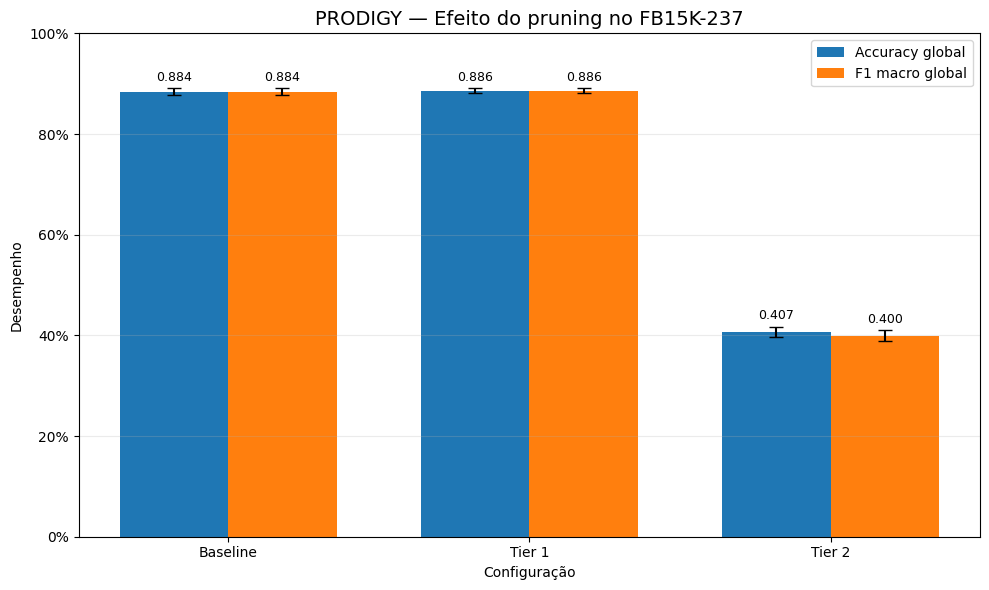

: 

In [ ]:
from matplotlib.ticker import PercentFormatter

plot_df = summary_df.set_index("Configuração").loc[
    ["Baseline", "Tier 1", "Tier 2"]
]

labels = plot_df.index.tolist()
x = np.arange(len(labels))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

accuracy_means = plot_df["Accuracy média"].to_numpy()
accuracy_stds = plot_df["Accuracy desvio padrão"].to_numpy()

f1_means = plot_df["F1 macro médio"].to_numpy()
f1_stds = plot_df["F1 macro desvio padrão"].to_numpy()

bars_acc = ax.bar(
    x - bar_width / 2,
    accuracy_means,
    bar_width,
    yerr=accuracy_stds,
    capsize=5,
    label="Accuracy global",
)

bars_f1 = ax.bar(
    x + bar_width / 2,
    f1_means,
    bar_width,
    yerr=f1_stds,
    capsize=5,
    label="F1 macro global",
)

ax.set_title(
    "PRODIGY — Efeito do pruning no FB15K-237",
    fontsize=14,
)

ax.set_ylabel("Desempenho")
ax.set_xlabel("Configuração")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Valores médios acima das barras.
ax.bar_label(
    bars_acc,
    fmt="%.3f",
    padding=3,
    fontsize=9,
)

ax.bar_label(
    bars_f1,
    fmt="%.3f",
    padding=3,
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    "prodigy_pruning_comparison_fb15k237.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Destilação

In [11]:
from data.kg import get_kg_dataloader

train_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="train",
    node_split="",
    batch_count=CONFIG["dataset_len_cap"],
    **loader_kwargs,
)

print("Tipo do train_loader:", type(train_loader))

try:
    print("Quantidade de batches:", len(train_loader))
except TypeError:
    print("Quantidade de batches não disponível via len().")

# Inspecionar um batch sem armazenar todo o conjunto em memória
train_iterator = iter(train_loader)
first_train_batch = next(train_iterator)

print("\nTipo do batch:", type(first_train_batch))
print("Quantidade de elementos:", len(first_train_batch))

for i, item in enumerate(first_train_batch):
    if hasattr(item, "x") and hasattr(item, "edge_index"):
        print(
            f"Elemento {i}: grafo | "
            f"x={tuple(item.x.shape)} | "
            f"edge_index={tuple(item.edge_index.shape)}"
        )
    elif torch.is_tensor(item):
        print(
            f"Elemento {i}: Tensor | "
            f"shape={tuple(item.shape)} | "
            f"dtype={item.dtype}"
        )
    else:
        print(f"Elemento {i}: {type(item)}")

200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
Tipo do train_loader: <class 'torch.utils.data.dataloader.DataLoader'>
Quantidade de batches: 510

Tipo do batch: <class 'tuple'>
Quantidade de elementos: 9
Elemento 0: grafo | x=(1712, 770) | edge_index=(2, 1811)
Elemento 1: Tensor | shape=(3, 768) | dtype=torch.float32
Elemento 2: Tensor | shape=(18, 3) | dtype=torch.float32
Elemento 3: Tensor | shape=(2, 54) | dtype=torch.int64
Elemento 4: Tensor | shape=(54, 2) | dtype=torch.float32
Elemento 5: Tensor | shape=(54,) | dtype=torch.bool
Elemento 6: Tensor | shape=(1, 18) | dtype=torch.int64
Elemento 7: Tensor | shape=(1, 18) | dtype=torch.int64
Elemento 8: Tensor | shape=(1, 18) | dtype=torch.int64


In [12]:
import copy
# ============================================================
# 1. PROFESSOR: MODELO ORIGINAL, CONGELADO
# ============================================================
teacher = copy.deepcopy(model).to(DEVICE)
teacher.eval()

for param in teacher.parameters():
    param.requires_grad_(False)

In [15]:
from layer_pruner import PRODIGYBlockInfluencePruner
pruner = PRODIGYBlockInfluencePruner(teacher)

# Garantir que estamos usando o modelo original
teacher.eval()

# Calcular o Block Influence no conjunto de validação
df_bi = pruner.compute_bi(
    val_loader,
    device=DEVICE,
    angular=False,
    max_batches=CONFIG["val_len_cap"],
)

print("Block Influence calculado.")
print("Número de camadas avaliadas:", len(df_bi))

display(df_bi)

Block Influence calculado.
Número de camadas avaliadas: 4


,Bloco,Layer Index,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados,Métrica,Observação
0,M2,0,M2 - camada 1,MetaGNNLayer,0.438074,0.014283,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
1,M2,1,M2 - camada 2,MetaGNNLayer,0.720202,0.027197,100,1800,0,BI (1 - cosseno),M2 calculado apenas sobre o prefixo de supernós
2,S2,0,S2 - camada 1,SAGEConvSelfLoopsV2,1.012626,0.007985,100,172166,0,BI (1 - cosseno),Entrada projetada por lin_x antes da comparação
3,S2,1,S2 - camada 2,SAGEConvSelfLoopsV2,0.171255,0.002829,100,172166,0,BI (1 - cosseno),Entrada/saída da camada com ativação do bloco


In [16]:
from layer_pruner import PRODIGYBlockInfluencePruner
# ============================================================
# 2. ALUNO: MODELO ORIGINAL COM PRUNING TIER 2
# ============================================================
student_pruner = PRODIGYBlockInfluencePruner(
    copy.deepcopy(model)
)

# Utilizar o ranking de Block Influence calculado na validação.
student_pruner.set_bi_scores(df_bi)

student = student_pruner.prune_tier2()
student = student.to(DEVICE)
student.train()

SingleLayerGeneralGNN(
  (layer_list): ModuleList(
    (0): MultiLayerGNN(
      (module_list): ModuleList(
        (0): SAGEConvSelfLoopsV2()
      )
      (act): ReLU()
      (reset_mlp): Linear(in_features=512, out_features=256, bias=True)
      (reset_mlp_c): Linear(in_features=256, out_features=256, bias=True)
      (reset_mlp_m): Linear(in_features=256, out_features=256, bias=True)
    )
    (1): BgGraphToSupernodePropagatorCat(
      (proj): Linear(in_features=768, out_features=256, bias=True)
    )
    (2): MetaGNN(
      (gnn_layers): ModuleList(
        (0): MetaGNNLayer()
      )
      (gnn_non_linear): ReLU()
    )
  )
  (cos): CosineSimilarity()
  (initial_label_mlp): Linear(in_features=768, out_features=256, bias=True)
  (initial_input_mlp): Identity()
  (final_label_mlp): Identity()
  (final_input_mlp): Identity()
  (learned_label_embedding): Embedding(1000, 256)
  (txt_dropout): Dropout(p=0, inplace=False)
)

In [17]:
# ============================================================
# 3. VERIFICAÇÃO DOS MODELOS
# ============================================================
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


print("PROFESSOR")
print("Parâmetros:", count_parameters(teacher))
print("Parâmetros treináveis:", count_trainable_parameters(teacher))
print("Modo treinamento:", teacher.training)

print("\nALUNO — TIER 2")
print("Parâmetros:", count_parameters(student))
print("Parâmetros treináveis:", count_trainable_parameters(student))
print("Modo treinamento:", student.training)

assert count_trainable_parameters(teacher) == 0
assert count_parameters(student) < count_parameters(teacher)

print("\nProfessor e aluno preparados.")

PROFESSOR
Parâmetros: 2894723
Parâmetros treináveis: 0
Modo treinamento: False

ALUNO — TIER 2
Parâmetros: 2035266
Parâmetros treináveis: 2035266
Modo treinamento: True

Professor e aluno preparados.


In [18]:
def prepare_model_inputs(batch, device):
    # Copiar o grafo para impedir que um modelo altere
    # os dados usados pelo outro.
    graph = batch[0].clone().to(device)

    inputs = [graph]

    for item in batch[1:]:
        if torch.is_tensor(item):
            inputs.append(item.to(device))
        else:
            inputs.append(item)

    return inputs


# Obter um episódio de treinamento
test_batch = next(iter(train_loader))

teacher_inputs = prepare_model_inputs(test_batch, DEVICE)
student_inputs = prepare_model_inputs(test_batch, DEVICE)

teacher.eval()
student.eval()

with torch.no_grad():
    teacher_output = teacher(*teacher_inputs)
    student_output = student(*student_inputs)

y_true_teacher, logits_teacher = (
    teacher_output[0],
    teacher_output[1],
)

y_true_student, logits_student = (
    student_output[0],
    student_output[1],
)

print("Y_true do professor:", tuple(y_true_teacher.shape))
print("Logits do professor:", tuple(logits_teacher.shape))

print("\nY_true do aluno:", tuple(y_true_student.shape))
print("Logits do aluno:", tuple(logits_student.shape))

print("\nLogits do professor finitos:",
      torch.isfinite(logits_teacher).all().item())
print("Logits do aluno finitos:",
      torch.isfinite(logits_student).all().item())

print(
    "Formato dos logits compatível:",
    logits_teacher.shape == logits_student.shape,
)

print(
    "Rótulos compatíveis:",
    y_true_teacher.shape == y_true_student.shape
    and torch.equal(y_true_teacher, y_true_student),
)

# Retornar o aluno ao modo de treinamento
student.train()
teacher.eval()

Y_true do professor: (9, 3)
Logits do professor: (9, 3)

Y_true do aluno: (9, 3)
Logits do aluno: (9, 3)

Logits do professor finitos: True
Logits do aluno finitos: True
Formato dos logits compatível: True
Rótulos compatíveis: True


SingleLayerGeneralGNN(
  (layer_list): ModuleList(
    (0): MultiLayerGNN(
      (module_list): ModuleList(
        (0-1): 2 x SAGEConvSelfLoopsV2()
      )
      (act): ReLU()
      (reset_mlp): Linear(in_features=512, out_features=256, bias=True)
      (reset_mlp_c): Linear(in_features=256, out_features=256, bias=True)
      (reset_mlp_m): Linear(in_features=256, out_features=256, bias=True)
    )
    (1): BgGraphToSupernodePropagatorCat(
      (proj): Linear(in_features=768, out_features=256, bias=True)
    )
    (2): MetaGNN(
      (gnn_layers): ModuleList(
        (0-1): 2 x MetaGNNLayer()
      )
      (gnn_non_linear): ReLU()
    )
  )
  (cos): CosineSimilarity()
  (initial_label_mlp): Linear(in_features=768, out_features=256, bias=True)
  (initial_input_mlp): Identity()
  (final_label_mlp): Identity()
  (final_input_mlp): Identity()
  (learned_label_embedding): Embedding(1000, 256)
  (txt_dropout): Dropout(p=0, inplace=False)
)

In [21]:
import copy
from pathlib import Path

# Reutilizar os batches de teste já armazenados, caso existam.
if "cached_batches" in globals() and len(cached_batches) == 500:
    test_batches_kd = cached_batches
else:
    test_batches_kd = list(test_loader)

# Fixar os episódios de validação para comparar as épocas.
val_batches_kd = list(val_loader)

assert len(test_batches_kd) == 500
assert len(val_batches_kd) > 0

print("Batches de treino disponíveis:", len(train_loader))
print("Batches de validação fixados:", len(val_batches_kd))
print("Batches de teste fixados:", len(test_batches_kd))

# Avaliação anterior à destilação.
teacher_test_before, _ = evaluate_model(
    model=teacher,
    episodes=test_batches_kd,
    device=DEVICE,
    config_name="Baseline",
)

student_test_before, _ = evaluate_model(
    model=student,
    episodes=test_batches_kd,
    device=DEVICE,
    config_name="Tier 2 sem destilação",
)

student_val_before, _ = evaluate_model(
    model=student,
    episodes=val_batches_kd,
    device=DEVICE,
    config_name="Tier 2 sem destilação",
)

before_kd_df = pd.DataFrame([
    teacher_test_before,
    student_test_before,
])

display(before_kd_df)

print(
    "\nAccuracy de validação do aluno antes da destilação:",
    f"{student_val_before['Accuracy global']:.4f}",
)

Batches de treino disponíveis: 510
Batches de validação fixados: 100
Batches de teste fixados: 500


,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,Baseline,0.876000,0.141881,0.865477,0.157775,0.876000,0.876016,500,4500
1,Tier 2 sem destilação,0.425333,0.249405,0.376206,0.240122,0.425333,0.416261,500,4500



Accuracy de validação do aluno antes da destilação: 0.4356


In [22]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# HIPERPARÂMETROS DA DESTILAÇÃO
# ============================================================

KD_TEMPERATURE = 2.0
KD_ALPHA = 0.5
KD_LR = 1e-4
KD_WEIGHT_DECAY = 1e-5

KD_EPOCHS = 10
KD_PATIENCE = 3
KD_GRAD_CLIP = 1.0

# ============================================================
# DIRETÓRIO DOS RESULTADOS
# ============================================================

KD_OUTPUT_DIR = REPO_ROOT / "state" / "kd_tier2_fb15k237"
KD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_STUDENT_PATH = KD_OUTPUT_DIR / "student_tier2_kd_best.pt"

# ============================================================
# CONGELAR O PROFESSOR E PREPARAR O OTIMIZADOR
# ============================================================

teacher.eval()

for parameter in teacher.parameters():
    parameter.requires_grad_(False)

student.train()

optimizer = torch.optim.AdamW(
    [p for p in student.parameters() if p.requires_grad],
    lr=KD_LR,
    weight_decay=KD_WEIGHT_DECAY,
)

# ============================================================
# HISTÓRICO DO TREINAMENTO
# ============================================================

history = []

best_val_accuracy = -float("inf")
best_epoch = None
best_student_state = None
epochs_without_improvement = 0

# ============================================================
# LOOP DE TREINAMENTO
# ============================================================

for epoch in range(1, KD_EPOCHS + 1):

    student.train()
    teacher.eval()

    total_loss = 0.0
    total_ce_loss = 0.0
    total_kd_loss = 0.0
    num_batches = 0

    for batch_idx, batch in enumerate(train_loader, start=1):

        # O grafo é clonado separadamente para cada modelo.
        teacher_inputs = prepare_model_inputs(batch, DEVICE)
        student_inputs = prepare_model_inputs(batch, DEVICE)

        # ----------------------------------------------------
        # PROFESSOR: somente inferência
        # ----------------------------------------------------

        with torch.no_grad():
            teacher_output = teacher(*teacher_inputs)
            teacher_logits = teacher_output[1].detach()

        # ----------------------------------------------------
        # ALUNO: forward com gradientes
        # ----------------------------------------------------

        student_output = student(*student_inputs)

        y_true = student_output[0]
        student_logits = student_output[1]

        if student_logits.shape != teacher_logits.shape:
            raise ValueError(
                f"Logits incompatíveis: professor "
                f"{tuple(teacher_logits.shape)}, aluno "
                f"{tuple(student_logits.shape)}"
            )

        if not torch.isfinite(student_logits).all():
            raise FloatingPointError(
                f"Logits não finitos no batch {batch_idx}."
            )

        if not torch.isfinite(teacher_logits).all():
            raise FloatingPointError(
                f"Logits do professor não finitos no batch {batch_idx}."
            )

        # Os rótulos são matrizes one-hot de formato (9, 3).
        targets = (
            y_true.argmax(dim=-1)
            if y_true.ndim > 1
            else y_true.long()
        ).reshape(-1).long()

        # ----------------------------------------------------
        # PERDA SUPERVISIONADA
        # ----------------------------------------------------

        loss_ce = F.cross_entropy(
            student_logits,
            targets,
        )

        # ----------------------------------------------------
        # PERDA DE DESTILAÇÃO
        # Professor -> distribuição-alvo
        # Aluno -> log-probabilidades
        # ----------------------------------------------------

        teacher_probs = F.softmax(
            teacher_logits / KD_TEMPERATURE,
            dim=-1,
        )

        student_log_probs = F.log_softmax(
            student_logits / KD_TEMPERATURE,
            dim=-1,
        )

        loss_kd = F.kl_div(
            student_log_probs,
            teacher_probs,
            reduction="batchmean",
        ) * (KD_TEMPERATURE ** 2)

        # ----------------------------------------------------
        # PERDA TOTAL E ATUALIZAÇÃO DO ALUNO
        # ----------------------------------------------------

        loss = (
            KD_ALPHA * loss_ce
            + (1.0 - KD_ALPHA) * loss_kd
        )

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Perda não finita na época {epoch}, "
                f"batch {batch_idx}."
            )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            student.parameters(),
            max_norm=KD_GRAD_CLIP,
        )

        optimizer.step()

        total_loss += loss.item()
        total_ce_loss += loss_ce.item()
        total_kd_loss += loss_kd.item()
        num_batches += 1

    # --------------------------------------------------------
    # MÉDIAS DAS PERDAS DA ÉPOCA
    # --------------------------------------------------------

    train_loss = total_loss / num_batches
    train_ce = total_ce_loss / num_batches
    train_kd = total_kd_loss / num_batches

    # --------------------------------------------------------
    # VALIDAÇÃO
    # --------------------------------------------------------

    val_result, _ = evaluate_model(
        model=student,
        episodes=val_batches_kd,
        device=DEVICE,
        config_name="Tier 2 destilado",
    )

    val_accuracy = val_result["Accuracy global"]
    val_f1 = val_result["F1 macro global"]

    epoch_result = {
        "Época": epoch,
        "Loss total": train_loss,
        "Loss CE": train_ce,
        "Loss KD": train_kd,
        "Val Accuracy": val_accuracy,
        "Val F1 macro": val_f1,
    }

    history.append(epoch_result)

    print(
        f"Época {epoch:02d}/{KD_EPOCHS} | "
        f"Loss={train_loss:.4f} | "
        f"CE={train_ce:.4f} | "
        f"KD={train_kd:.4f} | "
        f"Val Acc={val_accuracy:.4f} | "
        f"Val F1={val_f1:.4f}"
    )

    # --------------------------------------------------------
    # SALVAR O MELHOR CHECKPOINT PELA ACCURACY DE VALIDAÇÃO
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0

        best_student_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in student.state_dict().items()
        }

        torch.save(
            best_student_state,
            BEST_STUDENT_PATH,
        )

        print("  Melhor checkpoint salvo.")

    else:
        epochs_without_improvement += 1

    # Parada antecipada
    if epochs_without_improvement >= KD_PATIENCE:
        print(
            f"\nEarly stopping: validação sem melhora por "
            f"{KD_PATIENCE} épocas."
        )
        break

# ============================================================
# RESTAURAR O MELHOR CHECKPOINT
# ============================================================

if best_student_state is None:
    raise RuntimeError("Nenhum checkpoint válido foi salvo.")

student.load_state_dict(best_student_state)
student.to(DEVICE)
student.eval()

history_df = pd.DataFrame(history)

display(history_df)

history_df.to_csv(
    KD_OUTPUT_DIR / "kd_training_history.csv",
    index=False,
)

print("\nTreinamento concluído.")
print("Melhor época:", best_epoch)
print("Melhor Accuracy de validação:", f"{best_val_accuracy:.4f}")
print("Checkpoint:", BEST_STUDENT_PATH)

Época 01/10 | Loss=0.2957 | CE=0.4627 | KD=0.1287 | Val Acc=0.9089 | Val F1=0.9091
  Melhor checkpoint salvo.
Época 02/10 | Loss=0.2492 | CE=0.3688 | KD=0.1295 | Val Acc=0.9011 | Val F1=0.9012
Época 03/10 | Loss=0.2433 | CE=0.3553 | KD=0.1314 | Val Acc=0.9100 | Val F1=0.9099
  Melhor checkpoint salvo.
Época 04/10 | Loss=0.2427 | CE=0.3522 | KD=0.1332 | Val Acc=0.9211 | Val F1=0.9212
  Melhor checkpoint salvo.
Época 05/10 | Loss=0.2318 | CE=0.3312 | KD=0.1324 | Val Acc=0.9256 | Val F1=0.9255
  Melhor checkpoint salvo.
Época 06/10 | Loss=0.2344 | CE=0.3338 | KD=0.1351 | Val Acc=0.9256 | Val F1=0.9256
Época 07/10 | Loss=0.2314 | CE=0.3291 | KD=0.1337 | Val Acc=0.9244 | Val F1=0.9245
Época 08/10 | Loss=0.2308 | CE=0.3259 | KD=0.1357 | Val Acc=0.9133 | Val F1=0.9134

Early stopping: validação sem melhora por 3 épocas.


,Época,Loss total,Loss CE,Loss KD,Val Accuracy,Val F1 macro
0,1,0.295682,0.462654,0.128709,0.908889,0.909057
1,2,0.249158,0.368792,0.129523,0.901111,0.901196
2,3,0.243320,0.355287,0.131353,0.910000,0.909942
3,4,0.242686,0.352206,0.133167,0.921111,0.921168
4,5,0.231800,0.331188,0.132411,0.925556,0.925487
5,6,0.234445,0.333761,0.135128,0.925556,0.925612
6,7,0.231421,0.329096,0.133747,0.924444,0.924549
7,8,0.230815,0.325922,0.135708,0.913333,0.913443



Treinamento concluído.
Melhor época: 5
Melhor Accuracy de validação: 0.9256
Checkpoint: C:\Mestrado\Graph_Pruning\prodigy\state\kd_tier2_fb15k237\student_tier2_kd_best.pt


In [23]:
# Avaliação final no conjunto de teste fixado.
# Não usamos o teste para selecionar épocas ou hiperparâmetros.

teacher_test_final, _ = evaluate_model(
    model=teacher,
    episodes=test_batches_kd,
    device=DEVICE,
    config_name="Baseline",
)

student_test_after, _ = evaluate_model(
    model=student,
    episodes=test_batches_kd,
    device=DEVICE,
    config_name="Tier 2 destilado",
)

comparison_kd = pd.DataFrame([
    teacher_test_final,
    student_test_before,
    student_test_after,
])

display(
    comparison_kd[
        [
            "Configuração",
            "Accuracy global",
            "F1 macro global",
            "Batches avaliados",
            "Exemplos avaliados",
        ]
    ]
)

# Recuperação percentual da diferença de Accuracy.
baseline_acc = teacher_test_final["Accuracy global"]
student_acc_before = student_test_before["Accuracy global"]
student_acc_after = student_test_after["Accuracy global"]

accuracy_gap = baseline_acc - student_acc_before
accuracy_recovered = student_acc_after - student_acc_before

if abs(accuracy_gap) > 1e-12:
    recovery_percentage = 100 * accuracy_recovered / accuracy_gap
else:
    recovery_percentage = np.nan

print(f"\nAccuracy baseline: {baseline_acc:.4f}")
print(f"Accuracy Tier 2 antes da KD: {student_acc_before:.4f}")
print(f"Accuracy Tier 2 após KD: {student_acc_after:.4f}")
print(f"Variação de Accuracy: {100 * accuracy_recovered:+.2f} p.p.")
print(
    "Recuperação da diferença para o baseline:",
    f"{recovery_percentage:.2f}%"
    if np.isfinite(recovery_percentage)
    else "Indefinida",
)

comparison_kd.to_csv(
    KD_OUTPUT_DIR / "kd_final_test_comparison.csv",
    index=False,
)

print("\nResultados finais salvos em:", KD_OUTPUT_DIR)

,Configuração,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,Baseline,0.876000,0.876016,500,4500
1,Tier 2 sem destilação,0.425333,0.416261,500,4500
2,Tier 2 destilado,0.927778,0.927768,500,4500



Accuracy baseline: 0.8760
Accuracy Tier 2 antes da KD: 0.4253
Accuracy Tier 2 após KD: 0.9278
Variação de Accuracy: +50.24 p.p.
Recuperação da diferença para o baseline: 111.49%

Resultados finais salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\kd_tier2_fb15k237


,Época,Loss total,Loss CE,Loss KD,Val Accuracy,Val F1 macro
0,1,0.29568,0.46265,0.12871,0.90889,0.90906
1,2,0.24916,0.36879,0.12952,0.90111,0.90120
2,3,0.24332,0.35529,0.13135,0.91000,0.90994
3,4,0.24269,0.35221,0.13317,0.92111,0.92117
4,5,0.23180,0.33119,0.13241,0.92556,0.92549
5,6,0.23444,0.33376,0.13513,0.92556,0.92561
6,7,0.23142,0.32910,0.13375,0.92444,0.92455
7,8,0.23081,0.32592,0.13571,0.91333,0.91344


Melhor época: 5
Melhor Accuracy de validação: 0.9255555555555556


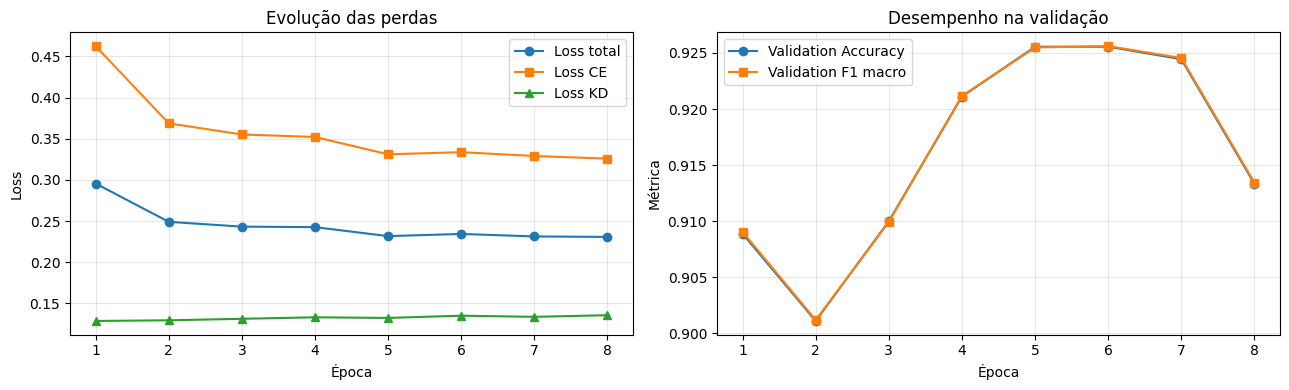

In [24]:
display(history_df.round(5))

print("Melhor época:", best_epoch)
print("Melhor Accuracy de validação:", best_val_accuracy)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["Época"],
    history_df["Loss total"],
    marker="o",
    label="Loss total",
)

axes[0].plot(
    history_df["Época"],
    history_df["Loss CE"],
    marker="s",
    label="Loss CE",
)

axes[0].plot(
    history_df["Época"],
    history_df["Loss KD"],
    marker="^",
    label="Loss KD",
)

axes[0].set_title("Evolução das perdas")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["Época"],
    history_df["Val Accuracy"],
    marker="o",
    label="Validation Accuracy",
)

axes[1].plot(
    history_df["Época"],
    history_df["Val F1 macro"],
    marker="s",
    label="Validation F1 macro",
)

axes[1].set_title("Desempenho na validação")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Métrica")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()